# TP2 — Sarcasme arabe : version T4 à ouvrir

**Ouvrir ce fichier T4 et fermer l'ancien onglet avant de continuer.** Cette version remplace l'ancien notebook dont l'onglet a réenregistré le code CPU. Les anciennes sorties ont été préservées dans `results/history/` ; elles ne sont pas attribuées aux nouvelles cellules.

Sur le serveur **GPU T4**, sélectionner Python 3 et exécuter depuis la première cellule. La préparation installe les compléments Python manquants ; après son message « Installation terminée », redémarrer le noyau puis recommencer depuis le début. La cellule des chemins récupère les CSV officiels même si le projet local n'a pas été transféré. Les poids exacts et AraVec sont préparés avant leur utilisation. Les ressources et les sorties distantes sont dans `/content/TP2_ArSarcasme`, sauf projet transféré détecté ou variable `TP2_ROOT` explicite. Ce stockage est temporaire : sauvegarder les checkpoints pour la reprise après perte de session.

Les architectures et expériences obligatoires A–G restent celles du TP, avec les 104 explications et le code scientifique visible. Sur GPU : batch PLM 32, AMP float16 pour E/F, poids maîtres float32 ; les autres familles restent float32. La partie G mesure la latence du CPU Colab. Sur le Conda local, le calcul CPU reste possible et les ressources présentes sont réutilisées.

Les tableaux et figures apparaissent dans VS Code et sont sauvegardés avec Ctrl+S. Les CSV et poids sont créés sur le serveur : les récupérer séparément. Les 24 résultats CPU locaux sont préservés ; aucun entraînement T4 ni Run All n'a été exécuté par l'assistant.

### Comment lire les explications de chaque cellule

Chaque cellule de code est précédée d’une fiche numérotée **001 à 104** : objectif, déroulement, résultat attendu lors de votre exécution et point d’interprétation. Les définitions de fonctions ne lancent pas leurs calculs ; les cellules qui entraînent ou infèrent sont signalées. Les exemples illustratifs ne sont pas des résultats expérimentaux.

Repères utilisés : `N` = nombre de tweets, `B` = taille d’un lot, `L` = nombre de positions et `d` = dimension d’un vecteur. **Train** sert à apprendre ; **val** à sélectionner ; **test** à évaluer une fois les choix verrouillés. Une ligne sans sortie peut être normale pour une définition. Ces ajouts sont uniquement documentaires : aucune cellule n’a été lancée pour produire les explications.

### Optimisations CPU conservant le protocole du TP

Les tests de vitesse ont utilisé **uniquement des tenseurs synthétiques et des forwards**, sans modèle préentraîné chargé, backward ou pas d’optimiseur. Le code conserve architectures, données, partitions, graines, lambda, époques et pertes. Les 24 mesures historiques restent inchangées ; aucune nouvelle métrique scientifique n’est produite par l’optimisation.

Réglages retenus : CPU float32, six threads intra-op et un inter-op, lots vectorisés à ordre/RNG conservés, padding dynamique et longueurs regroupées, encodages réutilisés, un extracteur gelé en cache, validation du meilleur checkpoint réutilisée. SDPA était déjà actif pour BERT ; il n’est pas présenté comme un gain nouveau. TorchInductor reste désactivé : le compilateur C++ requis est absent dans l’environnement Windows courant.

Les microbenchmarks ne mesurent pas le backward ni la durée complète. Ils ne justifient pas une promesse sous six heures. Détails, mesures et sources : `results/optimisation_cpu.md`. Démarrer dans un **noyau neuf** pour les réglages de threads.

# TP 2 Détection du sarcasme dans les tweets arabes

**Module Transformers et LLMs — ArSarcasm-v2 — réalisation reproductible en français.**
Ce notebook suit les parties A à G du sujet de Yassir Matrane. Chaque résultat affiché provient
du calcul placé sous son explication. L'objectif est une comparaison honnête, et non la recherche
d'un score élevé par consultation répétée du test. L'identité et le lien du dépôt distant sont
à compléter par l'étudiant ; aucun nom ni résultat n'est inventé.

Le F1 de la classe sarcastique est la métrique principale : $F1=2PR/(P+R)$, où
$P=TP/(TP+FP)$ et $R=TP/(TP+FN)$. Le corpus étant déséquilibré, un modèle qui répond
toujours « non sarcastique » peut avoir une accuracy élevée tout en ayant F1 = 0.
L'aire précision-rappel est calculée ici par **average precision (AP)**, convention précisée
dans les exports ; elle n'est pas l'intégrale trapézoïdale de la courbe PR.

**Exécution locale complète.** Tous les tweets d'entraînement admissibles sont utilisés.
Les PLM demandés sont les véritables checkpoints, sans substitution par un petit modèle.
Sur CPU, les entraînements prennent plusieurs heures. Chaque modèle et chaque cellule sont
sauvegardés ; relancer réutilise les expériences identiques déjà terminées.

Sources : [corpus officiel](https://github.com/iabufarha/ArSarcasm-v2),
[AraBERT Twitter](https://huggingface.co/aubmindlab/bert-base-arabertv02-twitter),
[MARBERTv2](https://huggingface.co/UBC-NLP/MARBERTv2),
[AraVec](https://github.com/bakrianoo/aravec).

### Cellule de code 001 — Importer les outils de base

**Objectif.** Préparer les bibliothèques utilisées dans tout le projet, sans encore lire le corpus ni entraîner de modèle.

**Comprendre le code.** `Path` représente les chemins de fichiers. `numpy` manipule des tableaux numériques ; `pandas` organise les tweets en tables ; `matplotlib` dessine les figures. PyTorch fournit les tenseurs, les couches et les lots de données. `Counter` servira à compter les tokens du train. Les variables `USE_TF` et `USE_FLAX` désactivent les autres moteurs avant le chargement de Transformers.

**Résultat attendu à l’exécution.** Ces objets deviennent disponibles dans le noyau Python. Une cellule d’import réussie peut ne produire aucune sortie visible.

**À retenir.** Importer PyTorch ne signifie pas entraîner BERT. Une erreur `ModuleNotFoundError` indique un problème de noyau ou de dépendance, pas un défaut du jeu de données.

**Optimisation CPU ajoutée.** Six threads intra-op sont configurés avant NumPy/PyTorch via OMP et MKL ; la précision reste float32. Aucun réglage GPU ou BF16 n’est appliqué.

**Préparation automatique dans Colab.** Avant les imports scientifiques, la cellule vérifie les versions des compléments du TP (`emoji`, `arabert`, Gensim, Transformers, etc.). Elle installe seulement ceux qui manquent ou diffèrent des versions prévues, avec le Python du noyau courant. Elle ne demande aucune installation de PyTorch, CUDA, NumPy, pandas ou scikit-learn. Après une installation, elle s'arrête volontairement avec le message « Installation terminée » : redémarrer le noyau pour ne pas mélanger des modules déjà importés et de nouveaux fichiers. Lors de la relance, les versions conformes ne sont pas réinstallées. Ce bloc ne s'exécute pas dans le Conda local. Aucun modèle n'est entraîné et aucun poids de PLM n'est chargé par cette préparation.

**Compatibilité Python 3.13.** Le runtime sélectionné peut utiliser Python 3.13 : les anciens épinglages `safetensors==0.4.3` et `sentencepiece==0.2.0` ne fournissent pas de wheel Linux correspondante. Le complément Colab utilise donc `safetensors==0.5.3` et `sentencepiece==0.2.1`. Les poids, architectures et hyperparamètres du TP restent identiques. Pour les extensions compilées, `--only-binary` exige un paquet déjà compilé et évite une construction locale C++/Rust ; le paquet Python pur `emoji==1.4.2`, requis par AraBERT, reste autorisé depuis ses sources. La sortie pip est récupérée avec stderr puis affichée entièrement. Un code de retour non nul signifie une installation échouée : lire les lignes `ERROR:`. Le message « Installation terminée » n'apparaît qu'après un retour zéro et demande le redémarrage du noyau. La vérification locale des wheels ne remplace pas une installation réelle dans votre session distante.

Sources : [SentencePiece 0.2.1](https://pypi.org/project/sentencepiece/0.2.1/), [safetensors 0.5.3](https://pypi.org/project/safetensors/0.5.3/).


In [1]:
from pathlib import Path

import os, sys, re, json, time, random, hashlib, gc, math, copy, platform, warnings

IN_COLAB = bool(os.environ.get('COLAB_RELEASE_TAG')) or Path('/content').is_dir()

if IN_COLAB:
    print('TP2_COLAB_BOOTSTRAP_V2 — préparation compatible Python 3.13',flush=True)
    from importlib.metadata import version, PackageNotFoundError
    import subprocess
    # Copie autonome des dépendances, synchronisée avec requirements-colab.txt.
    COLAB_REQUIREMENTS = ['transformers==4.48.0', 'huggingface-hub==0.29.1', 'safetensors==0.5.3', 'tokenizers==0.21.0', 'gensim==4.4.0', 'arabert==1.0.1', 'pyarabic==0.6.15', 'emoji==1.4.2', 'sentencepiece==0.2.1', 'nbformat==5.9.2', 'reportlab==5.0.1', 'pymupdf==1.28.2', 'requests==2.32.3', 'pyflakes==3.0.1']
    missing=[]
    for specification in COLAB_REQUIREMENTS:
        package,wanted=specification.split('==',1)
        try: installed=version(package)
        except PackageNotFoundError: installed=None
        if installed!=wanted: missing.append(specification)
    if missing:
        print('Préparation Colab — Python',sys.version.split()[0],':',', '.join(missing),flush=True)
        # Ces extensions doivent avoir une wheel : éviter une compilation C++/Rust.
        command=[sys.executable,'-m','pip','install','--disable-pip-version-check',
                 '--progress-bar','off',
                 '--only-binary=safetensors,tokenizers,gensim,sentencepiece,pymupdf',*missing]
        installation=subprocess.run(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                                    text=True,errors='replace')
        print(installation.stdout,flush=True)
        if installation.returncode:
            raise RuntimeError(f"Échec de pip (code {installation.returncode}). "
                               "Copier les lignes ERROR affichées ci-dessus pour le diagnostic. "
                               "Ne pas poursuivre les cellules scientifiques.")
        raise RuntimeError('Installation terminée : redémarre le noyau Colab puis relance depuis la première cellule.')

CPU_THREADS=min(2,os.cpu_count() or 1) if IN_COLAB else 6  # 12 testés : gain forward limité, backward non mesuré.
os.environ['OMP_NUM_THREADS']=str(CPU_THREADS)
os.environ['MKL_NUM_THREADS']=str(CPU_THREADS)
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
os.environ['USE_TF']='0'
os.environ['USE_FLAX']='0'
from collections import Counter

from datetime import datetime, timezone

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display, Markdown, HTML

import torch

from torch import nn

from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler, RandomSampler, BatchSampler

from sklearn.model_selection import train_test_split

TP2_COLAB_BOOTSTRAP_V2 — préparation compatible Python 3.13


### Cellule de code 002 — Charger les outils NLP et fixer les chemins

**Objectif.** Respecter l'organisation du dépôt demandée dans le TP et utiliser uniquement ses ressources locales.

**Comprendre le code.** Les métriques évaluent les prédictions ; `Pipeline` et `FeatureUnion` construisent la baseline ; les classes `Auto*` ouvrent les poids locaux. `ROOT` désigne la racine du dépôt. Si le noyau démarre dans `notebooks/`, le bloc remonte d'un niveau ; s'il démarre à la racine, il y reste. `DATA_DIR = ROOT/'data/raw'` indique l'emplacement des deux CSV officiels. Les autres fonctions construisent leurs chemins sous `ROOT`, par exemple `models/hf/` ou `results/results.csv`. Les assertions détectent des données ou poids manquants avant les calculs.

**Résultat attendu à l'exécution.** Les chemins du dépôt sont prêts sans chargement de modèle, téléchargement ni apprentissage. Les chemins de checkpoints enregistrés sont relatifs à `ROOT`, ce qui permet de déplacer l'ensemble du dépôt.

**À retenir.** Ouvrir VS Code à la racine contenant `src/`, `notebooks/`, `data/` et `requirements.txt`. Le notebook reste la source pédagogique visible ; les modules exportés servent aux tests et à la reproductibilité. Aucune ressource n'est recherchée dans un dossier voisin.

**Sur Colab.** Les chemins Windows ne sont pas accessibles au serveur. Transférer le projet complet via « Upload to Colab », ou transférer le code puis préparer les ressources avec les scripts officiels. Si le dossier courant est `/content`, un unique projet enfant est détecté ; sinon définir `TP2_ROOT` avant les imports. Les assertions s'arrêtent avant tout apprentissage si données ou poids manquent.

**Session Colab vide.** Le noyau distant ne voit pas le disque Windows. Un petit paquet intégré fournit les scripts de préparation et les manifestes exacts, sans poids ni données. L'archive est contrôlée par SHA256 et extraite seulement sous la racine choisie, sans écraser les fichiers existants. `prepare_data` télécharge les deux CSV officiels et contrôle leurs SHA256, sans consulter les labels test. Avant B, `prepare_models` récupère les quatre révisions Hugging Face épinglées et vérifie leurs poids. AraVec est préparé à son étape C. Aucun de ces téléchargements n'entraîne de modèle. Les sources de ces opérations sont lisibles dans `src/colab_resources.py`.

In [2]:
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import FeatureUnion, Pipeline

from sklearn.linear_model import LogisticRegression

import joblib

import emoji

warnings.filterwarnings('ignore',message='This pattern is interpreted as a regular expression, and has match groups')

from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

from transformers import get_linear_schedule_with_warmup, set_seed

# TP2_LAYOUT
ROOT = Path(os.environ.get('TP2_ROOT',Path.cwd())).resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if IN_COLAB and not (ROOT/'data/raw/training_data.csv').is_file() and 'TP2_ROOT' not in os.environ:
    candidates=[p for p in ROOT.iterdir() if p.is_dir() and (p/'src/preprocess.py').is_file()]
    ROOT=candidates[0] if len(candidates)==1 else Path('/content/TP2_ArSarcasme')
if IN_COLAB:
    import base64, io, zipfile
    BOOTSTRAP_ARCHIVE = 'UEsDBBQAAAAIAL25UV0AAAAAAgAAAAAAAAAPAAAAc3JjL19faW5pdF9fLnB5AwBQSwMEFAAAAAgAvblRXSsRn7MgAwAAvAYAABEAAABzcmMvcHJlcHJvY2Vzcy5weY1UzW7TQBC+R8o7TOlhbZG4pMegAKEUiKAtauGUBGuxJ8lSe73aXRNKQeKG+Dlw4sAFCYRQDyB4hr5EIl6GsZ3mr5VCJNuT3ZlvZr75WYc7pyfy9ESfnoDiGtSRHSQSqjEYHXjmSAYQokqFgQhBJhafJMkhXIU4CUVPoJ4/9solEatEW9BYgYGNowqkUgRJiCG3fHqLcfJUlEu3Ws0taJCuFySxEhE6mrVHH6ujz+P31fGX8e+/n6p/f3aZWy492r/v728vKw+sVeZ6fWOjc3D55XA47HgksEqm1CKjne3dh6293QsMb7Q7Q797OUNu7jdvtrb8neYDUjJWezE/RKu5NM4xG31jdTb6wSps9H0qfT2Txn+m0luSxu/YKwIMsQf4PMvTDyLk0rH43Lr1cgnol8nkZ44UTyY65pF4gQ7bvb3FCt68VKIJuEKHQioQXNcjWSjHLaDW4ZFEMJhSARQXGsmrpToKTEluHmy1WlQmmV0aMKlSWsR5uQwEwnIrEmlASIuaXFGNIWI8tWTsFfiiR7qT6K/VgMswj56C4NqaobADh11i7uwCZTg7nuQ7l3P2adfq1Vp3MQ+NNtUyq49Jn2Qd0Ek3r1zB/N3L3pu8mn/oqIe9XpcoYvTkgZVLBeFhqiIRcIv+IR4tML4M3zFZhzCgV9Z/+SnBna+Y62lUEQ+oLuPXVGPmenlbROTFmXXNfFmKWBTZcY1+hpJDVbJhwQYLiHHUz4j6Z0juQ50oPxLy0DRu88jgUo+cj2halwwO1hrAVBSz80zP55Ub/mcmC+6LiStgiC7yOosXkMKlQ9J5uHdvexcmfhYAZtO3AuRge/8ClLM0G5Qm7/c1GpPRdj7bfJl4fbR+Lvka+0Sd4555nQedM5s2xPjN8Wbl1cvRr+xz1horbBzP7dQm+tRStdUW7cedYcd0L8Bfh7vcDCzvG6gDtYhFmcKkVWgn0wgL2kuJGiY6NMUfjGMh++DQ2u7ng7wRCh5hYGnYaY8Xlsb1Vk1A0RxL7YuaG/SDFM1Fm2sl27N9tWD333QvR+u0166PvnijD12ifCHwcukfUEsDBBQAAAAIAL25UV35nQvYgQMAAGwJAAAXAAAAc3JjL2FyYXZlY191dGlsaXRpZXMucHnNVklv4zYUvutXvMhAJSGyYqcb0IEnnRYY9NIeirmZqqDItMNGolSSjqdz6q2p0f8QoEUR9B/Z/6aPi7Zs6KVAjfCR4lv5vQWZwOK5nzcxPPiGlg0V8C1VV/VKWnmPVU0tFAjanvi2an6GXAJvvLWoK+CluoaWuRF5JT20+HVJc372XS2qvGQfKLwR+SUr4B19r7wVXUOh+ZlUIlR4FX3hAf4kzUVxBQtY+oc//dg//KXJH5r8jSTDNcV1hivRl78jgeMtmG1/uMdD4Aexf/wFbwJcx9+QEILXhAcxBEQFcfDRT9tavcLDBa7DHZKTIDX+BW3KvKA2gHvtoSPHX7UTt7o/dN76Hl4f92YPQPtEYteFoYc7s52A82nIRNCqvqGgcnl1TWlpLpus/cSABE2KumpYSUMRLMl29tn886nZ3mj6yVfm49PzNIiMskbVqsntZdib0nEZZvTYe1nzTa5YzZ377vuh/zCJyPzUeUL70rjyyZzM/Se9d5ZiK/4oBKegt8RlIQyOt8dbjSDS6AWp/XFvpPYvSR3uD/daCunA7boWwIBxEDnf0HAWQ0l5aMswckX5nEkrtWRp3NYNnoeoKsGqJx+IVc+aMPJczamt4Ibhmc7YUJXd0CLkWVWvMGErViFc9TXlLiBkoiXeJB+oqGWIfOuVycyy3ualpPZqbTWB10o/09lMdjf927Ki3nId26y76iy9E1va3WqwdtqKMZnIpmQqxKYc4OR87p7z9cDn6QLmj3jaMzJ69eUu7SNbt7qvYTa2ayPW9MzJGDZFLHpBh11v27wlHWYCRWwiirwsTCaaWmZGTsbA6aY/uwyBTsHLudHYNRqV3tY4KHzxU4lvenVuQO3cj9WnT6vzQT32z9M33mQC0yl8T7EWKfZ+XpZuehtnuS1Y9HhJ1Y5iBeUgG1qwNQ5x0yxdraJmZjXNKEdYDH/xsYNkPAv08IpJQl6RkERkSVKSkVMyIV+SE3JBDnfkh9QNzcGIsC/WY9lWs47Qnhh3LWWLEfyoq/m2zeBkAb5vU8w3xko6BtU2/3lsAz+dDwpaK2BqlnxjxTcmCe61bRlEo/pZYkskP9aMh3wTjbSkjk0PGGS8nkH675MwAJ93wI9BX5z/f/H+T9Fbs1Lhvy3qigJ9z6Siqzb+MXCmKzrwnKhrpvBBSzso25iQ22LQzT/pHj4edTos7x9QSwMEFAAAAAgAvblRXfsmfnl6BgAAaBEAABYAAABzcmMvY29sYWJfcmVzb3VyY2VzLnB5pVfbbts2GL7PU2i5odTKchtgw+BCF2nXYhfpFrRZLxYYAi1RNheKVEnKTlr0fZbnyIvt50kH21nbzUAbiof/+P0/P56enl7Kh/sWSyIjRlQkiVKikyUM227F6McORrCB8jV7uIdx1UVXl2mkMFdRucFyDQcrEjWievibkez09PSklqKJWqw3jK4i2rRC6ugSPt3CJ9rWlJGw8Cdt38Dnif/cYGWOhc+/lOBh3EkGK5kkxiZ9cnJSkTqq6Bo+YqMtWZxE8NtRvbHq3GQmWsJjJFcoibCKlJYEN26n+UmiO8mD2sxYVniZbmuK1Aaf/fgTSrINufVLSdAudpwJXBVbImlNSRWDkak2UdEpuW1JqUnl7XKzubXMjZMXfjIz8ec6a24qKmP3ofIr2REQQpUuxI39SqwgWodjdlHFyeAO7SPiVfyQBzMWkcRUkegDZh15LaWQcY3e/3oOvkWUl0JK2BYtos/u5BeU7AfJLdhZsFFTzHJviIl5wXFDvNrMjJ8i45f2clpJuY7R1cM94MgBpwE3I1HXtKSERQuUjg6nNevUZuT1NPsZfIJVkpItsTH3BvUR6nHhpv9DGPzREAf/CQa0DJfBUbc2jY+DRgsbIZFFhTWOpRDaZ8kMHQjsJMhTgoETTlItJPxjFRQV5dE1MqfnEu9Q6oatFFCailQwASVHmIIBiOiYNiNQWtFSU8HNV03XHazBSMkS/mdirdByAIu1YO7UJd8IPoiOkJXKTWFmBvoqdmJ6U+cN5rQ2OTJ7kPEQCkSTWx0TiG8FnSRHna5nP6NkcNrJNU57DYOZvnCcGrd6jUxto+V++HzyudChRKgqJGFY0y0ptNgzFSVH0LCnoZd7WOthJ+APLUPVh0nfNZYT9P8iOLddNKDetNyKqlZwurJjbDK3Z+WkFqbochgY48v22E23XkOcawBqsen6Jqw4btVG6CL48g2IlGRLlQHUkZQ77fN+y3dl3Fb5OO1BCNWkmTQ1h9B8onNTo7mR0NcjmgPCZzN0AAR3evDqOCQGsccwYTQNgs0lYWZy1N5pIcuNS0O2ohxZrbDmyvePl69mv11czt+ev3v5+t3V9gxsfHX+llzMLvBqviJSz1ZYkRmWeEXLWQkHmZ2t8ExBHVLTItEyAtNI5GzMFK6JJlwJqVBv0o7Q9Ubnztd5MPAFXHe4acM00u1ZcQBjl7Sh2sQN4fQTkYWRonJActtkVjUY36+6UynCVUUg12bap38ZQpCBcqmVuRti9FZIqj9dYGhIYEjiPLpGW1HiVaZvwcnRbfOxo9DI8mtvd2vx0rqQloJDXwvqB2un8wqaPXRrb1jR4NavPNnzb7l8eu2CNxig5d0CCM4WTBhh3oZyBO0kMY662XARO7c+f+lFkduStDqKf39vgZQOmEqCitFukIcZi1sDUWMdCOw9D1EBFsMrdzSDfgPMxhcOSvI8NJ9+brm/O5CZYW9oVEO9eVNGp1Z3Gu4ROORCZTILAYA/hYJQ7utoDG4LfvxAWFxEkDFNeUf2C/brIZia6nur57HY3H6GpV5evDWcwrYZBGs+IulhjA64Rvgd9Eto+a0oaJX75uUkHAl7ygDYDJik9MWXWtzlbzAAJG3wbbET8oZIlZ+lE5XmBwEQuwLuH00kNxX4PzF/ULUHGvd/o7pMJ/V/WO5paDbLSef1/MulH+jXAdqO0bBLQSsFGOAGG5D2Bm5EYGJG+piOVhLXOneVZ5mn6uA6vY2RtSjTTbu/OdtB9yGubu2eqmtaFX8eMrY4ksNg7GLf+GkAfXUsjtZGOlTD4Yaw9CVJDy7KPQfCNWe9dovTmwsDK9QKING0DO6HcBU/5rgnjwsGjSvu797kUUt8kV1ARj52GF5Gtr5Aop7wF6Kj7cO9uVge7tXklWjJPuFR83DfCKji7N9oDZTxlpTfRJvDG2pKD5wA1D+wHLk9wmdNc7FnTIPxm+WaiVWMnmRNxdD0cWV6k7UCHoexPZc8dehL9jqWm3V3VrbbZmAOcAWV8fYO6ijTAH+OTcwydcefc7K2K0vDPuxrYsS2H2dezs3iexj39TN30WHgLYYBGZqbf43bTpTWHWNFx2lRrqBNPX/2rNBQhdCrMnjao0cIsH2V+7d+PNZtX+V+Ykz5ZE+j/KJ9Flq4JgdXlbk2/IvMssLkcbrn321fJXlBK0RR4lKbxI+ffL4eziX+QMrIbqLa03f/EhjD+x9QSwMEFAAAAAgAvblRXT6TFKL7AQAALwQAABUAAABtb2RlbHMvcmV2aXNpb25zLmpzb26Vk89u2zAMh+8F+g5FzhNC6i+1W9vtlgxDsT0AJVGLATsZHCcbVvTdJ7dFW2xZgF0MSCA/+/eZvL+8uLpa8CEN3bb0nJZJxkkl3ovikefDEbSafnTTJOPi/dX9XN86vvO0acfFsCvS75ebunxlKHUW8u4ZMcqx23e77YyBIjlrCR69DxVYODBH66znwo6NZi8uJXpp3m9YOz+3YpDqY/USkXzWaDUQY7VIQbAgiK8MMSQLKRnDJUGq5Ay6XIIIusVMfHjkLr7e3KpPq8/L9fXdzce7L0d9NvFztVKv5aeyVSEqKZZEObe3ZyvodbDRVQsuW8uuUgTvT2RzxVjODL5EydoYIUvGBqos2ZrcLGXCWFDYVjI1x1hiJvCh5EqJ09ts693YTb9WfBhlXA4fZP5iVkfz9J9+bvtODYd+6vpu++3AvZov9ND14ayDt1Sl/gt7ylVyiEaSIU7eSC0lVE1QKaO1wpTQ1BgoywlXTYXoWBHRRfIFjJaoE9TEDKlIRfCara/eUQIK4Ko2IYMDtEzO4ltXt9drWanVX+vQZZV5kP7xtrDay3bqhvY46+iF9udi/Bt30g2U6g0UbcTxPDRtLTxg8OCMCbVFpuYslxNuhIKJGKUthsyjZlp+DhHbBhSOhVN2obkyDZWrD1jiPGQeBLSBDPnJzeXFw29QSwMEFAAAAAgAvblRXSn88IghAQAA+wEAABsAAABtb2RlbHMvYXJhdmVjX21hbmlmZXN0Lmpzb26NkMtOwzAQRfdI/Yco6yqxHdu1+ysERX6MiSGNI9tpVBD/TkIpmyLEZjZz75XOedw9FMX7doqinONQHouyz3lKx7rW6jV6NYZQwRJxdZ6HHIN+AZNTZcKpVlGdwdRuHoZuHn1ndFg6jFCXF58zxOrNT+X+e3tSud/GT8HCkNr2fy19yZDWmuSEMCwadnukXhHGt0EnKbCDZthYpNcUN1QyRjQgbQlypkFWA5fcHQyjTGAsELWWE04NUxaJclv82P/hIaqleva5n/WcIJowZhjzl4EfQzcXJ5VWhHrOfvDZQ6qmy52BFE3bXvPdr8EbNKGY3PMCkZIpJ5xUSgt7UA2nQBSizohVERAAwwxrkOaiMUpr53BjZSM4WLtSX3l3D0+fUEsDBBQAAAAIAL25UV0k1Rpb/QAAABYCAAAWAAAAZGF0YS9yYXcvbWFuaWZlc3QuanNvbrWQzWrDMBCE74G8g/E5jVd/Kym3PkOPpZSVLMWG2gmSnFJK370WbQ6ltPTSy7LMDDPw3W83TfNaT9O0S3pqD007lHLOh65L9Lw/jmVY3JJD8qe5hLns/WnqRnJLpDRQd5vuKHnK082FdxON81elpFUa5+NjT4X2Pl/a3efWmcpQx6pRl36JupcS8prlwgqG5irngbjC2sF60lwHp1FIZaMU6GVAFhX3SOA8il4JAIomem+tU6gVBYkMewogqa2Nb7t/RhFy+SOJn5JXEMooMOw7B4hAWjsyJAnICg1GIkm+voSCSwmWRxadWE2wyiqnITAd+MrER/QfHLabh3dQSwMEFAAAAAgAvblRXVj1QAVHAQAA6AEAABYAAAByZXF1aXJlbWVudHMtY29sYWIudHh0JZExbsMwDEV3n4JA5gqJkxRJAQ9FOhbdegBZph02suRQVNH2RMk5fLFSDqBB+vz/kZJWcIrj5Of7iEFgiplV8LaFF3AxJORvZEgxgER2Zzh9vr0CCiRM0FLrKcp5vl2zHkMe5ztT2ZtqBR8Ik01AIYn1XiGM10yMpU8y8iPgo7MeOhsSOBTBAk2krTrSTBAsmHcl6whFT8DzHZW1jJqFPCUVkuY4qoKBcdAoL+JkGbyFDjnQfGPUHt5nr1BhbdlHHhXbNDuzO5h1dc7DQGHorcOnc26bZm3qo9lUyfYoGFIs3rXZm20l8YKB/vCh1BtND+qgcYHpybJtkaVptKSI6bcI5Ir72Wz2FY7xi0p1Z+oq6WUwOJwIHS5AjYS2zGcVsTdHNTFOkUW/pQgP5pinri+Q+rAYyruLTlSbrS419N5eUIXtEvgHUEsBAhQAFAAAAAgAvblRXQAAAAACAAAAAAAAAA8AAAAAAAAAAAAAAIABAAAAAHNyYy9fX2luaXRfXy5weVBLAQIUABQAAAAIAL25UV0rEZ+zIAMAALwGAAARAAAAAAAAAAAAAACAAS8AAABzcmMvcHJlcHJvY2Vzcy5weVBLAQIUABQAAAAIAL25UV35nQvYgQMAAGwJAAAXAAAAAAAAAAAAAACAAX4DAABzcmMvYXJhdmVjX3V0aWxpdGllcy5weVBLAQIUABQAAAAIAL25UV37Jn55egYAAGgRAAAWAAAAAAAAAAAAAACAATQHAABzcmMvY29sYWJfcmVzb3VyY2VzLnB5UEsBAhQAFAAAAAgAvblRXT6TFKL7AQAALwQAABUAAAAAAAAAAAAAAIAB4g0AAG1vZGVscy9yZXZpc2lvbnMuanNvblBLAQIUABQAAAAIAL25UV0p/PCIIQEAAPsBAAAbAAAAAAAAAAAAAACAARAQAABtb2RlbHMvYXJhdmVjX21hbmlmZXN0Lmpzb25QSwECFAAUAAAACAC9uVFdJNUaW/0AAAAWAgAAFgAAAAAAAAAAAAAAgAFqEQAAZGF0YS9yYXcvbWFuaWZlc3QuanNvblBLAQIUABQAAAAIAL25UV1Y9UAFRwEAAOgBAAAWAAAAAAAAAAAAAACAAZsSAAByZXF1aXJlbWVudHMtY29sYWIudHh0UEsFBgAAAAAIAAgAGQIAABYUAAAAAA=='
    payload=base64.b64decode(BOOTSTRAP_ARCHIVE)
    assert hashlib.sha256(payload).hexdigest()=='e06f5dd5e5204f08e44fe86fda703ed311dfb836bf553d63173d8207c3acff0c'
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        for info in archive.infolist():
            target=(ROOT/info.filename).resolve()
            assert target.is_relative_to(ROOT), 'Chemin de préparation invalide.'
            if not target.exists():
                target.parent.mkdir(parents=True,exist_ok=True); target.write_bytes(archive.read(info))
    if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
    from src.colab_resources import prepare_data, prepare_models, prepare_aravec
    prepare_data(ROOT)
DATA_DIR = ROOT/'data/raw'
assert (DATA_DIR/'training_data.csv').is_file(), 'CSV manquant dans data/raw/. Sur Colab utiliser le notebook T4 depuis la première cellule.'
assert (DATA_DIR/'testing_data.csv').is_file(), 'CSV officiel manquant dans data/raw/.'
print('Dossier du projet :',ROOT)


Téléchargement officiel : training_data.csv
Téléchargement officiel : testing_data.csv
Données officielles disponibles dans /content/TP2_ArSarcasme/data/raw
Dossier du projet : /content/TP2_ArSarcasme


### Cellule de code 003 — Choisir le matériel et les paramètres communs

**Objectif.** Définir un budget compatible avec les 16 Go de RAM installés et organiser les emplacements de sortie.

**Comprendre le code.** `mkdir(..., exist_ok=True)` prépare les dossiers du dépôt local sans effacer leur contenu. `DEVICE` utilise CUDA si disponible ; une session Colab sans GPU provoque une erreur explicite. Six threads correspondent au réglage retenu sur le Ryzen 5 5600G. `SEEDS` fixe les trois répétitions finales, `MAX_LEN=64` limite les séquences et `BATCH` vaut 32 sur GPU et 16 sur le CPU local ; les lots statiques restent de taille 64. `TOKENIZERS` est un cache en mémoire.

**Résultat attendu à l’exécution.** Les variables de configuration sont définies ; cette cellule ne lance aucun entraînement.

**À retenir.** La présence d’un GPU Radeon intégré ne suffit pas à fournir CUDA. La longueur 64 est un choix de budget aligné sur le préentraînement Twitter d’AraBERT ; son effet sera mesuré par les taux de troncature, pas supposé négligeable.

**Optimisation CPU ajoutée.** Le périphérique est maintenant explicitement CPU. Intra-op=6, inter-op=1 ; le réglage inter-op demande un noyau neuf. Les autres budgets, graines et tailles de lots restent identiques.

**T4.** Les fine-tunings PLM utilisent AMP float16 avec poids maîtres float32 ; les autres familles restent en float32. Cette précision et le batch sont journalisés et entrent dans la compatibilité des checkpoints.

In [3]:
assert (DATA_DIR / 'training_data.csv').exists(), 'Conserver les deux CSV dans data/raw/.'

os.environ['USE_TF'] = '0'

os.environ['USE_FLAX'] = '0'

for folder in ['results','predictions','figures','models','data/processed','logs']:
    (ROOT / folder).mkdir(exist_ok=True, parents=True)

os.environ['TOKENIZERS_PARALLELISM'] = 'false'

TOKENIZERS = {}
TOKENIZED = {}  # Cache borné : quatre jeux de tenseurs CPU.
FROZEN_MODELS = {}  # Un seul encodeur gelé ; vidé avant tout autre chargement.

os.environ['HF_HUB_DISABLE_XET'] = '1'

torch.set_num_threads(CPU_THREADS)
if torch.get_num_interop_threads()!=1:
    try: torch.set_num_interop_threads(1)
    except RuntimeError: print('Pour appliquer inter-op=1, redémarrer le noyau avant Run All.')

def select_device(in_colab):
    if in_colab and not torch.cuda.is_available():
        raise RuntimeError('Colab sans CUDA : choisir un serveur GPU T4, puis redémarrer le noyau.')
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DEVICE = select_device(IN_COLAB)
PLM_PRECISION = 'amp_float16' if DEVICE.type=='cuda' else 'float32' 

SEEDS = [42, 43, 44]

MAX_LEN = 64

BATCH = 32 if DEVICE.type=='cuda' else 16

### Cellule de code 004 — Définir les budgets d’époques et la compatibilité des caches

**Objectif.** Fixer les règles communes de durée et empêcher la reprise de checkpoints provenant d’un autre contexte.

**Comprendre le code.** Les petits réseaux ont au maximum huit époques ; les PLM en ont trois ; `PATIENCE=2` autorise deux validations sans amélioration avant arrêt. `RUN_VERSION` identifie la logique expérimentale. `CACHE_CONTEXT` rassemble longueur, tailles de lots, versions et précision. Le manifeste `REVISIONS` précise les versions des quatre PLM ; leurs chemins sont recalculés à partir du dossier actuel.

**Résultat attendu à l’exécution.** Un contexte reproductible et un dictionnaire de ressources locales sont disponibles.

**À retenir.** Le cache économise des calculs, mais ne crée pas une nouvelle expérience. Une modification scientifique doit être accompagnée d’un changement de version et d’une réévaluation des caches concernés.

In [4]:
STATIC_EPOCHS, PLM_EPOCHS, PATIENCE = 8, 3, 2

RUN_VERSION = 'tp2-v1'

CACHE_CONTEXT={'max_len':MAX_LEN,'batch_plm':BATCH,'batch_static':64,
    'torch':torch.__version__,'transformers':__import__('transformers').__version__,
    'precision':'float32','protocol':'conservative-tp2-v1'}

if DEVICE.type=='cuda':
    CACHE_CONTEXT.update(device_type='cuda',plm_precision=PLM_PRECISION,cuda=torch.version.cuda,
        gpu=torch.cuda.get_device_name(0),numpy=np.__version__,pandas=pd.__version__,
        sklearn=__import__('sklearn').__version__)

REVISIONS = json.loads((ROOT/'models/revisions.json').read_text()) if (ROOT/'models/revisions.json').exists() else {}

for model_name,entry in REVISIONS.items():
    entry['path']=str(ROOT/'models/hf'/model_name.replace('/','--'))

### Cellule de code 005 — Définir la fonction de fixation des graines

**Objectif.** Centraliser l’initialisation des générateurs aléatoires utilisés par les bibliothèques.

**Comprendre le code.** `random.seed`, `np.random.seed`, `set_seed` et `torch.manual_seed` contrôlent notamment les initialisations et les tirages. `torch.use_deterministic_algorithms(..., warn_only=True)` demande des opérations déterministes lorsque c’est possible ; si une opération pose problème, PyTorch avertit au lieu d’interrompre systématiquement le calcul.

**Résultat attendu à l’exécution.** La fonction `seed_all` est définie. Son corps ne s’exécute que lorsqu’elle est appelée.

**À retenir.** Une graine facilite la reproduction sur une même configuration ; elle ne garantit pas des résultats identiques entre tous les matériels et toutes les versions. Trois graines servent à observer une partie de la variabilité d’apprentissage.

In [5]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); set_seed(seed); torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

### Cellule de code 006 — Initialiser la session et vérifier le noyau Conda

**Objectif.** Appliquer la graine de référence et rendre l’environnement réellement utilisé visible dans les sorties.

**Comprendre le code.** `seed_all(42)` initialise cette session. Les options pandas permettent de lire des tweets assez longs et les options matplotlib harmonisent les graphiques. `sys.executable` affiche le véritable interpréteur du noyau, ce qui est plus fiable que le nom du terminal ouvert. L’assertion finale contrôle la présence du chemin Anaconda local ou Colab attendu.

**Résultat attendu à l’exécution.** Un récapitulatif indique Python, sa version, PyTorch, le périphérique et le nombre de threads.

**À retenir.** Vérifier ce récapitulatif avant les calculs longs. Un terminal Anaconda local ou Colab ouvert ailleurs ne force pas automatiquement le notebook à utiliser cet interpréteur.

**Colab.** Le Python distant est accepté ; l’assertion Anaconda reste limitée à l’exécution locale. Le nom réel du GPU, CUDA, la précision et le batch sont affichés et enregistrés dans `results/runtime_hardware.json`.

In [6]:
seed_all(42)

pd.set_option('display.max_colwidth', 220)

pd.set_option('display.max_rows', 65)

plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})

print('Python :',sys.executable, '\nVersion :',sys.version, '\nPyTorch :',torch.__version__,
      '\nPériphérique :',DEVICE, '\nCœurs utilisés :',torch.get_num_threads())

assert IN_COLAB or 'anaconda3' in sys.executable.lower(), 'Utiliser Conda local ou le noyau Colab.'
if DEVICE.type=='cuda': print('GPU :',torch.cuda.get_device_name(0),'— PLM :',PLM_PRECISION,'— batch :',BATCH)
(ROOT/'results/runtime_hardware.json').write_text(json.dumps({
    'training_device':str(DEVICE),'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
    'plm_precision':PLM_PRECISION,'batch_plm':BATCH,'cpu_threads':CPU_THREADS,
    'torch':torch.__version__,'cuda':torch.version.cuda,'platform':platform.platform(),
    'cpu_model':platform.processor() or 'unknown','logical_cpus':os.cpu_count()},indent=2))

Python : /usr/bin/python3 
Version : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0] 
PyTorch : 2.11.0+cu130 
Périphérique : cuda 
Cœurs utilisés : 2
GPU : Tesla T4 — PLM : amp_float16 — batch : 32


270

### Paramètres matériels et estimation

Machine ciblée : **Ryzen 5 5600G, 16 Go installés**, environ 13,9 Gio utilisables après mémoire réservée. PyTorch installé est CPU ; le GPU Radeon intégré ne fournit pas CUDA dans cet environnement. Six threads correspondent aux six cœurs physiques ; `num_workers=0` évite les processus Windows et copies supplémentaires. Batch PLM 16, FP32, trois époques maximales et patience 2 sont communs aux deux encodeurs. Le batch 32 du sujet est un point de départ ; 16 est retenu pour la marge mémoire, sans affirmer un gain de vitesse mesuré.

La longueur 64 correspond à celle du préentraînement AraBERT Twitter, **pas à une limite architecturale ni à une preuve d'optimalité**. Le nombre de textes tronqués est affiché pour chaque encodeur avant son entraînement. La valeur reste identique dans tous les runs comparables ; aucun raccourcissement n'a été ajouté pour atteindre six heures.

Les états gelés sont stockés en float16 sur disque ; le pooling moyenne convertit au plus 64 tweets à la fois en float32. Le padding dynamique et le groupement par longueur sont déjà utilisés en E. Aucun exemple n'est retiré pour accélérer. Les caches sont liés aux textes et aux versions. Les runs CPU terminés compatibles sont réutilisés avec leur durée historique.

Une machine CUDA exigerait une installation PyTorch CUDA séparée et une validation de sa VRAM. Le code actuel reste FP32 ; AMP serait une nouvelle configuration avec nouvelles signatures, à tester sur ce matériel. Aucun gain GPU n'est revendiqué comme mesuré.

## 1 Protocole des données et séparation imposée

Le fichier de 12 548 tweets est séparé en 90 % train et 10 % validation, avec stratification
sur le sarcasme et graine 42. Les identifiants sont ceux des lignes officielles.
Le sujet demande à la fois un audit des textes test et un test scellé jusqu'en F : nous
consultons maintenant **uniquement le texte test pour l'audit et l'exclusion des doublons**.
Les labels test et les taux par sous-groupe ne seront ouverts qu'en F. L'audit de leur
corrélation avec l'artefact sera donc terminé en F, sans modifier ensuite les modèles.

Les doublons sont comparés après une clé déterministe sans apprentissage. La clé retire
guillemets d'export, diacritiques et tatweel, normalise quelques variantes d'alif et espaces.
Elle garde le contenu des URL et mentions : deux tweets adressés à des personnes différentes
ne deviennent pas automatiquement identiques. On retire du **train** les collisions avec
val et test. Les partitions val et test officielles restent intactes pour la comparabilité.
Dans train, des labels contradictoires pour une même clé entraînent l'exclusion du groupe ;
sinon on garde un exemplaire. Cette politique peut réduire train, jamais augmenter son score
par suppression sélective des erreurs du test.

### Cellule de code 007 — Préparer les règles de normalisation de l’arabe

**Objectif.** Décrire les caractères et motifs à reconnaître avant d’appliquer un nettoyage.

**Comprendre le code.** `DIAC` repère les diacritiques arabes ; `URL_RE` et `MENTION_RE` détectent les liens et les mentions. `ARABIC_MAP` rapproche certaines variantes d’alif et remplace alif maqsura par ya. `html` et `unicodedata` serviront à décoder les caractères exportés et à stabiliser leur représentation Unicode.

**Résultat attendu à l’exécution.** Des motifs compilés et une table de traduction sont disponibles pour les fonctions suivantes.

**À retenir.** Définir une règle n’altère encore aucun tweet. Une normalisation réduit la variation graphique, mais peut aussi supprimer de l’information ; elle ne sera donc pas appliquée de façon identique à toutes les familles.

In [7]:
import html, unicodedata

DIAC = re.compile(r'[\u0610-\u061a\u064b-\u065f\u0670\u06d6-\u06ed]')

URL_RE = re.compile(r'https?://\S+|www\.\S+', re.I)

MENTION_RE = re.compile(r'@[\w_]+')

ARABIC_MAP = str.maketrans({'أ':'ا','إ':'ا','آ':'ا','ٱ':'ا','ى':'ي'})

### Cellule de code 008 — Retirer les artefacts d’export avec export_clean

**Objectif.** Corriger le format du texte avant de toucher aux indices linguistiques du sarcasme.

**Comprendre le code.** Le texte est converti en chaîne, décodé avec `html.unescape`, normalisé en NFC puis débarrassé des espaces extérieurs. Une seule paire de guillemets ASCII extérieurs est retirée lorsqu’elle encadre tout le tweet. Certains contrôles invisibles de direction et le BOM sont ensuite supprimés. Les citations internes et les marqueurs visibles ne sont pas effacés par cette fonction.

**Exemple ou repère.** Une cellule CSV contenant `"texte du tweet"` devient `texte du tweet` ; une citation située au milieu du tweet est conservée.

**Résultat attendu à l’exécution.** Lors d’un appel, on obtient une chaîne débarrassée des principaux artefacts techniques d’export.

**À retenir.** Il faut distinguer un guillemet ajouté par le CSV d’un guillemet écrit par l’auteur. Ce nettoyage ne constitue ni une tokenisation ni une compréhension du sarcasme.

In [8]:
def export_clean(text):
    text = unicodedata.normalize('NFC', html.unescape(str(text))).strip()
    # Une seule paire extérieure ASCII ; ne pas supprimer les citations internes de l'auteur.
    if len(text)>1 and text.startswith('"') and text.endswith('"'):
        text = text[1:-1].strip()
    return re.sub(r'[\u200e\u200f\u202a-\u202e\ufeff]', '', text)

### Cellule de code 009 — Construire une clé pour détecter les doublons

**Objectif.** Repérer des tweets équivalents après quelques normalisations déterministes.

**Comprendre le code.** `duplicate_key` applique le nettoyage d’export, retire les diacritiques et le tatweel, normalise les lettres choisies et compacte les espaces. Elle conserve le contenu des URL et des mentions : deux tweets visant des personnes différentes ne sont pas fusionnés simplement parce qu’ils contiennent tous deux une mention.

**Résultat attendu à l’exécution.** Chaque tweet reçoit une chaîne `key`, utilisée pour rechercher répétitions, collisions entre partitions et groupes contradictoires.

**À retenir.** Cette clé sert à l’audit, pas de cible à prédire. L’égalité de clés est une convention de dédoublonnage ; elle ne prouve pas que deux tweets avaient exactement le même contexte d’origine.

In [9]:
def duplicate_key(text):
    return re.sub(r'\s+', ' ', DIAC.sub('',export_clean(text)).replace('ـ','').translate(ARABIC_MAP)).strip()

### Cellule de code 010 — Préparer le texte selon la famille de modèles

**Objectif.** Disposer d’un nettoyage conservateur et d’une ablation agressive explicitement distingués.

**Comprendre le code.** Le mode conservateur retire diacritiques/tatweel et normalise les variantes retenues. Liens et mentions deviennent `URLTOKEN` et `USERTOKEN`, sauf si `drop_links=True`, qui les retire. Le mode `plm` conserve davantage la graphie. Le mode agressif enlève en plus emojis, rires, répétitions et ponctuation : il sert à mesurer une perte d’information, pas à annoncer un meilleur nettoyage. Les espaces sont finalement compactés.

**Résultat attendu à l’exécution.** Les appels produisent des chaînes adaptées à l’expérience choisie. Ici, seule la fonction est définie.

**À retenir.** Les négations et le contenu des hashtags restent disponibles. Le prétraitement doit être comparé sur validation ; un texte plus court ou plus uniforme n’est pas nécessairement plus utile pour détecter l’ironie.

In [10]:
def prepare_text(text, mode='conservative', drop_links=False):
    text = export_clean(text)
    if mode != 'plm':
        text = DIAC.sub('',text).replace('ـ','').translate(ARABIC_MAP)
    text = URL_RE.sub(' ' if drop_links else ' URLTOKEN ',text)
    text = MENTION_RE.sub(' ' if drop_links else ' USERTOKEN ',text)
    if mode == 'aggressive':
        text = emoji.get_emoji_regexp().sub(' ',text)
        text = re.sub(r'ه{2,}|خ{2,}', ' ', text)
        text = re.sub(r'(.)\1{2,}', r'\1', text)
        text = re.sub(r'[^\w\s]', ' ', text)
    # Hashtags : contenu conservé ; ni stopwords ni stemming (négation/dialecte préservés).
    return re.sub(r'\s+', ' ',text).strip()

### Cellule de code 011 — Définir la suppression contrôlée des indices

**Objectif.** Préparer l’ablation F4, qui retirera des marqueurs sur des tweets déjà correctement détectés.

**Comprendre le code.** `erase_cues` supprime les emojis reconnus, les suites de rires en ه ou خ et certaines répétitions de ponctuation. Elle n’apprend rien et n’utilise aucun label. Elle est distincte du mode agressif : son rôle est de modifier les indices ciblés lors de l’évaluation, sans réentraîner le modèle ni changer son seuil.

**Résultat attendu à l’exécution.** Une fonction permet de créer une version modifiée d’un même tweet pour une comparaison avant/après.

**À retenir.** Une chute de détection après suppression mesure une sensibilité à cette transformation. Elle ne suffit pas à établir une explication causale complète du sarcasme.

In [11]:
def erase_cues(text):
    text = emoji.get_emoji_regexp().sub(' ',str(text))
    text = re.sub(r'ه{2,}|خ{2,}', ' ', text)
    return re.sub(r'([!?؟.،])\1+', ' ',text)

### Cellule de code 012 — Lire le train et créer la validation imposée

**Objectif.** Respecter la séparation officielle tout en gardant les labels test hors des décisions de développement.

**Comprendre le code.** Les 12 548 lignes du train reçoivent un identifiant officiel et une cible binaire `y`. `usecols=["tweet"]` lit uniquement le texte des 3 000 lignes test pour l’audit demandé. `train_test_split` réserve 10 % du train à la validation, avec graine 42 et stratification sarcasme. Des copies évitent les modifications ambiguës de vues pandas. Les clés contradictoires du train sont repérées par plusieurs valeurs de `y` pour la même clé.

**Résultat attendu à l’exécution.** Avant les exclusions, on attend 11 293 exemples train et 1 255 exemples val. Les conflits sont stockés pour inspection.

**À retenir.** Stratifier conserve approximativement les proportions de classes. Ni sentiment ni dialecte ne deviennent des variables d’entrée : ces annotations servent aux cibles auxiliaires ou aux analyses.

In [12]:
full = pd.read_csv(DATA_DIR/'training_data.csv')

full['id'] = np.arange(len(full))

full['y'] = full.sarcasm.astype(int)

assert len(full)==12548 and full[['tweet','sarcasm','sentiment','dialect']].notna().all().all()

sealed_text = pd.read_csv(DATA_DIR/'testing_data.csv', usecols=['tweet'])

assert len(sealed_text)==3000

train_original, val = train_test_split(full, test_size=.10, random_state=42, stratify=full.sarcasm)

train_original, val = train_original.copy(), val.copy()

for frame in [train_original, val, sealed_text]: frame['key'] = frame.tweet.map(duplicate_key)

train = train_original.copy()

conflict_keys = set(train.groupby('key').y.nunique().loc[lambda x:x>1].index)

conflicts = train.loc[train.key.isin(conflict_keys)].copy()

### Cellule de code 013 — Écarter les collisions et les doublons du train

**Objectif.** Réduire la fuite d’information qui rendrait les scores artificiellement favorables.

**Comprendre le code.** Deux masques repèrent les clés du train également présentes en test ou en validation. Le dictionnaire `audit_split` enregistre les effectifs avant retrait, les doublons et les conflits. On retire uniquement du train les collisions, groupes contradictoires et clés vides ; on garde ensuite un exemplaire par clé. Les indices pandas sont remis à zéro pour aligner les futurs tableaux et tenseurs.

**Résultat attendu à l’exécution.** Le train admissible est constitué et son absence de collision avec val/test est vérifiée. Pour les fichiers actuels, l’audit historique donne 10 842 exemples train.

**À retenir.** Val et test restent intacts. Le retrait repose sur les textes et les contradictions du train, jamais sur le fait qu’un modèle se trompe sur une ligne test.

In [13]:
overlap_test = train.key.isin(set(sealed_text.key))

overlap_val = train.key.isin(set(val.key))

audit_split = {'train_initial':len(train), 'val':len(val), 'test':len(sealed_text),
    'train_test_exact':int(train.tweet.isin(set(sealed_text.tweet)).sum()),
    'train_test_normalized':int(overlap_test.sum()), 'train_val_normalized':int(overlap_val.sum()),
    'train_duplicate_rows':int(train.duplicated('key').sum()),
    'contradictory_groups_train':len(conflict_keys), 'contradictory_rows_train':len(conflicts)}

train = train.loc[~overlap_test & ~overlap_val & ~train.key.isin(conflict_keys)]

train = train.loc[train.key.ne('')].drop_duplicates('key').reset_index(drop=True)

val = val.reset_index(drop=True)

audit_split['train_final'] = len(train)

assert set(train.key).isdisjoint(val.key) and set(train.key).isdisjoint(sealed_text.key)

### Cellule de code 014 — Sauvegarder l’audit et afficher les tweets bruts

**Objectif.** Rendre les décisions de préparation vérifiables avant les expériences.

**Comprendre le code.** Les partitions traitées et les conflits sont exportés en CSV ; le récapitulatif des exclusions est enregistré en JSON. `utf-8-sig` facilite l’ouverture des textes arabes avec certains outils Windows. Les 30 premières lignes du train original sont affichées avec annotations, puis 30 textes test sans labels. L’affichage brut permet de constater les artefacts au lieu de supposer leur existence.

**Résultat attendu à l’exécution.** Des tableaux lisibles apparaissent dans le notebook et des fichiers d’audit sont écrits dans le dépôt local.

**À retenir.** Lire quelques tweets n’est pas une preuve de performance. Cette inspection documente le format et les indices ; les décisions de modèles restent fondées sur train/validation.

In [14]:
assert not train.key.duplicated().any()

for name, frame in [('train',train),('val',val)]:
    frame.to_csv(ROOT/f'data/processed/{name}.csv',index=False,encoding='utf-8-sig')

conflicts.to_csv(ROOT/'results/contradictions_train.csv',index=False,encoding='utf-8-sig')

(ROOT/'results/split_audit.json').write_text(json.dumps(audit_split,indent=2),encoding='utf-8')

display(pd.Series(audit_split,name='Effectif').to_frame())

display(Markdown('**30 tweets bruts de train avant toute normalisation**'))

display(train_original[['id','tweet','sarcasm','sentiment','dialect']].head(30))

display(Markdown('**30 textes bruts du test pour audit uniquement**'))

display(sealed_text[['tweet']].head(30))

,Effectif
train_initial,11293
val,1255
test,3000
train_test_exact,2
train_test_normalized,2
train_val_normalized,72
train_duplicate_rows,331
contradictory_groups_train,47
contradictory_rows_train,96
train_final,10842


**30 tweets bruts de train avant toute normalisation**

,id,tweet,sarcasm,sentiment,dialect
2474,2474,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP""",False,NEU,msa
12107,12107,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…""",False,NEU,msa
2135,2135,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول,False,NEU,msa
640,640,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔""",True,NEG,msa
6766,6766,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/xDtS3uKFal via @YouTube""",False,NEU,msa
5267,5267,"""تبرعات الهلال الاحمر الكويتي لن تسلم للهلال الأحمر السوري وإنما لبعض المنظمات الدولية الداعمة للمسلحين وللهلال الأحمر القطري أي(جبهة النصرة)""",False,NEU,msa
1318,1318,"""@riyadhalasaad عندما نشاهد مايجري في سوريا من قتل للإطفال والنساء من قوات الأسد وطيران المجرم بوتن تقطر قلوبنا دمانحن نشارككم الألم والعذاب""",False,NEG,msa
10003,10003,"""يوسف سونة : دونالد ترامب و هيلاري كلينتون من يحضن من ما بعد الانتخابات ؟ https://t.co/NLRsRt7NHG""",False,NEU,msa
4557,4557,بموت ضحك عطو فرصه لغيركم يحزن,False,NEG,msa
49,49,في قلبي رجل M❤️ يلغي كل رجال https://t.co/AQpIJN01g8,False,POS,msa


**30 textes bruts du test pour audit uniquement**

,tweet
0,"اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يفطرون الصبح قلابة وتميس, تيك ات ايزي مان, RELAX"
1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26
2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️
3,ابشركم طلقت السات 😘.
4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكويت تعرض الى اما شتم او استهزاء من قبل الشارع الكويتي سواء بطريقة مباشرة او غير مباشرة. . عزيزي المواطن هذا لايدل على حرية الفكر والرأي انما يدل على ان هناك شعب فاسد ينتخب ...
5,مكتوب للغايب يوم هيعود❤❤اللهم لك الحمد حاسه روحي رجعتلي والله ❤❤❤
6,اختطاف الأطفال في #الجزائر..العثور على جثة مشوهة يشتبه أنها لطفل متغيب منذ 4 أيام في ولاية تيزي وزوالتفاصيل مع مراسلنا حسان جزايري https://t.co/ZDDsVzHsYw
7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراستنا كل مابتقرب من الواقع كل ماتقل ف المسافه لحد ما السقف يقع ع دماغك
8,خرجك ، من قال لك تقول رأيك يحرية ؟ شو ما سمعت خطاب الدكتورة الفخرية ؟ في حدود للحرية ..... #FreedomOfSpeech #defacto
9,نحن في هذه الحياةإماأن نكونقدوةأوعبرة فقيمتنالانكتسبهابرأيالآخرين بناولابممتلكاتناولابمظهرنافقدخلقناالله مكرمين..حياتنا مبادئنا قيمتنا أخلاقنا مسؤولياتنا وحدنامن نحددها..نحملهاحتى لوكان الحمل ثقيل علينانعزم ونتوكل ون...


## 2 Audit des indices et tests du prétraitement

Une présence indique au moins une occurrence dans un tweet. Les guillemets ASCII qui entourent
entièrement le texte sont distingués des guillemets typographiques utilisés dans le tweet.
L'audit peut suggérer un raccourci lié à la provenance des données, pas une causalité.
La version conservatrice garde « 😂 », « ههههه », « !!! », les allongements et le mot du hashtag.
La version agressive est une **ablation volontairement destructive**, à comparer sur validation.
Pour les PLM, on conserve davantage d'orthographe ; AraBERT utilise en plus son préprocesseur officiel.
AraVec reçoit son `clean_str` pour la recherche des vecteurs, pas pour écraser tout le texte.

### Cellule de code 015 — Décrire les marqueurs à compter

**Objectif.** Transformer l’audit linguistique en mesures explicites et reproductibles.

**Comprendre le code.** `PATTERNS` associe un nom à un motif : URL, mention, hashtag, rires, ponctuation répétée, diacritiques, tatweel, répétition de lettres, alphabet latin et chiffres arabes orientaux. Les motifs de répétition utilisent une référence au caractère capturé, afin de reconnaître une suite du même signe plutôt qu’une simple longueur de texte.

**Résultat attendu à l’exécution.** Un dictionnaire de règles de détection est défini ; les taux seront calculés ensuite.

**À retenir.** Ces motifs sont des approximations de surface. Des rires peuvent avoir d’autres graphies et le mélange de langues ne se réduit pas à la présence d’une lettre latine. L’audit doit être lu avec ces limites.

In [15]:
PATTERNS = {'url':r'https?://|www\.', 'mention':r'@\w+', 'hashtag':r'#\w+',
    'rires':r'ه{2,}|خ{2,}', 'ponctuation_repetee':r'([!?؟.،])\1+',
    'diacritiques':DIAC.pattern, 'tatweel':'ـ', 'lettres_repetees':r'([^\W\d_])\1{2,}',
    'latin':r'[A-Za-z]', 'chiffres_indiens':r'[٠-٩]'}

### Cellule de code 016 — Extraire les indicateurs de surface

**Objectif.** Obtenir, pour chaque tweet, la présence ou l’absence des indices de l’audit.

**Comprendre le code.** `str.contains` produit une colonne booléenne par motif. Deux colonnes supplémentaires détectent les emojis et les guillemets ASCII encadrant tout le texte. Le résultat est une table de forme nombre de tweets × nombre d’indices. Une valeur vraie signifie au moins une occurrence, pas le nombre total d’occurrences.

**Exemple ou repère.** Si 25 indicateurs sur 100 valent vrai, la moyenne vaut 0,25 ; multipliée par 100, elle donne 25 %.

**Résultat attendu à l’exécution.** La fonction `text_features` pourra alimenter les taux, les règles simples et les sous-groupes URL.

**À retenir.** La moyenne d’une colonne booléenne représente une proportion : Python compte vrai comme 1 et faux comme 0.

In [16]:
def text_features(series):
    result = pd.DataFrame({k:series.str.contains(p,regex=True) for k,p in PATTERNS.items()})
    result['emoji'] = series.map(lambda s: bool(emoji.get_emoji_regexp().search(s)))
    result['artefact_guillemets'] = series.str.strip().str.startswith('"') & series.str.strip().str.endswith('"')
    return result

### Cellule de code 017 — Mesurer les indices et comparer deux nettoyages

**Objectif.** Quantifier le format du corpus et illustrer les informations retirées par un nettoyage agressif.

**Comprendre le code.** Les taux de présence sont calculés sur le train brut et sur les textes test, sans lire leurs labels. Sur le train nettoyé, on compare ensuite le taux sarcastique selon présence/absence d’URL, mention et guillemets. Trois exemples arabes sont affichés sous leurs versions brute, conservatrice et agressive. Une assertion vérifie explicitement que la version conservatrice garde emoji, rire, ponctuation, allongement et hashtag de l’exemple.

**Résultat attendu à l’exécution.** Le notebook montre des pourcentages, des sous-groupes train et une comparaison de textes ; `text_audit.csv` conserve les fréquences.

**À retenir.** Un indice corrélé au sarcasme n’est pas nécessairement une cause. Une corrélation peut refléter une source de collecte, un export ou un thème dominant.

In [17]:
raw_audit = pd.concat({name:text_features(frame.tweet).mean().mul(100)
    for name,frame in [('train_brut',train_original),('test_texte',sealed_text)]},axis=1)

display(raw_audit.round(2).rename_axis('Indice présent (%)'))

raw_audit.to_csv(ROOT/'results/text_audit.csv')

shortcut_rates = []

features_train = text_features(train.tweet)

for feature in ['url','mention','artefact_guillemets']:
    for flag in [False,True]:
        selected = train.loc[features_train[feature].eq(flag)]
        shortcut_rates.append({'indice':feature,'present':flag,'n':len(selected),'taux_sarcasme':selected.y.mean()})

display(pd.DataFrame(shortcut_rates))

examples = ['"يا سلاااام 😂 ههههه !!! #جميل https://t.co/abc @ami"', 'لَا أحب هـذا أبداً؟!','ما شاء الله، خدمة ممتازة... بعد ساعتين انتظار!']

display(pd.DataFrame({'brut':examples, 'conservateur':[prepare_text(s) for s in examples],
                      'agressif':[prepare_text(s,'aggressive') for s in examples]}))

assert all(c in prepare_text(examples[0]) for c in ['😂','ههههه','!!!','سلاااام','#جميل'])

,train_brut,test_texte
Indice présent (%),,
url,38.09,14.67
mention,23.36,0.77
hashtag,47.22,32.90
rires,1.80,4.43
ponctuation_repetee,17.23,26.27
diacritiques,11.90,19.57
tatweel,4.55,7.30
lettres_repetees,5.15,12.90
latin,55.37,23.93


,indice,present,n,taux_sarcasme
0,url,False,6711,0.239011
1,url,True,4131,0.062939
2,mention,False,8456,0.174669
3,mention,True,2386,0.162196
4,artefact_guillemets,False,4260,0.253286
5,artefact_guillemets,True,6582,0.119265


,brut,conservateur,agressif
0,"""يا سلاااام 😂 ههههه !!! #جميل https://t.co/abc @ami""",يا سلاااام 😂 ههههه !!! #جميل URLTOKEN USERTOKEN,يا سلام جميل URLTOKEN USERTOKEN
1,لَا أحب هـذا أبداً؟!,لا احب هذا ابدا؟!,لا احب هذا ابدا
2,ما شاء الله، خدمة ممتازة... بعد ساعتين انتظار!,ما شاء الله، خدمة ممتازة... بعد ساعتين انتظار!,ما شاء الله خدمة ممتازة بعد ساعتين انتظار


### Cellule de code 018 — Tester les invariants et décrire les sous-groupes

**Objectif.** Vérifier des propriétés essentielles du nettoyage avant d’interpréter les distributions.

**Comprendre le code.** Les assertions contrôlent la conservation de la négation لا, l’idempotence du nettoyage et le remplacement des liens/mentions. L’idempotence signifie que nettoyer une seconde fois ne doit pas continuer à déformer le texte. Pour train et val, `groupby` rapporte taille, nombre de sarcastiques et proportion par dialecte puis sentiment. Une figure vide est préparée pour la cellule suivante.

**Résultat attendu à l’exécution.** Les contrôles passent ou arrêtent l’exécution avec une assertion ; les tables décrivent les partitions de développement.

**À retenir.** Un taux calculé sur un très petit sous-groupe est instable. La colonne `size` compte autant que la colonne `mean` pour interpréter les différences entre dialectes.

Contrôles du prétraitement et de séparation : OK.
train n = 10842 sarcasme = 0.1719


,size,sum,mean
dialect,,,
egypt,2320,814,0.350862
gulf,511,117,0.228963
levant,549,119,0.216758
magreb,35,13,0.371429
msa,7427,801,0.107850


,size,sum,mean
sentiment,,,
NEG,4025,1686,0.418882
NEU,4910,132,0.026884
POS,1907,46,0.024122


val n = 1255 sarcasme = 0.1729


,size,sum,mean
dialect,,,
egypt,260,94,0.361538
gulf,68,14,0.205882
levant,55,16,0.290909
magreb,5,0,0.000000
msa,867,93,0.107266


,size,sum,mean
sentiment,,,
NEG,465,195,0.419355
NEU,584,17,0.029110
POS,206,5,0.024272


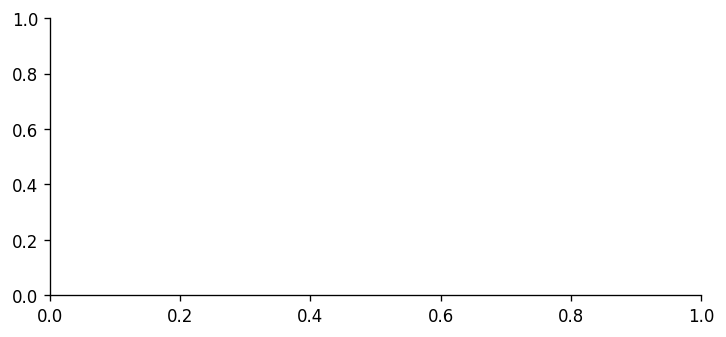

In [18]:
assert 'لا' in prepare_text('لَا أحب هذا')

assert prepare_text('مرحبا   بالعالم') == prepare_text(prepare_text('مرحبا   بالعالم'))

assert 'http' not in prepare_text(examples[0]) and '@ami' not in prepare_text(examples[0])

print('Contrôles du prétraitement et de séparation : OK.')

for name,frame in [('train',train),('val',val)]:
    print(name, 'n =',len(frame),'sarcasme =',round(frame.y.mean(),4))
    display(frame.groupby('dialect').y.agg(['size','sum','mean']))
    display(frame.groupby('sentiment').y.agg(['size','sum','mean']))

fig,ax=plt.subplots(figsize=(7,3))

### Cellule de code 019 — Visualiser la prévalence par dialecte

**Objectif.** Lire rapidement les différences de proportion sarcastique dans le train nettoyé.

**Comprendre le code.** La moyenne de `y` est calculée pour chaque dialecte puis dessinée sur la figure préparée auparavant. Les étiquettes précisent qu’il s’agit d’une proportion, et non d’un nombre de tweets. `tight_layout` ajuste les marges ; `savefig` conserve une version PNG avant l’affichage.

**Résultat attendu à l’exécution.** Un diagramme en barres apparaît et `figures/prior_train.png` est créé dans le dépôt local.

**À retenir.** Ce graphique montre la distribution des annotations du corpus, pas un taux d’erreur du modèle ni une propriété universelle d’un dialecte. Revenir aux effectifs du tableau précédent pour juger sa stabilité.

In [19]:
train.groupby('dialect').y.mean().plot.bar(ax=ax,color='#275D88')

ax.set(ylabel='Proportion sarcastique',title='Train nettoyé par dialecte',xlabel='Dialecte')

plt.tight_layout()

fig.savefig(ROOT/'figures/prior_train.png')

plt.show()

<Figure size 768x576 with 0 Axes>

## 3 Mesures, choix du seuil et journal des expériences

Le modèle produit une probabilité $p$. La décision vaut $\hat y=1[p\ge t]$.
Le seuil est choisi parmi les points de la courbe précision-rappel de **validation** ; en cas
d'égalité de F1 on choisit le plus grand seuil. Une pondération modifie l'objectif appris ;
elle ne garantit pas la calibration des probabilités. Le seuil 0,5 n'est donc pas privilégié.
Tous les entraînements, même les variantes non retenues, sont journalisés. Les scores test
des variantes rejetées restent vides. Un manifeste fixe les modèles avant l'ouverture du test.

### Cellule de code 020 — Définir les métriques de classification

**Objectif.** Évaluer toutes les méthodes avec les mêmes conventions.

**Comprendre le code.** La décision est `p >= threshold`. La précision mesure la part des alertes correctes ; le rappel, la part des sarcastiques retrouvés. Le F1 sarcastique combine ces deux quantités. Le macro-F1 moyenne les F1 des deux classes sans les pondérer par leur taille. L’AP évalue le classement des scores sans choisir un seuil unique. `zero_division=0` traite les cas sans prédiction positive.

**Exemple ou repère.** $P=TP/(TP+FP)$, $R=TP/(TP+FN)$ et $F1=2TP/(2TP+FP+FN)$. TP : vrai positif ; FP : fausse alerte ; FN : sarcasme manqué.

**Résultat attendu à l’exécution.** Un appel à `scores` renverra un dictionnaire de métriques ; cette définition n’évalue encore aucun modèle.

**À retenir.** L’AP est la convention PR-AUC retenue ici ; ce n’est pas l’intégrale trapézoïdale. Si un sous-groupe ne contient aucun positif, son AP est notée non définie plutôt qu’interprétée comme une qualité normale.

In [20]:
def scores(y,p,threshold):
    y=np.asarray(y,dtype=int); p=np.asarray(p); pred=(p>=threshold).astype(int)
    return {'f1_sarcastique':float(f1_score(y,pred,zero_division=0)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
        'pr_auc_ap':float(average_precision_score(y,p)) if y.sum() else float('nan')}

### Cellule de code 021 — Choisir un seuil sur la validation

**Objectif.** Adapter la règle de décision au déséquilibre sans utiliser les réponses du test.

**Comprendre le code.** `precision_recall_curve` fournit les précisions et rappels associés aux seuils des scores. Le code calcule leurs F1, évite une division par zéro et recherche le maximum. Parmi les valeurs jugées numériquement équivalentes avec `np.isclose`, il retient la dernière, donc le seuil le plus élevé dans cet ordre. Le dernier point de la courbe PR n’a pas de seuil et est écarté.

**Résultat attendu à l’exécution.** La fonction renverra un scalaire à enregistrer avec le modèle puis à conserver pendant le test.

**À retenir.** Le seuil 0,5 n’est pas automatiquement optimal, surtout après pondération de la perte. Sélectionner un seuil améliore la décision sur val, mais ne garantit pas une probabilité bien calibrée.

In [21]:
def best_threshold(y,p):
    prec,rec,thresholds=precision_recall_curve(y,p)
    fs=2*prec[:-1]*rec[:-1]/np.maximum(prec[:-1]+rec[:-1],1e-12)
    i=np.flatnonzero(np.isclose(fs,fs.max(),atol=1e-12))[-1]
    return float(thresholds[i])

### Cellule de code 022 — Initialiser le journal et identifier les données

**Objectif.** Créer les structures de suivi et relier les futurs caches à la version réelle des partitions.

**Comprendre le code.** `RESULTS` contiendra les lignes de métriques, `REGISTRY` les chemins/configurations et `HISTORY` les courbes par époque. `DATA_SIG` résume les identifiants, textes et cibles du train. Une empreinte plus large inclut train/val, sentiment, dialecte et partition ; les révisions PLM sont ajoutées au contexte. Ces empreintes permettent de distinguer deux expériences aux entrées différentes.

**Résultat attendu à l’exécution.** Les journaux en mémoire sont initialement vides et les signatures des données sont disponibles.

**À retenir.** Cette cellule réinitialise le suivi de la session. Ne pas la relancer isolément au milieu d’un calcul ; suivre l’ordre du notebook dans un noyau neuf permet ensuite de reconstruire le journal via les checkpoints compatibles.

In [22]:
RESULTS=[]

REGISTRY={}

HISTORY=[]

DATA_SIG=hashlib.sha256(pd.util.hash_pandas_object(train[['id','tweet','y']],index=False).values.tobytes()).hexdigest()
protocol_frames=pd.concat([train.assign(partition='train'),val.assign(partition='val')],ignore_index=True)
CACHE_CONTEXT.update(train_val_sha256=hashlib.sha256(pd.util.hash_pandas_object(
    protocol_frames[['partition','id','tweet','y','sentiment','dialect']],index=False).values.tobytes()).hexdigest(),
    model_revisions={name:r['revision'] for name,r in REVISIONS.items()})

### Cellule de code 023 — Enregistrer une expérience de validation

**Objectif.** Associer une mesure réelle à une configuration, une graine et un fichier de modèle.

**Comprendre le code.** `register` choisit le seuil sur val sauf règle particulière fournie, calcule les métriques et construit une clé comme `nom_seed42`. Une éventuelle ligne portant la même clé est remplacée pour éviter les doublons du journal. Les probabilités val sont sauvegardées en NumPy ; `results.csv` et `registry.json` rendent les chiffres et paramètres consultables hors du noyau. Les champs supplémentaires décrivent notamment le nombre d’époques.

**Résultat attendu à l’exécution.** Lors d’un appel, une ligne de suivi est affichée et les artefacts de validation sont exportés.

**À retenir.** Le temps transmis est celui du run mesuré ou du run historique repris ; il ne faut pas présenter une simple lecture de cache comme un nouvel entraînement. Aucun score test n’est calculé ici.

In [23]:
def register(name,seed,pval,seconds,params,preprocessing,kind,path,config,threshold=None,extra=None):
    t=best_threshold(val.y,pval) if threshold is None else threshold
    key=f'{name}_seed{seed}'
    row={'model':name,'seed':seed,'preprocessing':preprocessing,'threshold':t,
         'train_seconds':seconds,'trainable_parameters':int(params),'n_train':len(train),
         'data_sha256':DATA_SIG,'kind':kind,**{'val_'+k:v for k,v in scores(val.y,pval,t).items()}}
    if extra: row.update(extra)
    RESULTS[:]=[r for r in RESULTS if (r['model'],r['seed'])!=(name,seed)]
    RESULTS.append(row)
    REGISTRY[key]={'key':key,'name':name,'seed':seed,'kind':kind,'path':Path(path).relative_to(ROOT).as_posix(),'config':config,'threshold':t}
    np.save(ROOT/f'predictions/{key}_val.npy',np.asarray(pval))
    pd.DataFrame(RESULTS).to_csv(ROOT/'results/results.csv',index=False)
    (ROOT/'results/registry.json').write_text(json.dumps(REGISTRY,ensure_ascii=False,indent=2),encoding='utf-8')
    print(key,'F1 val =',round(row['val_f1_sarcastique'],4),'seuil =',round(t,4),'temps =',round(seconds,1),'s',flush=True)
    return key

### Cellule de code 024 — Contrôler la reprise d’un checkpoint

**Objectif.** Réutiliser un modèle terminé seulement lorsqu’il correspond à l’expérience demandée.

**Comprendre le code.** `cache_signature` combine version logique, empreinte des données et configuration dans un SHA256. `compatible_metadata` exige aussi l’égalité du contexte d’exécution. Les fonctions d’entraînement vérifieront la présence du modèle, des métadonnées et la correspondance de ces informations avant de charger des poids anciens.

**Résultat attendu à l’exécution.** Deux fonctions de contrôle sont définies ; elles ne lancent aucun calcul de réseau.

**À retenir.** Une empreinte identifie des entrées ; elle ne certifie pas à elle seule la correction scientifique du programme. Elle complète les métadonnées et le contrôle des fichiers, sans remplacer la nécessité de changer `RUN_VERSION` après une modification de logique.

**Optimisation CPU ajoutée.** Les métadonnées neuronales lient aussi taille et date du checkpoint terminé. Un fichier de poids remplacé ne peut pas être associé à d’anciennes probabilités par simple correspondance de nom.

In [24]:
def cache_signature(config):
    return hashlib.sha256(json.dumps([RUN_VERSION,DATA_SIG,config],sort_keys=True).encode()).hexdigest()

def compatible_metadata(meta):
    if not meta.exists(): return False
    saved=json.loads(meta.read_text())
    if saved.get('runtime_context')!=CACHE_CONTEXT: return False
    expected=saved.get('checkpoint_stat')
    checkpoint=meta.with_suffix('.pt')
    return expected is None or (checkpoint.exists() and expected==checkpoint_stat(checkpoint))

def checkpoint_stat(path):
    stat=path.stat()
    return {'bytes':stat.st_size,'mtime_ns':stat.st_mtime_ns}


### Cellule de code 025 — Uniformiser la sauvegarde des figures

**Objectif.** Conserver les graphiques consultables dans le notebook et dans les livrables.

**Comprendre le code.** `savefig` ajuste la disposition, construit un chemin sous `ROOT/figures/`, enregistre le PNG et affiche la figure. `bbox_inches="tight"` réduit les marges superflues et limite les étiquettes coupées. Le nom est fourni par la cellule qui produit le graphique.

**Résultat attendu à l’exécution.** Une fonction utilitaire est définie. Aucun fichier graphique n’est créé tant qu’elle n’est pas appelée avec une figure.

**À retenir.** Une image sauvegardée n’apporte pas une mesure nouvelle : elle représente les tableaux ou calculs réellement produits. Une légende précise doit indiquer partition, métrique et seuil concernés.

In [25]:
def savefig(fig,name):
    fig.tight_layout(); fig.savefig(ROOT/f'figures/{name}.png',bbox_inches='tight'); plt.show()

### Cellule de code 026 — Évaluer le classifieur jamais sarcastique

**Objectif.** Montrer pourquoi l’accuracy seule serait trompeuse dans ce problème déséquilibré.

**Comprendre le code.** `np.zeros(len(val))` prédit la classe non sarcastique pour chaque tweet, sans analyser son contenu. L’accuracy compte ses décisions correctes sur la majorité ; le F1 sarcastique mesure son incapacité à détecter la classe d’intérêt. Le nombre réel de sarcastiques val est affiché pour contextualiser les deux scores.

**Résultat attendu à l’exécution.** L’accuracy vaut la proportion de non-sarcastiques ; le F1 sarcastique vaut 0. Les chiffres exacts sont calculés sur la validation.

**À retenir.** Une méthode doit être comparée à cette référence avant de qualifier une accuracy élevée de bonne performance. La métrique principale du TP reste le F1 sarcastique, complété par AP et macro-F1.

In [26]:
trivial=np.zeros(len(val))

print('Jamais sarcastique : accuracy =',accuracy_score(val.y,trivial),'F1 =',f1_score(val.y,trivial))

print('Sarcastiques val :',int(val.y.sum()),'sur',len(val))

Jamais sarcastique : accuracy = 0.8270916334661355 F1 = 0.0
Sarcastiques val : 217 sur 1255


## Partie A TF IDF mots et caractères

Les unigrammes/bigrammes de mots modélisent des expressions ; les caractères de longueur 2 à 5
captent orthographe dialectale, rires et allongements. L'IDF est $\log((1+n)/(1+df))+1$,
appris sur train uniquement. La régression logistique combine ces indices linéairement.
Les poids équilibrés valent $n/(2n_c)$ : une erreur sur la classe minoritaire coûte davantage.
Nous comparons conservateur et agressif, puis trois traitements du déséquilibre à capacité égale.
Les choix sont déterminés par val, jamais par le test officiel.

### Cellule de code 027 — Construire la baseline TF-IDF et régression logistique

**Objectif.** Combiner des indices lexicaux et des indices de forme dans un modèle linéaire interprétable.

**Comprendre le code.** `FeatureUnion` concatène TF-IDF de mots 1–2 et de caractères 2–5. Les mots décrivent expressions et thèmes ; les caractères captent graphies, rires et allongements. `min_df=2` ignore les unités trop rares et les limites de vocabulaire bornent la taille. La fréquence est transformée de façon sous-linéaire. La régression logistique prédit un score binaire ; `class_weight="balanced"` est activé selon la variante.

**Exemple ou repère.** Pour une unité, l’IDF lissé suit $log((1+n)/(1+df))+1$. Une unité présente dans presque tous les tweets est moins discriminante qu’une unité plus rare.

**Résultat attendu à l’exécution.** La fonction renvoie un pipeline non ajusté. Le vocabulaire, l’IDF et les coefficients seront appris dans `fit`, uniquement sur train.

**À retenir.** Dans cette implémentation, le nettoyage est réalisé par `run_tfidf` avant le pipeline. Le vecteur TF-IDF est sparse : la plupart de ses composantes sont nulles pour un tweet donné.

In [27]:
def make_tfidf(mode='conservative',balanced=True,seed=42):
    # top-level prepare_text est enregistré avec le modèle ; aucun label auxiliaire en entrée.
    return Pipeline([('features',FeatureUnion([
        ('word',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=60000,token_pattern=r'(?u)\b\w+\b',sublinear_tf=True)),
        ('char',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=100000,sublinear_tf=True))])),
        ('clf',LogisticRegression(C=1,max_iter=1200,class_weight='balanced' if balanced else None,random_state=seed,solver='liblinear'))])

### Cellule de code 028 — Exécuter ou reprendre une variante TF-IDF

**Objectif.** Appliquer les mêmes règles de préparation et de validation à plusieurs stratégies de déséquilibre.

**Comprendre le code.** Le texte est nettoyé selon `mode` et `drop_links`. En suréchantillonnage, des positifs du train sont tirés avec remise jusqu’à équilibrer les deux classes. La signature inclut graine, choix et identifiants. Un cache compatible est chargé ; sinon le pipeline est ajusté puis sauvegardé. Les probabilités val sont ensuite calculées et transmises à `register`.

**Résultat attendu à l’exécution.** Un appel produit une clé d’expérience, un checkpoint `joblib`, ses métadonnées et les probabilités val.

**À retenir.** Le suréchantillonnage ne modifie ni val ni test. La durée historique reste associée au modèle repris ; le seuil est déterminé sur validation, sans toucher aux labels test.

In [28]:
def run_tfidf(name,mode='conservative',imbalance='weighted',seed=42,drop_links=False,train_frame=None):
    frame=train if train_frame is None else train_frame
    x=[prepare_text(s,mode,drop_links) for s in frame.tweet]; y=frame.y.to_numpy()
    if imbalance=='oversample':
        rng=np.random.default_rng(seed); idx=np.concatenate([np.flatnonzero(y==0),rng.choice(np.flatnonzero(y==1),sum(y==0),replace=True)])
        x=[x[i] for i in idx]; y=y[idx]
    config={'mode':mode,'imbalance':imbalance,'drop_links':drop_links,'seed':seed,'ids':frame.id.tolist()}
    path=ROOT/f'models/{name}_seed{seed}.joblib'; meta=path.with_suffix('.json'); sig=cache_signature(config)
    if path.exists() and compatible_metadata(meta) and json.loads(meta.read_text())['signature']==sig:
        model=joblib.load(path); seconds=json.loads(meta.read_text())['seconds']
    else:
        model=make_tfidf(mode,imbalance=='weighted',seed); start=time.perf_counter(); model.fit(x,y); seconds=time.perf_counter()-start
        joblib.dump(model,path); meta.write_text(json.dumps({'signature':sig,'seconds':seconds,'runtime_context':CACHE_CONTEXT}))
    p=model.predict_proba([prepare_text(s,mode,drop_links) for s in val.tweet])[:,1]
    params=model.named_steps['clf'].coef_.size+1
    return register(name,seed,p,seconds,params,mode,'tfidf',path,config)

### Cellule de code 029 — Comparer les baselines et les règles superficielles

**Objectif.** Distinguer une vraie baseline textuelle de raccourcis pouvant exploiter la provenance du corpus.

**Comprendre le code.** Quatre variantes sont évaluées : nettoyage conservateur pondéré, agressif pondéré, perte standard et suréchantillonnage. Puis chaque indicateur URL/mention/guillemets est utilisé seul. L’orientation de la règle est choisie sur train : prédire sarcastique quand l’indice est présent ou absent, selon les taux observés. La qualité de cette règle est mesurée sur val.

**Résultat attendu à l’exécution.** Deux tableaux montrent métriques/seuils des variantes et résultats des trois règles ; ces derniers sont exportés dans `shortcut_rules_val.csv`.

**À retenir.** Un bon score d’une règle à un indice signale un raccourci possible. Il ne prouve pas une compréhension de l’ironie ; les sous-groupes et réentraînements sans liens de F permettront de compléter ce diagnostic.

In [29]:
baseline_keys=[run_tfidf('A_tfidf_conservateur'),run_tfidf('A_tfidf_agressif',mode='aggressive'),
               run_tfidf('A_tfidf_standard',imbalance='standard'),run_tfidf('A_tfidf_sur_echantillonne',imbalance='oversample')]

display(pd.DataFrame(RESULTS)[['model','val_f1_sarcastique','val_pr_auc_ap','threshold','train_seconds']])

rule_rows=[]

features_val=text_features(val.tweet)

for feature in ['url','mention','artefact_guillemets']:
    flag_train=features_train[feature].to_numpy(); flag_val=features_val[feature].to_numpy()
    # Deux orientations ; orientation choisie sur train pour ne pas ajouter de sélection test.
    direction=1 if train.y[flag_train].mean()>=train.y[~flag_train].mean() else 0
    p=(flag_val==bool(direction)).astype(float)
    rule_rows.append({'indice':feature,'orientation':direction,**scores(val.y,p,.5)})

rules=pd.DataFrame(rule_rows)

rules.to_csv(ROOT/'results/shortcut_rules_val.csv',index=False)

display(rules)

A_tfidf_conservateur_seed42 F1 val = 0.5206 seuil = 0.5161 temps = 5.7 s
A_tfidf_agressif_seed42 F1 val = 0.4959 seuil = 0.4877 temps = 5.4 s
A_tfidf_standard_seed42 F1 val = 0.5195 seuil = 0.2504 temps = 5.7 s
A_tfidf_sur_echantillonne_seed42 F1 val = 0.4743 seuil = 0.3508 temps = 8.9 s


,model,val_f1_sarcastique,val_pr_auc_ap,threshold,train_seconds
0,A_tfidf_conservateur,0.520607,0.514514,0.516072,5.743542
1,A_tfidf_agressif,0.495935,0.490162,0.487735,5.353780
2,A_tfidf_standard,0.519481,0.517236,0.250351,5.661903
3,A_tfidf_sur_echantillonne,0.474308,0.476991,0.350759,8.879105


,indice,orientation,f1_sarcastique,precision,recall,macro_f1,pr_auc_ap
0,url,0,0.361768,0.232804,0.811060,0.478867,0.221488
1,mention,0,0.266439,0.163522,0.718894,0.312458,0.166161
2,artefact_guillemets,0,0.300578,0.218947,0.479263,0.517176,0.194973


## Partie B Modèles utilisés sans entraînement sur le sarcasme

**B1 NLI** : le tweet est la prémisse, une proposition sur son caractère sarcastique est
l'hypothèse. Le réseau a appris entailment, neutral et contradiction sur d'autres corpus.
L'attention croisée au sein de l'encodeur permet aux mots de la prémisse et de l'hypothèse
d'interagir. Nous calculons le softmax des deux logits d'entailment (sarcastique/sérieux),
comme `multi_label=False` dans la pipeline zero-shot. Les trois formulations sont comparées
sur toute val. Le meilleur prompt sera seul évalué sur le test, après verrouillage.
Le choix du prompt et du seuil utilise val, donc « aucun entraînement » ne signifie pas
« aucune adaptation ». Les textes sont tronqués à 64 tokens de la prémisse, hypothèse conservée.

**B2 sentiment** : on inspecte les labels de CAMeLBERT et applique exactement
« classe de sentiment prédite négative ⇒ sarcastique », sans transformer les annotations
sentiment du corpus en entrées. AP utilise P(négatif), mais précision/rappel/F1 utilisent la
règle d'argmax, pas un seuil optimisé. CAMeLBERT a été affiné sur ASTD, ArSAS et SemEval ;
un recouvrement avec ArSarcasm-v2 est possible. Ce score ne prouve pas une généralisation vierge.

### Cellule de code 030 — Déclarer les modèles imposés et les hypothèses NLI

**Objectif.** Fixer les checkpoints et les formulations qui seront comparés sans entraînement sur le sarcasme.

**Comprendre le code.** Les noms identifient exactement NLI multilingue, CAMeLBERT sentiment, AraBERT Twitter et MARBERTv2. Le manifeste local doit être présent ; cette assertion évite une attente ou un téléchargement implicite. `PROMPTS` contient, en arabe/français/anglais, une hypothèse sarcastique puis une hypothèse sérieuse. Les chemins locaux des modèles sont recalculés après lecture des révisions.

**Résultat attendu à l’exécution.** Les trois paires d’hypothèses sont prêtes et les modèles sont associés à leurs ressources locales.

**À retenir.** L’ordre des deux hypothèses compte : la première représente ici le sarcasme. Le choix ultérieur du meilleur prompt se fera sur val ; aucune formulation n’est sélectionnée à partir du test.

**Colab.** Les quatre PLM manquants sont téléchargés ici aux révisions exactes du projet, puis leurs poids sont contrôlés par SHA256. Cette préparation peut prendre plusieurs minutes et ne produit aucune métrique. Une trace de taille/date/hash permet de réutiliser les téléchargements vérifiés.

In [30]:
if IN_COLAB: prepare_models(ROOT)

NLI_NAME='MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7'

assert (ROOT/'models/assets_complete.json').exists(), 'Poids locaux manquants dans models/hf.'

REVISIONS.update(json.loads((ROOT/'models/revisions.json').read_text()))

SA_NAME='CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment'

ARA_NAME='aubmindlab/bert-base-arabertv02-twitter'

MAR_NAME='UBC-NLP/MARBERTv2'

PROMPTS={'ar':('هذه التغريدة ساخرة.','هذه التغريدة جادة.'),
         'fr':('Ce tweet est sarcastique.','Ce tweet est sérieux.'),
         'en':('This tweet is sarcastic.','This tweet is serious.')}
for model_name,entry in REVISIONS.items():
    entry['path']=str(ROOT/'models/hf'/model_name.replace('/','--'))

Préparation du PLM : aubmindlab/bert-base-arabertv02-twitter révision 0decc2e761667f0aea7aa94546ada5a32a6e5bb8


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Les quatre PLM sont disponibles et vérifiés, sans chargement en mémoire.


### Cellule de code 031 — Définir un chargement local des PLM

**Objectif.** Utiliser le type de modèle adapté à l’expérience sans remplacer le checkpoint demandé.

**Comprendre le code.** `AutoModelForSequenceClassification` charge aussi la tête déjà entraînée pour NLI ou sentiment. `AutoModel` charge l’encodeur dont on exploitera les états cachés dans D/E. `local_files_only=True` impose l’utilisation des ressources présentes. Le modèle est envoyé sur `DEVICE`, qui est le CPU dans l’environnement actuel.

**Résultat attendu à l’exécution.** La fonction est définie ; ses appels chargeront effectivement les poids du modèle demandé.

**À retenir.** Charger un modèle est plus coûteux qu’importer sa classe. Une absence de poids doit être résolue explicitement, sans substituer silencieusement un petit modèle ni annoncer que le calcul a été réalisé.

**Optimisation CPU ajoutée.** SDPA, déjà choisi par défaut dans la version locale pour BERT, est rendu explicite pour les checkpoints BERT compatibles. DeBERTa conserve son implémentation. Un seul encodeur gelé peut être réutilisé ; il est libéré avant un autre chargement PLM.

In [31]:
def load_hf(name,classification=False):
    FROZEN_MODELS.clear()  # Libérer l'extracteur avant un nouveau PLM, sous 16 Go.
    if name not in REVISIONS: REVISIONS.update(json.loads((ROOT/'models/revisions.json').read_text()))
    folder=ROOT/'models/hf'/name.replace('/','--')
    config=json.loads((folder/'config.json').read_text())
    options={'attn_implementation':'sdpa'} if config['model_type']=='bert' else {}
    cls=AutoModelForSequenceClassification if classification else AutoModel
    return cls.from_pretrained(str(folder),local_files_only=True,**options).to(DEVICE)

def frozen_encoder():
    key=(ARA_NAME,str(DEVICE))
    if key not in FROZEN_MODELS:
        encoder=load_hf(ARA_NAME).eval().requires_grad_(False)
        FROZEN_MODELS[key]=encoder
    return FROZEN_MODELS[key]

### Cellule de code 032 — Identifier une inférence mise en cache

**Objectif.** Empêcher la réutilisation de scores calculés sur d’autres textes, prompts ou versions.

**Comprendre le code.** L’empreinte couvre la liste ordonnée des textes, un tag décrivant l’usage, la longueur maximale, la version logique, PyTorch, les révisions PLM et le hash du prétraitement exporté. Les textes sont ordonnés : une permutation doit aussi être détectée puisque les scores sauvegardés sont alignés ligne par ligne.

**Résultat attendu à l’exécution.** Un appel retourne une signature SHA256 pour une inférence précise.

**À retenir.** Le cache d’inférence est distinct du checkpoint d’apprentissage. Des poids identiques ne suffisent pas si le texte d’entrée, l’ordre ou la préparation a changé.

In [32]:
def inference_signature(texts,tag):
    payload={'texts':list(texts),'tag':tag,'max_len':MAX_LEN,'run_version':RUN_VERSION,'torch':torch.__version__,
             'revisions':{k:v['revision'] for k,v in REVISIONS.items()},
             'preprocess_sha256':hashlib.sha256((ROOT/'src/preprocess.py').read_bytes()).hexdigest()}
    if CACHE_CONTEXT.get('device_type')=='cuda': payload['gpu_context']=CACHE_CONTEXT
    return hashlib.sha256(json.dumps(payload,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

### Cellule de code 033 — Vérifier la validité d’un cache de scores

**Objectif.** Savoir si une extraction ou une inférence peut être relue sans recalcul.

**Comprendre le code.** La fonction construit le nom du fichier de métadonnées voisin, calcule la signature attendue puis compare la signature et la taille du fichier. Si l’un des fichiers manque ou si les entrées ne correspondent plus, elle renvoie faux. Les fonctions NLI, sentiment et extraction gelée utilisent ce contrôle.

**Résultat attendu à l’exécution.** Un booléen indique si le cache correspond à l’appel courant.

**À retenir.** Cette vérification n’est pas une nouvelle inférence. Le contrôle de taille n’est pas un hash complet du fichier de scores ; les audits des probabilités et des ressources complètent donc la vérification de provenance.

In [33]:
def valid_cache(path,texts,tag):
    sidecar=path.with_name(path.name+'.cache.json')
    signature=inference_signature(texts,tag)
    if path.exists() and sidecar.exists():
        meta=json.loads(sidecar.read_text())
        return meta['signature']==signature and meta['bytes']==path.stat().st_size
    return False

### Cellule de code 034 — Enregistrer les métadonnées d’un cache d’inférence

**Objectif.** Conserver la signature nécessaire à une reprise ultérieure contrôlée.

**Comprendre le code.** `mark_cache` écrit un petit JSON à côté du fichier de probabilités ou de représentations. Il contient la signature calculée à partir des entrées et la taille réelle de l’artefact. Il doit être appelé après la sauvegarde effective de cet artefact.

**Résultat attendu à l’exécution.** Lors d’un appel, un fichier suffixé `.cache.json` est créé ou actualisé.

**À retenir.** La présence d’un fichier ne suffit pas à prouver son origine. Ces métadonnées rendent explicite à quels textes et à quelle configuration il correspond, sans modifier les scores ni les labels.

**Optimisation CPU ajoutée.** La fonction additionnelle validation_scores conserve les scores du meilleur checkpoint. Les signatures de données/configuration, le fichier de poids et le hash des probabilités sont vérifiés avant de sauter une validation redondante.

In [34]:
def mark_cache(path,texts,tag):
    path.with_name(path.name+'.cache.json').write_text(json.dumps({
        'signature':inference_signature(texts,tag),'bytes':path.stat().st_size},indent=2))

def validation_scores(model,inputs,path,signature,candidate=None,plm=False):
    target=ROOT/f'predictions/{path.stem}_val.npy'
    meta=target.with_suffix('.validation.json')
    expected={'signature':signature,'checkpoint_stat':checkpoint_stat(path),'context':CACHE_CONTEXT}
    if candidate is None and target.exists() and meta.exists():
        try:
            saved=json.loads(meta.read_text())
            digest=hashlib.sha256(target.read_bytes()).hexdigest()
            if all(saved.get(k)==v for k,v in expected.items()) and saved['probability_sha256']==digest:
                p=np.load(target,allow_pickle=False)
                if p.shape==(len(inputs[0]),) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all(): return p
        except (OSError,ValueError,KeyError): pass  # Cache invalide : vraie inférence ci-dessous.
    p=candidate if candidate is not None else neural_predict(model,inputs,batch=BATCH if plm else 64)
    np.save(target,p)
    expected['probability_sha256']=hashlib.sha256(target.read_bytes()).hexdigest()
    expected['producer']='checkpoint_validation'
    meta.write_text(json.dumps(expected,indent=2))
    return p


### Cellule de code 035 — Calculer le score zero-shot par NLI

**Objectif.** Reformuler le sarcasme comme une comparaison entre un tweet et deux hypothèses.

**Comprendre le code.** Pour chaque tweet, deux paires prémisse/hypothèse sont créées. Le code trouve le label entailment dans `id2label`, extrait un logit par hypothèse, regroupe les deux logits par tweet puis applique un softmax entre eux. Le premier score devient celui du sarcasme. La prémisse est bornée à 64 tokens avant la construction des paires ; une marge conserve les hypothèses. `eval()` et `inference_mode()` évitent l’apprentissage.

**Résultat attendu à l’exécution.** Un vecteur de scores aligné sur les textes est renvoyé avec un temps d’inférence ; un cache compatible peut le fournir directement.

**À retenir.** Ce score est une compatibilité relative entre deux hypothèses, pas une probabilité de sarcasme garantie calibrée. Le modèle n’apprend pas sur ArSarcasm dans B1, mais prompt et seuil seront adaptés sur val.

In [35]:
def cached_nli(texts,language,split):
    path=ROOT/f'predictions/B1_{language}_{split}_raw.npy'
    if valid_cache(path,texts,['nli',language,PROMPTS[language]]): return np.load(path),0.0
    tokenizer=AutoTokenizer.from_pretrained(REVISIONS[NLI_NAME]['path'],local_files_only=True)
    model=load_hf(NLI_NAME,True).eval()
    print('NLI labels :',model.config.id2label,flush=True)
    entail=[i for i,label in model.config.id2label.items() if 'entail' in label.lower()]
    assert len(entail)==1
    probs=[]; start=time.perf_counter()
    with torch.inference_mode():
        for j in range(0,len(texts),BATCH):
            batch=[export_clean(s) for s in texts[j:j+BATCH]]
            # Tronquer la prémisse seule garde les deux hypothèses complètes.
            batch=tokenizer.batch_decode(tokenizer(batch,truncation=True,max_length=MAX_LEN,add_special_tokens=False)['input_ids'],skip_special_tokens=True)
            premises=[s for s in batch for _ in range(2)]; hypotheses=[h for _ in batch for h in PROMPTS[language]]
            enc=tokenizer(premises,hypotheses,padding=True,truncation='only_first',max_length=MAX_LEN+24,return_tensors='pt').to(DEVICE)
            logits=model(**enc).logits[:,entail[0]].reshape(-1,2)
            probs.extend(logits.softmax(1)[:,0].cpu().numpy())
            if (j//BATCH+1)%20==0: print('B1',language,split,j+len(batch),'/',len(texts),flush=True)
    elapsed=time.perf_counter()-start
    np.save(path,np.asarray(probs)); mark_cache(path,texts,['nli',language,PROMPTS[language]]); del model; gc.collect()
    return np.asarray(probs),elapsed

### Cellule de code 036 — Comparer les trois langues d’hypothèse

**Objectif.** Mesurer la sensibilité du zero-shot à la formulation sur la même validation.

**Comprendre le code.** La boucle appelle NLI pour arabe, français et anglais, puis enregistre chaque variante avec son propre seuil val. Les champs `train_seconds=0` et paramètres entraînés égaux à 0 signifient qu’aucun poids n’est ajusté sur le train du TP. Le temps d’inférence est suivi séparément ; à la lecture d’un cache, le temps renvoyé par cette lecture ne mesure pas l’inférence initiale.

**Résultat attendu à l’exécution.** `nli_keys` contient trois références comparables sur 1 255 tweets val ; les probabilités et métriques sont sauvegardées.

**À retenir.** Comparer les trois résultats permet de discuter la formulation et l’alignement linguistique. On choisira le meilleur sur val avant le test, au lieu de retenir après coup la langue la plus favorable sur test.

In [36]:
nli_keys=[]

for language in PROMPTS:
    p,elapsed=cached_nli(val.tweet.tolist(),language,'val')
    key=register(f'B1_NLI_{language}',42,p,0,0,'export_only','nli',REVISIONS[NLI_NAME]['path'],
        {'language':language,'model_name':NLI_NAME},extra={'val_inference_seconds':elapsed})
    nli_keys.append(key)

NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 ar val 640 / 1255
B1 ar val 1255 / 1255
B1_NLI_ar_seed42 F1 val = 0.4069 seuil = 0.8023 temps = 0 s
NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 fr val 640 / 1255
B1 fr val 1255 / 1255
B1_NLI_fr_seed42 F1 val = 0.4189 seuil = 0.7628 temps = 0 s
NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 en val 640 / 1255
B1 en val 1255 / 1255
B1_NLI_en_seed42 F1 val = 0.4224 seuil = 0.8249 temps = 0 s


### Cellule de code 037 — Prédire le sentiment et construire la règle B2

**Objectif.** Tester l’heuristique négatif implique sarcastique avec le modèle de sentiment imposé.

**Comprendre le code.** Le code inspecte `id2label` pour trouver la classe négative sans supposer son indice. Le softmax donne les probabilités des sentiments. Deux sorties sont gardées : `p`, la probabilité négative, et `rule`, vraie seulement si la classe la plus probable est négative. Le modèle est en évaluation sans gradients et les sorties peuvent être mises en cache.

**Résultat attendu à l’exécution.** Un appel fournit une probabilité, une décision de règle et un temps pour chaque texte.

**À retenir.** La règle `argmax = négatif` diffère de `P(négatif) >= 0,5` : une classe peut gagner avec 0,4 si les deux autres ont chacune 0,3. La contamination possible par ASTD/SemEval devra limiter l’interprétation.

In [37]:
def sentiment_predict(texts,split):
    path=ROOT/f'predictions/B2_{split}_raw.npz'
    if valid_cache(path,texts,'sentiment'):
        a=np.load(path); return a['p'],a['rule'],0.0
    tokenizer=AutoTokenizer.from_pretrained(REVISIONS[SA_NAME]['path'],local_files_only=True)
    model=load_hf(SA_NAME,True).eval(); print('CAMeLBERT labels :',model.config.id2label,flush=True)
    neg=[i for i,label in model.config.id2label.items() if 'neg' in label.lower()]
    assert len(neg)==1
    probs=[]; rule=[]; start=time.perf_counter()
    with torch.inference_mode():
        for j in range(0,len(texts),BATCH):
            enc=tokenizer([export_clean(s) for s in texts[j:j+BATCH]],truncation=True,max_length=MAX_LEN,padding=True,return_tensors='pt').to(DEVICE)
            pred=model(**enc).logits.softmax(-1)
            probs.extend(pred[:,neg[0]].cpu().numpy()); rule.extend((pred.argmax(-1)==neg[0]).cpu().numpy())
    elapsed=time.perf_counter()-start; np.savez(path,p=probs,rule=rule)
    mark_cache(path,texts,'sentiment')
    del model; gc.collect(); return np.asarray(probs),np.asarray(rule),elapsed

### Cellule de code 038 — Évaluer la règle de sentiment sur validation

**Objectif.** Enregistrer la vraie heuristique B2 sans la remplacer par un seuil optimisé sur P(négatif).

**Comprendre le code.** `rule_sent` est convertie en 0/1 et passée à `register` avec seuil 0,5 ; cela conserve exactement sa décision binaire. Pour l’AP, le champ est remplacé par la valeur calculée sur `p_sent`, qui contient les scores continus. Le tableau filtre ensuite les résultats B1/B2 pour une lecture commune.

**Résultat attendu à l’exécution.** Le notebook affiche précision, rappel, F1 et AP des méthodes directes disponibles.

**À retenir.** Une plainte peut être négative sans être ironique ; une louange ironique peut paraître positive. Le score de B2 mesure donc une corrélation imparfaite entre tâches, avec en plus un recouvrement potentiel des corpus de préentraînement supervisé.

In [38]:
p_sent,rule_sent,elapsed=sentiment_predict(val.tweet.tolist(),'val')

b2_key=register('B2_negatif_sarcastique',42,rule_sent.astype(float),0,0,'export_only','sentiment',
    REVISIONS[SA_NAME]['path'],{'model_name':SA_NAME},threshold=.5,extra={'val_inference_seconds':elapsed,'val_pr_auc_ap':float(average_precision_score(val.y,p_sent))})

display(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('B')])

CAMeLBERT labels : {0: 'positive', 1: 'negative', 2: 'neutral'}
B2_negatif_sarcastique_seed42 F1 val = 0.4695 seuil = 0.5 temps = 0 s


,model,seed,preprocessing,threshold,train_seconds,trainable_parameters,n_train,data_sha256,kind,val_f1_sarcastique,val_precision,val_recall,val_macro_f1,val_pr_auc_ap,val_inference_seconds
4,B1_NLI_ar,42,export_only,0.802276,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,nli,0.406940,0.309353,0.594470,0.603257,0.346567,14.699337
5,B1_NLI_fr,42,export_only,0.762835,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,nli,0.418879,0.308026,0.654378,0.601907,0.349859,13.281176
6,B1_NLI_en,42,export_only,0.824869,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,nli,0.422442,0.329049,0.589862,0.619309,0.348801,13.252760
7,B2_negatif_sarcastique,42,export_only,0.500000,0.0,0,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,sentiment,0.469471,0.332692,0.797235,0.624470,0.474604,4.904597


## Partie C Vocabulaire appris sur train et réseaux statiques

Le vocabulaire ne contient que les tokens vus au moins deux fois sur train. PAD = 0 et UNK = 1.
Une tokenisation Unicode sépare mots, emojis et signes de ponctuation : le signe « ! » est donc
accessible au réseau. Une séquence est limitée à 64 tokens ; le taux de troncature est mesuré.
Les représentations aléatoires ont 100 dimensions, comme AraVec Twitter CBOW unigramme.

**BiLSTM** : un état par token dans les deux sens, puis max-pooling masqué.
**Attention** : $e_i=v^T\tanh(Wh_i)$, $\alpha_i=\mathrm{softmax}(e_i)$,
$c=\sum_i\alpha_i h_i$. Les positions PAD ont un score $-\infty$ avant softmax.
**Transformer** : deux couches, dimension 128, quatre têtes ; les positions sinusoïdales
injectent l'ordre. Sans ces positions, les opérations et le pooling deviennent insensibles
à une permutation des tokens en mode évaluation. L'ablation mesure l'utilité de cet ordre.
Les poids d'attention indiquent une pondération interne ; ils ne prouvent pas une cause.

### Cellule de code 039 — Définir une tokenisation Unicode pour les réseaux statiques

**Objectif.** Choisir les unités auxquelles seront associés les embeddings de la partie C.

**Comprendre le code.** Le motif `\w+|[^\w\s]` reconnaît soit une suite de caractères de mot, soit un signe isolé qui n’est ni un caractère de mot ni un espace. Avec Unicode, les mots arabes ne sont pas traités comme du bruit. La ponctuation et les caractères d’emoji restent accessibles, contrairement à une simple suppression de tous les signes.

**Résultat attendu à l’exécution.** Une expression régulière est définie. Les textes seront découpés par `word_tokens` dans la cellule suivante.

**À retenir.** Cette tokenisation ne correspond pas aux sous-mots de BERT. Certains emojis composés peuvent être répartis en plusieurs caractères ; on ne prétend pas que chaque unité corresponde à un mot linguistique complet.

In [39]:
TOKEN_RE=re.compile(r'\w+|[^\w\s]',re.UNICODE)

### Cellule de code 040 — Associer nettoyage conservateur et tokenisation

**Objectif.** Définir une entrée identique pour construire le vocabulaire et encoder les textes des réseaux C.

**Comprendre le code.** `word_tokens` commence par `prepare_text` dans son mode conservateur, puis applique le motif Unicode. La fonction renvoie une liste de chaînes. Ainsi, les variantes graphiques normalisées de la même manière sont comptées de façon cohérente, et les marqueurs gardés par le nettoyage peuvent devenir des tokens.

**Résultat attendu à l’exécution.** Chaque appel produit une liste de tokens ; définir cette fonction ne construit pas encore le vocabulaire.

**À retenir.** Il faut utiliser la même préparation sur train, val et test. En revanche, seules les fréquences du train peuvent décider quelles unités obtiennent une entrée dans le vocabulaire.

In [40]:
def word_tokens(text): return TOKEN_RE.findall(prepare_text(text))

### Cellule de code 041 — Apprendre le vocabulaire sur le train uniquement

**Objectif.** Transformer les tokens en identifiants sans consulter les distributions de val ou test.

**Comprendre le code.** `Counter` compte toutes les occurrences dans le train admissible. Les unités de fréquence au moins 2 sont triées pour obtenir un ordre stable, puis numérotées à partir de 2. L’identifiant 0 est réservé à PAD et 1 à UNK. Le dictionnaire est exporté en JSON avec les caractères arabes lisibles.

**Résultat attendu à l’exécution.** `VOCAB` associe chaque token connu à un entier. Le fichier `models/vocab.json` permet de retrouver exactement cette correspondance.

**À retenir.** Un mot présent une seule fois sur train pourra déjà devenir UNK ; le taux OOV du train n’est donc pas forcément nul. Ajouter les mots de val/test au vocabulaire introduirait une transformation apprise hors du train.

In [41]:
counts=Counter(t for s in train.tweet for t in word_tokens(s))

VOCAB={'<PAD>':0,'<UNK>':1,**{t:i+2 for i,t in enumerate(sorted(t for t,n in counts.items() if n>=2))}}

(ROOT/'models/vocab.json').write_text(json.dumps(VOCAB,ensure_ascii=False),encoding='utf-8')

233697

### Cellule de code 042 — Encoder les listes de tokens en tenseurs

**Objectif.** Créer les matrices d’identifiants attendues par la couche d’embedding.

**Comprendre le code.** Un tableau entier de forme `(nombre_de_tweets, MAX_LEN)` est initialisé avec PAD=0. Chaque token connu est remplacé par son indice ; sinon il devient UNK=1. Les premières positions sont remplies, les dernières restent du padding. Les textes trop longs sont tronqués. Le repli `[1]` évite une séquence entièrement vide, nécessaire pour le masquage et le BiLSTM compacté.

**Exemple ou repère.** Si trois tokens deviennent `[7, 1, 12]`, la ligne commence par ces identifiants puis contient 61 zéros. UNK et PAD ont des rôles différents.

**Résultat attendu à l’exécution.** La fonction renvoie un tenseur PyTorch entier. Avec la configuration actuelle, chaque ligne comporte 64 positions.

**À retenir.** Un identifiant n’est pas encore un vecteur sémantique. La couche `Embedding` effectuera ensuite la recherche du vecteur correspondant.

In [42]:
def word_encode(texts):
    result=np.zeros((len(texts),MAX_LEN),dtype=np.int64)
    for i,s in enumerate(texts):
        ids=[VOCAB.get(t,1) for t in word_tokens(s)[:MAX_LEN]] or [1]
        result[i,:len(ids)]=ids
    return torch.tensor(result)

### Cellule de code 043 — Mesurer les inconnus et la troncature

**Objectif.** Vérifier si la représentation choisie couvre suffisamment les textes.

**Comprendre le code.** La fonction compte tous les tokens avant la troncature. Le taux OOV est le nombre d’occurrences absentes de `VOCAB` divisé par le nombre total de tokens ; ce n’est pas une proportion de types distincts. Le taux `truncated` est la proportion de tweets dont la longueur dépasse `MAX_LEN`.

**Résultat attendu à l’exécution.** Un dictionnaire donne le volume de tokens, le taux OOV et le taux de tweets tronqués pour une partition.

**À retenir.** Un OOV élevé peut limiter les réseaux statiques, même avec de bons embeddings. Un faible taux de tweets tronqués ne prouve pas que les tokens retirés étaient sans importance pour le sarcasme.

In [43]:
def token_stats(texts):
    seqs=[word_tokens(s) for s in texts]; n=sum(map(len,seqs))
    return {'tokens':n,'oov':sum(t not in VOCAB for seq in seqs for t in seq)/max(n,1),
        'truncated':sum(len(seq)>MAX_LEN for seq in seqs)/len(seqs)}

### Cellule de code 044 — Préparer entrées, cibles et poids de classes

**Objectif.** Aligner les textes et annotations dans des tenseurs de types compatibles avec PyTorch.

**Comprendre le code.** `XW_TRAIN` et `XW_VAL` contiennent les identifiants de tokens ; `YTRAIN` et `YVAL` les classes sarcasme. Les sentiments sont codés NEG=0, NEU=1, POS=2, dans des tenseurs séparés. `torch.long` est le type attendu pour les indices et les cibles de classification. Les poids `n/(2 n_c)` donnent davantage de poids à la classe rare. La boucle commune recalculera ces poids pour son sous-ensemble effectif.

**Résultat attendu à l’exécution.** Les statistiques train/val sont affichées et les tenseurs prêts à être groupés en lots.

**À retenir.** La présence de `STRAIN` dans le jeu de données ne signifie pas qu’il est une entrée textuelle : il sera utilisé seulement comme cible de perte auxiliaire dans les expériences multi-tâches.

In [44]:
display(pd.DataFrame({name:token_stats(frame.tweet) for name,frame in [('train',train),('val',val)]}).T)

XW_TRAIN=word_encode(train.tweet.tolist())

XW_VAL=word_encode(val.tweet.tolist())

YTRAIN=torch.tensor(train.y.to_numpy(),dtype=torch.long)

YVAL=torch.tensor(val.y.to_numpy(),dtype=torch.long)

SENT_MAP={'NEG':0,'NEU':1,'POS':2}

STRAIN=torch.tensor(train.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long)

SVAL=torch.tensor(val.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long)

CLASS_WEIGHTS=torch.tensor(len(train)/(2*np.bincount(train.y)),dtype=torch.float32)

,tokens,oov,truncated
train,197164.0,0.151899,0.000369
val,22892.0,0.211646,0.000000


### Cellule de code 045 — Implémenter le pooling attentionnel

**Objectif.** Apprendre quelles positions résument le mieux un tweet pour la classification.

**Comprendre le code.** Pour des états `h` de forme `(B, L, d)`, une couche linéaire projette vers 64 dimensions, `tanh` apporte une non-linéarité puis une seconde couche produit un score par position. Les positions PAD reçoivent un score très négatif avant softmax. Les poids obtenus servent à sommer les états, ce qui produit un vecteur de forme `(B, d)` et des poids de forme `(B, L)`.

**Exemple ou repère.** $e_i=v^T\tanh(Wh_i)$, $\alpha_i=\mathrm{softmax}(e_i)$ et $c=\sum_i\alpha_i h_i$. Le masque empêche les positions ajoutées pour le padding d’influencer ce résumé.

**Résultat attendu à l’exécution.** La classe `AttentionPool` est définie ; ses poids seront appris avec le réseau qui l’utilise.

**À retenir.** Les poids totalisent environ 1 sur une séquence valide. Une forte attention représente une pondération interne, pas une preuve que le token explique à lui seul la décision.

In [45]:
class AttentionPool(nn.Module):
    def __init__(self,dim):
        super().__init__(); self.w=nn.Linear(dim,64); self.v=nn.Linear(64,1,bias=False)
    def forward(self,h,mask):
        logits=self.v(torch.tanh(self.w(h))).squeeze(-1).masked_fill(~mask,-1e4)
        alpha=logits.softmax(-1); return (h*alpha.unsqueeze(-1)).sum(1),alpha

### Cellule de code 046 — Construire C1, C2 et C3 dans une même classe

**Objectif.** Comparer les architectures tout en gardant une interface et une dimension de sortie communes.

**Comprendre le code.** La couche d’embedding produit 100 valeurs par token, aléatoires ou copiées depuis AraVec. C1/C2 utilisent un LSTM bidirectionnel de 64 unités par sens, donc des états de dimension 128 : C1 fait un max-pooling masqué, C2 une somme attentionnelle. C3 projette les embeddings vers 128 dimensions et applique deux couches Transformer à quatre têtes, avec positions sinusoïdales optionnelles et masque PAD. Le dropout régularise le réseau. La tête finale produit deux logits par tweet.

**Résultat attendu à l’exécution.** Une instance de `StaticNet` pourra recevoir un tenseur `(B, L)` et renvoyer `(B, 2)` ; avec attention demandée, elle peut aussi renvoyer les poids.

**À retenir.** Le compactage du BiLSTM évite que sa direction arrière traite du padding avant le texte. Sans positions, le Transformer et son pooling deviennent insensibles à une permutation des tokens en mode évaluation ; cette propriété motive l’ablation.

In [46]:
class StaticNet(nn.Module):
    def __init__(self,arch='attention',embedding=None,position=True,freeze=False):
        super().__init__(); self.arch=arch
        self.embedding=nn.Embedding(len(VOCAB),100,padding_idx=0)
        if embedding is not None: self.embedding.weight.data.copy_(torch.tensor(embedding))
        self.embedding.weight.requires_grad_(not freeze)
        self.dropout=nn.Dropout(.25)
        if arch=='transformer':
            self.proj=nn.Linear(100,128)
            layer=nn.TransformerEncoderLayer(128,4,256,dropout=.2,batch_first=True)
            self.encoder=nn.TransformerEncoder(layer,2,enable_nested_tensor=False)
            pos=torch.arange(MAX_LEN).unsqueeze(1); div=torch.exp(torch.arange(0,128,2)*(-math.log(10000)/128))
            pe=torch.zeros(MAX_LEN,128); pe[:,0::2]=torch.sin(pos*div); pe[:,1::2]=torch.cos(pos*div)
            self.register_buffer('pe',pe if position else torch.zeros_like(pe))
        else:
            self.encoder=nn.LSTM(100,64,batch_first=True,bidirectional=True)
            self.attention=AttentionPool(128)
        self.head=nn.Linear(128,2)
    def forward(self,x,return_attention=False):
        mask=x.ne(0); h=self.dropout(self.embedding(x)); alpha=None
        if self.arch=='transformer':
            h=self.encoder(self.proj(h)+self.pe[:x.shape[1]],src_key_padding_mask=~mask)
            pooled=(h*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True).clamp(min=1)
        else:
            # pack empêche la direction arrière de traiter du padding avant le vrai texte.
            packed=nn.utils.rnn.pack_padded_sequence(h,mask.sum(1).cpu(),batch_first=True,enforce_sorted=False)
            packed,_=self.encoder(packed)
            h,_=nn.utils.rnn.pad_packed_sequence(packed,batch_first=True,total_length=x.shape[1])
            if self.arch=='attention': pooled,alpha=self.attention(h,mask)
            else: pooled=h.masked_fill(~mask.unsqueeze(-1),-1e4).max(1).values
        logits=self.head(self.dropout(pooled))
        return (logits,alpha) if return_attention else logits

### Boucle commune d'entraînement et early stopping

Le budget maximal est identique entre C1, C2 et C3 : huit époques, batch 64, AdamW à 0,001,
arrêt après deux validations sans progrès. Chaque époque choisit son seuil sur val et conserve
l'état donnant le meilleur F1. Cette sélection répétée peut elle-même surajuster val : le test
indépendant final reste essentiel. Le sur-échantillonnage utilise `WeightedRandomSampler` sur
train uniquement ; validation et test gardent leur distribution naturelle.

### Cellule de code 047 — Définir une inférence neuronale par lots

**Objectif.** Convertir les logits d’un modèle en scores sans modifier ses poids.

**Comprendre le code.** `model.eval()` désactive les comportements d’apprentissage tels que le dropout ; `torch.inference_mode()` évite le suivi des gradients. Les entrées sont découpées en lots et envoyées sur le périphérique courant. Pour un modèle multi-tâche, seule la première sortie, sarcasme, est utilisée ici. Le softmax donne un score de classe 1 ; les poids attentionnels sont également collectés si demandés.

**Résultat attendu à l’exécution.** La fonction renvoie un vecteur de longueur nombre de tweets, ou une paire scores/attention.

**À retenir.** `eval()` et l’absence de gradients ont des rôles différents : le premier règle le comportement des couches, la seconde évite le coût de la rétropropagation. Aucun seuil n’est choisi à l’intérieur de cette fonction.

**Optimisation CPU ajoutée.** L’inférence PLM regroupe les longueurs similaires, puis réécrit chaque score à sa position d’origine. La taille des lots et tous les textes sont conservés ; C/D2 gardent leur parcours habituel. Des arrondis float32 peuvent varier selon la taille effective des calculs.

In [47]:
def neural_predict(model,inputs,batch=64,attention=False):
    model.eval(); n=len(inputs[0]); probs=np.empty(n,dtype=np.float32); att=[]
    grouped=hasattr(model,'enc') and len(inputs)==2 and not attention
    order=np.argsort(-inputs[1].sum(1).cpu().numpy(),kind='stable') if grouped else np.arange(n)
    with torch.inference_mode():
        for start in range(0,n,batch):
            index=order[start:start+batch]
            selection=index if grouped else slice(start,start+batch)
            args=[x[selection].to(DEVICE,non_blocking=DEVICE.type=='cuda') for x in inputs]
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=grouped and DEVICE.type=='cuda'):
                out=model(*args,return_attention=True) if attention else model(*args)
            if attention: out,a=out; att.extend(a.cpu().numpy())
            if isinstance(out,tuple): out=out[0]
            probs[index]=out.float().softmax(-1)[:,1].cpu().numpy()
    return (probs,np.asarray(att)) if attention else probs

### Cellule de code 048 — Décrire les opérations d’une époque d’apprentissage

**Objectif.** Réunir la mise à jour des poids effectuée sur tous les lots du train.

**Comprendre le code.** Chaque lot contient les entrées `xx`, la cible sarcasme `yy` et la cible sentiment `ss`. Les gradients précédents sont remis à zéro ; le modèle calcule ses logits ; la perte sarcasme est calculée. Si `lam` est non nul, la perte sentiment est ajoutée. `backward` calcule les gradients, le clipping borne leur norme à 1 et AdamW met à jour les paramètres. Le scheduler ajuste ensuite le taux d’apprentissage. Les messages de progression PLM sont espacés de 50 lots.

**Exemple ou repère.** En multi-tâche : $L=L_{sarc}+\lambda L_{sent}$. Les sentiments sont fournis à la perte, pas concaténés aux tokens du tweet.

**Résultat attendu à l’exécution.** Lors d’un appel, une époque réelle est parcourue et la moyenne des pertes de lots est renvoyée.

**À retenir.** Une perte train qui baisse ne garantit pas une meilleure généralisation. Les choix de checkpoint et d’arrêt se feront avec le F1 val dans la fonction suivante.

**Optimisation CPU ajoutée.** La somme des pertes est maintenue au fil des lots au lieu de refaire une moyenne de toute la liste à chaque message. Le backward, le clipping, AdamW, le scheduler et l’ordre des lots restent identiques. Aucun gain global d’apprentissage n’a été mesuré.

**Précision mixte T4.** `autocast` entoure seulement le forward et les pertes. `GradScaler` adapte l'échelle avant backward, puis `unscale_` rétablit les vrais gradients avant le clipping à 1. Si un débordement fait sauter le pas d'AdamW, le scheduler ne progresse pas. Le scaler persiste entre les époques du même run. Sans scaler, l'ordre CPU précédent est conservé ; aucune conversion globale des poids en float16 n'est faite.

In [48]:
def optimizer_step(model,loss,opt,scaler,scheduler):
    if scaler is None:
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
        if scheduler: scheduler.step()
    else:
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(),1.0)
        previous_scale=scaler.get_scale(); scaler.step(opt); scaler.update()
        if scheduler and scaler.get_scale()>=previous_scale: scheduler.step()

def train_epoch(model,loader,opt,loss_fn,sent_loss,lam,scheduler,plm,name,seed,epoch,scaler=None):
    model.train(); total_loss=0.; steps=0
    for step,batch in enumerate(loader):
        *xx,yy,ss=[t.to(DEVICE,non_blocking=DEVICE.type=='cuda') for t in batch]
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=scaler is not None):
            out=model(*xx); logits=out[0] if isinstance(out,tuple) else out
            loss=loss_fn(logits,yy)
            if lam: loss=loss+lam*sent_loss(out[1],ss)
        optimizer_step(model,loss,opt,scaler,scheduler)
        total_loss+=loss.item(); steps+=1
        if plm and steps%50==0:
            print(name,seed,'époque',epoch+1,'batch',steps,'/',len(loader),'perte',round(total_loss/steps,4),flush=True)
    return total_loss/max(steps,1)


### Cellule de code 049 — Assembler les lots et gérer leur échantillonnage

**Objectif.** Fournir les mêmes exemples d’apprentissage au modèle avec une stratégie de tirage explicite.

**Comprendre le code.** `TensorDataset` aligne entrées et cibles. En suréchantillonnage, `WeightedRandomSampler` tire avec remise selon l’inverse des fréquences de classes : certains tweets peuvent apparaître plusieurs fois, d’autres être absents d’une époque. Pour les PLM sans ce rééchantillonnage, `LengthGroupedSampler` rapproche des longueurs similaires afin de réduire le padding effectif, tout en conservant les exemples. Les lots valent 16 pour les PLM et 64 pour les autres réseaux ; `num_workers=0` limite les processus Windows.

**Résultat attendu à l’exécution.** Un `DataLoader` prêt à être parcouru par `train_epoch` est renvoyé.

**À retenir.** Le groupement par longueur n’est pas une suppression de données. La validation n’est jamais suréchantillonnée : elle garde sa distribution naturelle.

**Optimisation CPU ajoutée.** BatchSampler fournit maintenant des listes d’indices directement à TensorDataset : la lecture est vectorisée, sans collate Python tweet par tweet. L’ordre des lots et l’état RNG ont été comparés sur données synthétiques, y compris suréchantillonnage et regroupement par longueur. Workers=0 et pin_memory=False sont adaptés au CPU.

In [49]:
def make_training_loader(xtrain,y,sy,seed,imbalance,plm):
    dataset=TensorDataset(*xtrain,y,sy)
    generator=torch.Generator().manual_seed(seed)
    if imbalance=='oversample':
        weights=(1/np.bincount(y.numpy()))[y.numpy()]
        sampler=WeightedRandomSampler(weights,len(y),replacement=True,generator=generator)
    elif plm:
        from transformers.trainer_pt_utils import LengthGroupedSampler
        sampler=LengthGroupedSampler(batch_size=BATCH,lengths=xtrain[1].sum(1).tolist(),generator=generator)
    else: sampler=RandomSampler(dataset,generator=generator)
    # TensorDataset accepte une liste d'indices : une extraction par tenseur, sans boucle Python par tweet.
    batches=BatchSampler(sampler,BATCH if plm else 64,drop_last=False)
    return DataLoader(dataset,batch_size=None,sampler=batches,generator=generator,num_workers=0,pin_memory=DEVICE.type=='cuda')


### Cellule de code 050 — Orchestrer entraînement, validation et checkpoint

**Objectif.** Appliquer une procédure commune et traçable aux réseaux C, D2 et E.

**Comprendre le code.** La fonction complète la configuration, enregistre les identifiants utilisés et vérifie la compatibilité d’un checkpoint terminé. Sinon, elle prépare AdamW, pertes et éventuel warmup PLM de 10 %, puis alterne époque train et inférence val. À chaque époque, le seuil est choisi sur la validation autorisée et le F1 décide si les poids sont sauvegardés. La patience déclenche un arrêt après absence de progrès. Pour AraVec, les embeddings sont dégelés après les deux premières époques. Le meilleur état est rechargé avant l’export.

**Résultat attendu à l’exécution.** Un appel renvoie la clé d’expérience et le meilleur modèle ; historique, probabilités et métadonnées sont écrits. Les métadonnées finales sont publiées par remplacement atomique.

**À retenir.** Les labels test ne participent ni à l’arrêt ni au checkpoint. Avec `val_mask`, seule une partie de val choisit le checkpoint, utile pour F2. Un run interrompu avant ses métadonnées finales n’est pas considéré terminé. Le meilleur checkpoint peut précéder la dernière époque parcourue.

**Optimisation CPU ajoutée.** Le vecteur val de l’époque ayant gagné est conservé, évitant un deuxième forward identique après le rechargement. Un cache signé permet les reprises sans nouvelle validation. Les poids sont écrits dans un fichier pending puis publiés en fin de run ; les anciens résultats authentifiés ne sont pas recalculés artificiellement.

In [50]:
def train_neural(model,xtrain,xval,name,seed=42,config=None,epochs=STATIC_EPOCHS,
                 lr=1e-3,imbalance='weighted',labels=None,sentiments=None,lam=0,freeze_epochs=0,plm=False,val_mask=None):
    config=dict(config or {},seed=seed,epochs=epochs,lr=lr,imbalance=imbalance,lam=lam,
                train_ids=(config or {}).get('train_ids',train.id.tolist()))
    if plm: config.update(dynamic_padding=True,length_grouped=True)
    path=ROOT/f'models/{name}_seed{seed}.pt'; meta=path.with_suffix('.json'); sig=cache_signature(config)
    model=model.to(DEVICE)
    if plm and DEVICE.type!='cpu':
        config.update(device_type=DEVICE.type,precision=PLM_PRECISION,batch=BATCH)
    p=None; best_path=path.with_suffix('.pending.pt')
    trained_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
    if freeze_epochs: trained_params+=model.embedding.weight.numel()
    selection_mask=np.ones(len(val),dtype=bool) if val_mask is None else np.asarray(val_mask)
    config['selection_val_ids']=val.id[selection_mask].tolist()
    sig=cache_signature(config)
    if path.exists() and compatible_metadata(meta) and json.loads(meta.read_text())['signature']==sig:
        payload=torch.load(path,map_location=DEVICE,weights_only=True); model.load_state_dict(payload); del payload
        saved=json.loads(meta.read_text()); seconds=saved['seconds']; history=saved['history']
    else:
        seed_all(seed); y=YTRAIN if labels is None else labels; sy=STRAIN if sentiments is None else sentiments
        loader=make_training_loader(xtrain,y,sy,seed,imbalance,plm)
        opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.01)
        scaler=torch.amp.GradScaler('cuda') if plm and DEVICE.type=='cuda' else None
        total=epochs*len(loader); scheduler=get_linear_schedule_with_warmup(opt,int(.1*total),total) if plm else None
        weights=torch.tensor(len(y)/(2*np.bincount(y.numpy())),dtype=torch.float32,device=DEVICE) if imbalance=='weighted' else None
        loss_fn=nn.CrossEntropyLoss(weight=weights); sent_loss=nn.CrossEntropyLoss()
        start=time.perf_counter(); best=-1; stale=0; history=[]; best_p=None
        for epoch in range(epochs):
            if freeze_epochs and epoch==freeze_epochs:
                model.embedding.weight.requires_grad_(True)
            mean_loss=train_epoch(model,loader,opt,loss_fn,sent_loss,lam,scheduler,plm,name,seed,epoch,scaler)
            p=neural_predict(model,xval,batch=BATCH if plm else 64)
            t=best_threshold(val.y[selection_mask],p[selection_mask]); f=float(f1_score(val.y[selection_mask],p[selection_mask]>=t,zero_division=0))
            history.append({'epoch':epoch+1,'loss':mean_loss,'val_f1':f,'threshold':t})
            print(name,seed,'époque',epoch+1,'perte',round(mean_loss,4),'F1 val',round(f,4),flush=True)
            if f>best+1e-6:
                best=f; stale=0; best_p=p.copy(); torch.save(model.state_dict(),best_path)
            else: stale+=1
            if stale>=PATIENCE and epoch>=freeze_epochs: break
        seconds=time.perf_counter()-start; best_path.replace(path); p=best_p
        draft=meta.with_suffix('.json.tmp')
        draft.write_text(json.dumps({'signature':sig,'seconds':seconds,'history':history,'config':config,'runtime_context':CACHE_CONTEXT,'checkpoint_stat':checkpoint_stat(path),
            'performance':{'threads':torch.get_num_threads(),'inter_op':torch.get_num_interop_threads(),'loader':'vectorized_batches_v1','precision':PLM_PRECISION if plm else 'float32','device':str(DEVICE)}},indent=2))
        draft.replace(meta)
        model.load_state_dict(torch.load(path,map_location=DEVICE,weights_only=True))
    p=validation_scores(model,xval,path,sig,candidate=p,plm=plm)
    HISTORY.extend([dict(model=name,seed=seed,**h) for h in history])
    pd.DataFrame(HISTORY).to_csv(ROOT/'results/learning_curves.csv',index=False)
    key=register(name,seed,p,seconds,trained_params,config.get('preprocessing','conservative'),
                 'plm' if plm else config.get('kind','static'),path,config,
                 extra={'epochs_completed':len(history),'n_train':len(xtrain[0])})
    return key,model

### Cellule de code 051 — Comparer les réseaux à embeddings aléatoires

**Objectif.** Créer la référence C sans connaissance lexicale préentraînée externe.

**Comprendre le code.** La boucle construit BiLSTM, BiLSTM avec attention et mini-Transformer avec la même graine et le budget commun. Une quatrième expérience enlève les positions du Transformer. Chaque entraînement est confié à la même fonction de validation, puis sa clé est conservée. Les objets modèles devenus inutiles sont supprimés pour limiter leur coexistence en mémoire.

**Résultat attendu à l’exécution.** Quatre expériences C sont ajoutées ou reprises depuis des checkpoints compatibles ; un tableau affiche les métriques de validation.

**À retenir.** Cette cellule déclenche de vrais apprentissages si les caches ne conviennent pas. Les différences C1/C2/C3 doivent être lues à budget comparable ; l’ablation sans positions porte sur l’ordre, pas sur une simple réduction de la taille du vocabulaire.

In [51]:
static_keys=[]

for arch,label in [('bilstm','C1_BiLSTM'),('attention','C2_attention'),('transformer','C3_Transformer')]:
    seed_all(42)
    key,model=train_neural(StaticNet(arch),[XW_TRAIN],[XW_VAL],label,config={'arch':arch,'embedding':'random','position':True})
    static_keys.append(key); del model; gc.collect()

seed_all(42)

key,model=train_neural(StaticNet('transformer',position=False),[XW_TRAIN],[XW_VAL],'C3_sans_position',
                      config={'arch':'transformer','embedding':'random','position':False})

static_keys.append(key)

del model

gc.collect()

display(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('C')])

C1_BiLSTM 42 époque 1 perte 0.6379 F1 val 0.4101
C1_BiLSTM 42 époque 2 perte 0.5811 F1 val 0.4557
C1_BiLSTM 42 époque 3 perte 0.5359 F1 val 0.4774
C1_BiLSTM 42 époque 4 perte 0.4771 F1 val 0.4563
C1_BiLSTM 42 époque 5 perte 0.415 F1 val 0.4619
C1_BiLSTM_seed42 F1 val = 0.4774 seuil = 0.6178 temps = 16.7 s
C2_attention 42 époque 1 perte 0.6304 F1 val 0.4217
C2_attention 42 époque 2 perte 0.563 F1 val 0.4402
C2_attention 42 époque 3 perte 0.5056 F1 val 0.4646
C2_attention 42 époque 4 perte 0.4375 F1 val 0.4587
C2_attention 42 époque 5 perte 0.3721 F1 val 0.4683
C2_attention 42 époque 6 perte 0.3106 F1 val 0.4386
C2_attention 42 époque 7 perte 0.2556 F1 val 0.4646
C2_attention_seed42 F1 val = 0.4683 seuil = 0.6676 temps = 22.1 s


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


C3_Transformer 42 époque 1 perte 0.6483 F1 val 0.4211
C3_Transformer 42 époque 2 perte 0.587 F1 val 0.4389
C3_Transformer 42 époque 3 perte 0.5492 F1 val 0.4493
C3_Transformer 42 époque 4 perte 0.5123 F1 val 0.4555
C3_Transformer 42 époque 5 perte 0.4576 F1 val 0.4627
C3_Transformer 42 époque 6 perte 0.4235 F1 val 0.4488
C3_Transformer 42 époque 7 perte 0.383 F1 val 0.4598
C3_Transformer_seed42 F1 val = 0.4627 seuil = 0.6555 temps = 17.1 s
C3_sans_position 42 époque 1 perte 0.6462 F1 val 0.4163
C3_sans_position 42 époque 2 perte 0.5869 F1 val 0.4291
C3_sans_position 42 époque 3 perte 0.5489 F1 val 0.4619
C3_sans_position 42 époque 4 perte 0.5142 F1 val 0.4571
C3_sans_position 42 époque 5 perte 0.4717 F1 val 0.4423
C3_sans_position_seed42 F1 val = 0.4619 seuil = 0.6205 temps = 12.0 s


,model,seed,preprocessing,threshold,train_seconds,trainable_parameters,n_train,data_sha256,kind,val_f1_sarcastique,val_precision,val_recall,val_macro_f1,val_pr_auc_ap,val_inference_seconds,epochs_completed
8,C1_BiLSTM,42,conservative,0.617758,16.727756,1589370,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.477444,0.403175,0.585253,0.668449,0.423603,NaN,5.0
9,C2_attention,42,conservative,0.667551,22.142889,1589370,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.468271,0.445833,0.493088,0.674954,0.453416,NaN,7.0
10,C3_Transformer,42,conservative,0.655531,17.107171,1773946,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.462687,0.388715,0.571429,0.658395,0.410097,NaN,7.0
11,C3_sans_position,42,conservative,0.620511,12.015907,1773946,10842,6ea3f69eb1c2b4017207106f018029bae636c7c67189eb11467ba66ab62c602f,static,0.461864,0.427451,0.502304,0.668616,0.400517,NaN,5.0


### AraVec préentraîné figé puis dégelé

AraVec a appris Word2Vec sur des tweets externes, sans labels de sarcasme. `clean_str` est le
code officiel AraVec reproduit dans la cellule suivante. Nous l'appliquons token par token pour
trouver le vecteur préentraîné. Un token absent garde une initialisation aléatoire ; son absence
d'AraVec est différente du taux UNK du vocabulaire train. Les emojis restent des tokens, même si
AraVec ne leur fournit pas de vecteur. Deux époques gardent les embeddings figés, puis ils sont
dégelés, sous le même budget total de huit époques. Le fichier réduit ne stocke que les vecteurs
utiles au vocabulaire train, afin d'économiser la RAM durant les expériences suivantes.

**AraVec :** fonction officielle `clean_str`, intégrée ici pour ne pas dépendre d’un script auxiliaire de prétraitement.

### Cellule de code 052 — Intégrer la normalisation officielle AraVec

**Objectif.** Rechercher les vecteurs préentraînés avec les conventions graphiques du vocabulaire AraVec.

**Comprendre le code.** La fonction reproduite du dépôt AraVec normalise plusieurs lettres et signes, retire des diacritiques et limite certains allongements. Elle est conservée dans le notebook pour que cette étape ne soit pas cachée dans un script auxiliaire. Elle sera appliquée à chaque token avant de consulter les vecteurs, pas utilisée pour remplacer tout le prétraitement conservateur du tweet.

**Résultat attendu à l’exécution.** `clean_str` est définie localement ; aucune archive Word2Vec n’est chargée ici.

**À retenir.** Les normalisations d’AraVec peuvent détruire des indices si on les applique aveuglément au texte entier. Leur usage est ici limité à la recherche d’un vecteur compatible ; les tokens originaux conservateurs restent les unités du modèle.

In [52]:
def clean_str(text):
    search = ["أ","إ","آ","ة","_","-","/",".","،"," و "," يا ",'"',"ـ","'","ى","\\",'\n', '\t','&quot;','?','؟','!']
    replace = ["ا","ا","ا","ه"," "," ","","",""," و"," يا","","","","ي","",' ', ' ',' ',' ? ',' ؟ ',' ! ']
    
    #remove tashkeel
    p_tashkeel = re.compile(r'[\u0617-\u061A\u064B-\u0652]')
    text = re.sub(p_tashkeel,"", text)
    
    #remove longation
    p_longation = re.compile(r'(.)\1+')
    subst = r"\1\1"
    text = re.sub(p_longation, subst, text)
    
    text = text.replace('وو', 'و')
    text = text.replace('يي', 'ي')
    text = text.replace('اا', 'ا')
    
    for i in range(0, len(search)):
        text = text.replace(search[i], replace[i])
    
    #trim    
    text = text.strip()

    return text

### Cellule de code 053 — Identifier le cache réduit des embeddings AraVec

**Objectif.** Réutiliser uniquement la matrice nécessaire au vocabulaire train courant.

**Comprendre le code.** `matrix_path` pointe vers les vecteurs réduits. Une signature est calculée sur le dictionnaire `VOCAB`, trié lors de la sérialisation pour obtenir un résultat stable. Le fichier voisin contiendra cette signature. Vérifier le vocabulaire est nécessaire car chaque ligne de la matrice doit rester alignée avec le même identifiant de token.

**Résultat attendu à l’exécution.** Les chemins et l’empreinte du vocabulaire sont disponibles pour la construction ou la reprise de la matrice.

**À retenir.** Une matrice de bonne dimension peut pourtant être incorrecte si ses lignes sont dans un autre ordre. Le contrôle ne se limite donc pas au nombre de mots.

In [53]:
matrix_path=ROOT/'models/aravec_train_matrix.npy'

vocab_signature=hashlib.sha256(json.dumps(VOCAB,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

matrix_meta=matrix_path.with_suffix('.cache.json')

### Cellule de code 054 — Construire la matrice AraVec et mesurer sa couverture

**Objectif.** Initialiser les embeddings connus depuis Word2Vec tout en donnant une représentation aux autres tokens.

**Comprendre le code.** Un cache au vocabulaire compatible est relu. Sinon, les vecteurs AraVec sont chargés, puis une matrice de forme `(taille_vocabulaire, 100)` est initialisée avec une graine fixe. PAD reste nul. Pour chaque token, `clean_str` fournit la clé de recherche ; un vecteur trouvé remplace l’initialisation aléatoire. La couverture est calculée en types distincts et en occurrences du train, puis les gros vecteurs sources sont libérés.

**Résultat attendu à l’exécution.** `ARAVEC` contient les seules lignes utiles au modèle et un tableau rapporte les couvertures sauvegardées.

**À retenir.** La couverture AraVec et l’OOV de `VOCAB` sont différents : un token peut être connu du train tout en n’ayant pas de vecteur externe. Une forte couverture en types ne garantit pas la même couverture des occurrences fréquentes.

In [54]:
if matrix_path.exists() and matrix_meta.exists() and json.loads(matrix_meta.read_text())['vocab_signature']==vocab_signature:
    ARAVEC=np.load(matrix_path); coverage=json.loads((ROOT/'models/aravec_coverage.json').read_text())
else:
    import scipy.linalg
    # Compatibilité gensim 4.3 avec scipy récent, sans modifier le paquet installé.
    if not hasattr(scipy.linalg,'triu'): scipy.linalg.triu=np.triu
    from gensim.models import Word2Vec
    if IN_COLAB: prepare_aravec(ROOT)
    candidates=list((ROOT/'models/aravec').rglob('*.mdl'))
    assert candidates,'AraVec manquant dans models/aravec.'
    vectors=Word2Vec.load(str(candidates[0])).wv
    rng=np.random.default_rng(42); ARAVEC=rng.normal(0,.05,(len(VOCAB),100)).astype('float32'); ARAVEC[0]=0
    found=[]
    for token,i in VOCAB.items():
        normalized=clean_str(token)
        if i>1 and normalized in vectors: ARAVEC[i]=vectors[normalized]; found.append(token)
    coverage={'vocab_types':len(VOCAB)-2,'types_found':len(found),
        'type_coverage':len(found)/max(len(VOCAB)-2,1),
        'train_token_coverage':sum(counts[t] for t in found)/sum(counts.values())}
    np.save(matrix_path,ARAVEC); matrix_meta.write_text(json.dumps({'vocab_signature':vocab_signature})); (ROOT/'models/aravec_coverage.json').write_text(json.dumps(coverage,indent=2))
    del vectors; gc.collect()

display(pd.Series(coverage).to_frame('Couverture AraVec'))

Téléchargement officiel : full_uni_cbow_100_twitter.zip
AraVec extrait dans /content/TP2_ArSarcasme/models/aravec


,Couverture AraVec
vocab_types,14956.000000
types_found,14078.000000
type_coverage,0.941294
train_token_coverage,0.719416


### Cellule de code 055 — Comparer C1/C2/C3 avec AraVec

**Objectif.** Mesurer ce que change l’initialisation préentraînée à architectures et budget communs.

**Comprendre le code.** Les trois réseaux reçoivent la même matrice AraVec de départ. `freeze=True` empêche d’abord les mises à jour des embeddings ; `freeze_epochs=2` demande leur dégel après deux époques dans la boucle commune. BiLSTM, attention et Transformer sont chacun évalués sur val avec un seuil optimisé et leur meilleur checkpoint est conservé.

**Résultat attendu à l’exécution.** Trois expériences AraVec sont ajoutées à `static_keys` et au journal, ou reprises si elles sont compatibles.

**À retenir.** Le meilleur checkpoint peut se situer pendant la phase figée si le dégel n’améliore pas val. Il faut lire l’historique avant d’affirmer que le modèle retenu bénéficie d’un ajustement des embeddings. Cette cellule peut entraîner plusieurs réseaux.

In [55]:
for arch,label in [('bilstm','C1_AraVec'),('attention','C2_AraVec'),('transformer','C3_AraVec')]:
    seed_all(42)
    key,model=train_neural(StaticNet(arch,ARAVEC,freeze=True),[XW_TRAIN],[XW_VAL],label,
        config={'arch':arch,'embedding':'aravec','position':True,'freeze_epochs':2},freeze_epochs=2)
    static_keys.append(key); del model; gc.collect()

C1_AraVec 42 époque 1 perte 0.5962 F1 val 0.4981
C1_AraVec 42 époque 2 perte 0.5274 F1 val 0.5249
C1_AraVec 42 époque 3 perte 0.4937 F1 val 0.529
C1_AraVec 42 époque 4 perte 0.4612 F1 val 0.5214
C1_AraVec 42 époque 5 perte 0.4286 F1 val 0.5209
C1_AraVec_seed42 F1 val = 0.529 seuil = 0.6362 temps = 14.4 s
C2_AraVec 42 époque 1 perte 0.5667 F1 val 0.5121
C2_AraVec 42 époque 2 perte 0.4985 F1 val 0.5362
C2_AraVec 42 époque 3 perte 0.465 F1 val 0.5177
C2_AraVec 42 époque 4 perte 0.4309 F1 val 0.5176
C2_AraVec_seed42 F1 val = 0.5362 seuil = 0.7032 temps = 11.7 s
C3_AraVec 42 époque 1 perte 0.5809 F1 val 0.5427
C3_AraVec 42 époque 2 perte 0.5296 F1 val 0.516
C3_AraVec 42 époque 3 perte 0.5213 F1 val 0.5295
C3_AraVec_seed42 F1 val = 0.5427 seuil = 0.6152 temps = 7.0 s


### Déséquilibre sur le meilleur réseau statique

On retient C1, C2 ou C3 selon le F1 de validation, puis on compare la perte pondérée, le
sur-échantillonnage et la perte standard avec seuil optimisé. Pour isoler les effets, architecture,
initialisation, budget, séparation et graine restent identiques. On affiche aussi les F1 à 0,5 :
cela montre ce qui vient de l'apprentissage et ce qui vient de la règle de décision.

### Cellule de code 056 — Isoler l’effet du traitement du déséquilibre

**Objectif.** Comparer trois stratégies sur une architecture C sélectionnée uniquement sur val.

**Comprendre le code.** Le meilleur C1/C2/C3 admissible est retenu hors ablation sans positions. La configuration gagnante sert de référence pondérée ; elle est réentraînée avec suréchantillonnage puis perte standard. Les entrées, l’architecture et le budget restent comparables. Pour chaque méthode, on calcule le F1 à 0,5 puis au seuil choisi sur val afin de séparer effet d’apprentissage et effet de décision.

**Résultat attendu à l’exécution.** `imbalance.csv` présente les trois lignes avec F1 à 0,5, F1 au seuil val et valeur du seuil.

**À retenir.** Ces comparaisons réutilisent val pour sélectionner et analyser ; elles peuvent donc la surajuster. Le test indépendant final reste indispensable. Une pondération élevée ne signifie pas que les scores deviennent automatiquement des probabilités calibrées.

In [56]:
eligible=pd.DataFrame(RESULTS).loc[lambda d:d.model.str.match(r'C[123]_') & ~d.model.str.contains('sans_position')]

best_c_row=eligible.sort_values('val_f1_sarcastique',ascending=False).iloc[0]

best_c_key=f'{best_c_row.model}_seed42'

BEST_C_CFG=REGISTRY[best_c_key]['config'].copy()

imbalance_keys=[best_c_key]

for imbalance in ['oversample','standard']:
    seed_all(42); cfg=dict(BEST_C_CFG,imbalance=imbalance)
    emb=ARAVEC if cfg['embedding']=='aravec' else None
    key,model=train_neural(StaticNet(cfg['arch'],emb,position=cfg.get('position',True),freeze=emb is not None),
        [XW_TRAIN],[XW_VAL],f'C_meilleur_{imbalance}',config=cfg,imbalance=imbalance,freeze_epochs=cfg.get('freeze_epochs',0))
    imbalance_keys.append(key); static_keys.append(key); del model; gc.collect()

imbalance_table=[]

for key in imbalance_keys:
    p=np.load(ROOT/f'predictions/{key}_val.npy'); rec=REGISTRY[key]
    imbalance_table.append({'model':key,'F1_seuil_05':scores(val.y,p,.5)['f1_sarcastique'],
        'F1_seuil_val':scores(val.y,p,rec['threshold'])['f1_sarcastique'],'seuil':rec['threshold']})

display(pd.DataFrame(imbalance_table))

pd.DataFrame(imbalance_table).to_csv(ROOT/'results/imbalance.csv',index=False)

C_meilleur_oversample 42 époque 1 perte 0.5499 F1 val 0.5269
C_meilleur_oversample 42 époque 2 perte 0.4955 F1 val 0.531
C_meilleur_oversample 42 époque 3 perte 0.4609 F1 val 0.5343
C_meilleur_oversample 42 époque 4 perte 0.455 F1 val 0.541
C_meilleur_oversample 42 époque 5 perte 0.4212 F1 val 0.5099
C_meilleur_oversample 42 époque 6 perte 0.4116 F1 val 0.5313
C_meilleur_oversample_seed42 F1 val = 0.541 seuil = 0.8125 temps = 14.1 s
C_meilleur_standard 42 époque 1 perte 0.3963 F1 val 0.5347
C_meilleur_standard 42 époque 2 perte 0.3662 F1 val 0.5294
C_meilleur_standard 42 époque 3 perte 0.3592 F1 val 0.531
C_meilleur_standard_seed42 F1 val = 0.5347 seuil = 0.2939 temps = 7.3 s


,model,F1_seuil_05,F1_seuil_val,seuil
0,C3_AraVec_seed42,0.503165,0.542694,0.615209
1,C_meilleur_oversample_seed42,0.498516,0.541020,0.812528
2,C_meilleur_standard_seed42,0.439628,0.534653,0.293901


## Partie D Encodeur AraBERT gelé

Un PLM gelé ne change aucun poids de son encodeur. D1 compare le premier token [CLS] et la
moyenne des tokens pondérée par le masque. Aucun padding n'entre dans la moyenne ; les tokens
spéciaux restent inclus, convention constante entre train et val. Une régression logistique
pondérée apprend sur train. D2 envoie tous les états token à BiLSTM + attention, tête entraînée
seule. Les états sont stockés en float16 sur disque, puis convertis en float32 pour le CPU.
L'encodeur est toujours en mode eval : le dropout ne doit pas rendre les caractéristiques
gelées aléatoires entre deux appels. Le coût de l'extraction est rapporté séparément du coût
de l'apprentissage de la tête. MAX_LEN = 64 est un choix aligné sur le préentraînement Twitter, pas une limite du modèle.

### Cellule de code 057 — Configurer le préprocesseur officiel AraBERT Twitter

**Objectif.** Respecter les conventions du PLM sans effacer les répétitions utiles au sarcasme.

**Comprendre le code.** `ArabertPreprocessor` est instancié pour le modèle Twitter choisi. `remove_non_digit_repetition=False` désactive la réduction des répétitions non numériques. Deux assertions vérifient sur un exemple concret que le rire ههههه et l’allongement سلاااام sont préservés. Ce sont des contrôles de comportement, pas des mesures de performance du classifieur.

**Résultat attendu à l’exécution.** Le préprocesseur `ARA_PREP` est disponible et un message confirme la conservation testée des répétitions.

**À retenir.** Un préprocesseur officiel peut avoir des options qui ne conviennent pas à la tâche. Les tester vaut mieux que supposer qu’un comportement par défaut préserve tous les marqueurs.

In [57]:
from arabert.preprocess import ArabertPreprocessor

ARA_PREP=ArabertPreprocessor(model_name=ARA_NAME,remove_non_digit_repetition=False)

assert 'ههههه' in ARA_PREP.preprocess('يا سلاااام 😂 ههههه !!!')

assert 'سلاااام' in ARA_PREP.preprocess('يا سلاااام 😂 ههههه !!!')

print('AraBERT : préprocesseur officiel, conservation explicite des répétitions.')

AraBERT : préprocesseur officiel, conservation explicite des répétitions.


### Cellule de code 058 — Adapter les textes à chaque encodeur

**Objectif.** Éviter d’imposer exactement la même normalisation à deux PLM préentraînés différemment.

**Comprendre le code.** Pour AraBERT, le nettoyage d’export précède le préprocesseur officiel. Quand l’ablation sans liens est demandée, liens et mentions sont supprimés avant ce préprocesseur. Pour MARBERT, la préparation minimale `plm` garde davantage la graphie, avec gestion cohérente des URL/mentions. La sortie reste une liste de textes ; aucun label auxiliaire n’est ajouté.

**Résultat attendu à l’exécution.** Une fonction centralise la préparation des entrées PLM pour D, E et les réentraînements F.

**À retenir.** Une comparaison équitable ne signifie pas un nettoyage identique si les modèles attendent des conventions différentes. Il faut documenter ces conventions et les conserver entre apprentissage et inférence.

In [58]:
def plm_texts(texts,name,drop_links=False):
    if name==ARA_NAME:
        # Le préprocesseur officiel gère URL/mentions et conserve les emojis Twitter.
        cleaned=[export_clean(s) for s in texts]
        if drop_links: cleaned=[MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in cleaned]
        return [ARA_PREP.preprocess(s) for s in cleaned]
    return [prepare_text(s,'plm',drop_links) for s in texts]

### Cellule de code 059 — Réutiliser les tokenizers en mémoire

**Objectif.** Éviter de relire inutilement les vocabulaires et configurations de tokenisation.

**Comprendre le code.** `TOKENIZERS` est indexé par nom de modèle. Au premier appel, `AutoTokenizer.from_pretrained` ouvre les ressources locales ; aux appels suivants, le même objet est rendu. Cette optimisation est particulièrement utile lorsque la latence sera mesurée tweet par tweet.

**Résultat attendu à l’exécution.** Un appel renvoie le tokenizer correspondant au checkpoint demandé.

**À retenir.** Le tokenizer est celui du modèle, pas le vocabulaire appris pour C. Il est préentraîné à l’extérieur du TP : on ne lui ajoute pas des tokens appris sur les labels test.

In [59]:
def tokenizer_for(name):
    if name not in TOKENIZERS:
        TOKENIZERS[name]=AutoTokenizer.from_pretrained(REVISIONS[name]['path'],local_files_only=True)
    return TOKENIZERS[name]

### Cellule de code 060 — Transformer les tweets en entrées BERT

**Objectif.** Produire les identifiants de sous-mots et les masques utilisés par les encodeurs.

**Comprendre le code.** Après préparation adaptée, le tokenizer ajoute ses tokens spéciaux, tronque à `MAX_LEN` et complète jusqu’à cette longueur. `input_ids` contient les indices du vocabulaire PLM ; `attention_mask` vaut 1 aux positions valides et 0 au padding. Les deux tenseurs sont alignés et de forme `(N, 64)` avec la configuration actuelle.

**Résultat attendu à l’exécution.** La fonction renvoie une liste de deux tenseurs, utilisée par l’extraction gelée et le fine-tuning.

**À retenir.** Les 64 positions incluent les tokens spéciaux. La tokenisation peut déjà être stockée en longueur fixe tandis que le forward E retirera les colonnes PAD inutiles à chaque batch : ces deux mécanismes ne se contredisent pas.

**Optimisation CPU ajoutée.** Un cache disque et un cache RAM borné à quatre encodages réutilisent exactement les identifiants et masques. La clé dépend des textes, du PLM, de la longueur, du prétraitement et de la version des tokenizers. Le cache ne construit aucun nouveau vocabulaire sur val/test.

In [60]:
def plm_encode(texts,name,drop_links=False):
    tag=['tokenized_v1',name,drop_links,__import__('tokenizers').__version__]
    signature=inference_signature(texts,tag)
    if signature in TOKENIZED: return TOKENIZED[signature]
    folder=ROOT/'models/tokenized'; folder.mkdir(exist_ok=True)
    path=folder/f'{signature}.pt'
    if path.exists():
        payload=torch.load(path,map_location='cpu',weights_only=True)
        inputs=[payload['input_ids'],payload['attention_mask']]
        assert all(x.shape==(len(texts),MAX_LEN) and x.dtype==torch.long for x in inputs)
    else:
        tokenizer=tokenizer_for(name)
        enc=tokenizer(plm_texts(texts,name,drop_links),truncation=True,max_length=MAX_LEN,padding='max_length',return_tensors='pt')
        inputs=[enc['input_ids'],enc['attention_mask']]
        draft=path.with_suffix('.pt.tmp')
        torch.save(dict(zip(['input_ids','attention_mask'],inputs)),draft); draft.replace(path)
    if len(TOKENIZED)>=4: TOKENIZED.pop(next(iter(TOKENIZED)))
    TOKENIZED[signature]=inputs
    return inputs

### Cellule de code 061 — Extraire les états gelés et les stocker sur disque

**Objectif.** Réutiliser les représentations AraBERT sans recalculer l’encodeur à chaque apprentissage de tête.

**Comprendre le code.** Un cache signé est ouvert en mode mémoire mappée s’il correspond aux textes. Sinon, AraBERT est placé en évaluation et parcouru par lots sous `inference_mode`. Les états `last_hidden_state` sont sauvegardés en float16 dans un tableau `(N, 64, hidden_size)`, avec les masques à part. Un fichier partiel est remplacé seulement à la fin de l’extraction ; le temps d’extraction est enregistré séparément.

**Résultat attendu à l’exécution.** La fonction renvoie les états et les masques ; l’encodage sera effectivement calculé seulement si le cache manque ou est incompatible.

**À retenir.** `eval()` seul ne gèle pas les gradients : ici, l’encodeur ne reçoit ni rétropropagation ni mise à jour d’optimiseur. Le stockage float16 économise le disque et la RAM ; les têtes reconvertissent en float32 pour le CPU.

**Optimisation CPU ajoutée.** Les tweets sont regroupés par longueur pour l’extraction, les colonnes de padding terminal inutiles ne sont pas calculées et les lignes sont remises dans leur ordre officiel. Le fichier garde la forme N×64×768. Le masque rend sans effet les positions PAD mises à zéro. Les caches antérieurs compatibles sont conservés.

In [61]:
def frozen_features(texts,split):
    path=ROOT/f'models/frozen_{split}.npy'; maskpath=ROOT/f'models/frozen_{split}_mask.npy'
    if maskpath.exists() and valid_cache(path,texts,'frozen_arabert'): return np.load(path,mmap_mode='r'),np.load(maskpath)
    inputs=plm_encode(texts,ARA_NAME); model=frozen_encoder()
    temp=path.with_name(path.stem+'_partial.npy')
    array=np.lib.format.open_memmap(temp,mode='w+',dtype='float16',shape=(len(texts),MAX_LEN,model.config.hidden_size))
    lengths=inputs[1].sum(1).numpy(); order=np.argsort(-lengths,kind='stable')
    start=time.perf_counter()
    with torch.inference_mode():
        for j in range(0,len(texts),BATCH):
            index=order[j:j+BATCH]; length=int(lengths[index].max())
            ids,mask=[t[index,:length].to(DEVICE) for t in inputs]
            states=model(input_ids=ids,attention_mask=mask).last_hidden_state.cpu().numpy().astype('float16')
            array[index]=0  # Seul le padding absent du calcul est nul ; les tokens valides restent intacts.
            array[index,:length]=states
            if (j//BATCH+1)%50==0: print('Extraction AraBERT',split,min(j+BATCH,len(texts)),'/',len(texts),flush=True)
    array.flush(); del array; temp.replace(path); np.save(maskpath,inputs[1].numpy())
    mark_cache(path,texts,'frozen_arabert')
    (ROOT/f'results/frozen_{split}_time.json').write_text(json.dumps({'seconds':time.perf_counter()-start}))
    return np.load(path,mmap_mode='r'),inputs[1].numpy()

### Cellule de code 062 — Obtenir les représentations de train et val pour D

**Objectif.** Préparer une seule base de caractéristiques commune à D1 et D2.

**Comprendre le code.** `FT` et `FV` contiennent les états des tokens du train et de val ; `MT` et `MV` sont leurs masques. Les appels utilisent des noms de partition distincts et les signatures des textes. Les mêmes états pourront alimenter CLS, moyenne et BiLSTM attention sans repasser l’encodeur.

**Résultat attendu à l’exécution.** Des tableaux de formes `(10842, 64, 768)` et `(1255, 64, 768)` sont attendus pour les données actuelles et AraBERT base, accompagnés de leurs masques.

**À retenir.** Cette cellule peut être coûteuse lors de la première extraction, même sans entraînement. Le coût doit être rapporté séparément du temps très court d’une régression logistique sur ces états.

In [62]:
FT,MT=frozen_features(train.tweet.tolist(),'train')

FV,MV=frozen_features(val.tweet.tolist(),'val')

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction AraBERT train 1600 / 10842
Extraction AraBERT train 3200 / 10842
Extraction AraBERT train 4800 / 10842
Extraction AraBERT train 6400 / 10842
Extraction AraBERT train 8000 / 10842
Extraction AraBERT train 9600 / 10842


### Cellule de code 063 — Comparer résumé CLS et moyenne masquée

**Objectif.** Réduire une séquence d’états BERT à un vecteur par tweet pour D1.

**Comprendre le code.** Le mode CLS prend l’état de la première position. Le mode mean multiplie les états par le masque, somme sur les positions puis divise par le nombre de positions valides. Les tokens spéciaux valides sont inclus : c’est une convention fixe. Le traitement en blocs de 64 tweets évite la conversion simultanée de tout le corpus en float32.

**Exemple ou repère.** $\bar h=\sum_i m_i h_i / \sum_i m_i$. Le dénominateur dépend du masque, pas de la longueur maximale 64.

**Résultat attendu à l’exécution.** Le tableau renvoyé a la forme `(N, 768)`, quelle que soit la longueur réelle des tweets.

**À retenir.** Inclure les positions PAD dans une moyenne fausserait la représentation selon la longueur. Le découpage par blocs limite les temporaires RAM sans changer la formule par tweet.

In [63]:
def pooled_features(h,m,mode):
    if mode=='cls': return np.asarray(h[:,0],dtype=np.float32)
    result=np.empty((len(h),h.shape[-1]),dtype=np.float32)
    for start in range(0,len(h),64):
        stop=start+64
        block=np.asarray(h[start:stop],dtype=np.float32)
        mask=m[start:stop,:,None]
        result[start:stop]=(block*mask).sum(1)/m[start:stop].sum(1,keepdims=True)
    return result

### Cellule de code 064 — Apprendre les deux classifieurs linéaires D1

**Objectif.** Comparer CLS et moyenne avec exactement la même famille de tête.

**Comprendre le code.** Pour chaque pooling, une régression logistique pondérée est ajustée sur les représentations du train. Elle produit ensuite des probabilités val ; le seuil est choisi par `register` et le modèle est sauvegardé en `joblib`. Le nombre de paramètres rapporté correspond ici aux coefficients de la tête, pas à l’encodeur gelé.

**Résultat attendu à l’exécution.** Les clés D1 CLS et D1 mean sont ajoutées à `d_keys`, avec leurs métriques et durées de tête.

**À retenir.** Un encodeur gelé reste nécessaire pour prédire un nouveau tweet. Il faut ajouter sa taille et son temps d’extraction lorsqu’on compare le coût global à TF-IDF ou au fine-tuning.

In [64]:
d_keys=[]

for pooling in ['cls','mean']:
    path=ROOT/f'models/D1_{pooling}_seed42.joblib'; start=time.perf_counter()
    clf=LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=42)
    clf.fit(pooled_features(FT,MT,pooling),train.y); elapsed=time.perf_counter()-start; joblib.dump(clf,path)
    p=clf.predict_proba(pooled_features(FV,MV,pooling))[:,1]
    d_keys.append(register(f'D1_{pooling}',42,p,elapsed,clf.coef_.size+1,'arabert_official','frozen_lr',path,{'pooling':pooling}))

D1_cls_seed42 F1 val = 0.6054 seuil = 0.6799 temps = 4.7 s
D1_mean_seed42 F1 val = 0.6316 seuil = 0.7294 temps = 7.3 s


### Cellule de code 065 — Définir une tête BiLSTM attention sur états BERT

**Objectif.** Conserver la séquence de représentations contextualisées au lieu de la réduire immédiatement à un seul vecteur.

**Comprendre le code.** `FrozenHead` reçoit des états de dimension 768, les convertit en float32 et utilise le masque pour compacter les séquences. Le BiLSTM produit 128 valeurs par position ; `AttentionPool` en fait un résumé ; dropout et couche linéaire donnent deux logits. L’option `return_attention` renvoie aussi les poids pour la visualisation.

**Résultat attendu à l’exécution.** Une classe de tête profonde est définie, avec entrées `(B, L, 768)` et masque `(B, L)`.

**À retenir.** La tête possède des paramètres entraînables, mais les états BERT fournis restent fixes dans D2. Ce n’est donc pas un fine-tuning de l’encodeur, contrairement à E.

In [65]:
class FrozenHead(nn.Module):
    def __init__(self,dim=768):
        super().__init__(); self.encoder=nn.LSTM(dim,64,batch_first=True,bidirectional=True)
        self.attention=AttentionPool(128); self.drop=nn.Dropout(.25); self.head=nn.Linear(128,2)
    def forward(self,h,mask,return_attention=False):
        h=h.float(); mask=mask.bool()
        packed=nn.utils.rnn.pack_padded_sequence(h,mask.sum(1).cpu(),batch_first=True,enforce_sorted=False)
        packed,_=self.encoder(packed); h,_=nn.utils.rnn.pad_packed_sequence(packed,batch_first=True,total_length=mask.shape[1])
        c,a=self.attention(h,mask); out=self.head(self.drop(c))
        return (out,a) if return_attention else out

### Cellule de code 066 — Apprendre D2 et sélectionner cinq tweets à visualiser

**Objectif.** Évaluer la tête profonde puis préparer une inspection de ses poids attentionnels.

**Comprendre le code.** Les représentations stockées sont copiées dans des tenseurs puis transmises à la boucle commune. Après sélection du meilleur checkpoint, une inférence val collecte scores et attention. Les cinq premières annotations positives de val sont choisies, sans regarder les résultats test. Le tokenizer AraBERT reconstruit les sous-mots associés aux positions.

**Résultat attendu à l’exécution.** D2 est enregistré ; `att`, `chosen`, `val_ids` et une liste de lignes attentionnelles sont prêts.

**À retenir.** Les copies des états peuvent occuper environ un gigaoctet pour le train, même avec le stockage float16. Ces cinq tweets servent à illustrer une pondération, pas à constituer un échantillon représentatif de toutes les erreurs.

In [66]:
seed_all(42)

DXT=[torch.from_numpy(np.array(FT)),torch.tensor(MT)]

DXV=[torch.from_numpy(np.array(FV)),torch.tensor(MV)]

d2_key,d2_model=train_neural(FrozenHead(),DXT,DXV,'D2_BiLSTM_attention',
    config={'kind':'frozen_head','preprocessing':'arabert_official'})

d_keys.append(d2_key)

p_att,att=neural_predict(d2_model,DXV,attention=True)

chosen=np.flatnonzero(val.y.to_numpy()==1)[:5]

tokenizer_ara=AutoTokenizer.from_pretrained(REVISIONS[ARA_NAME]['path'],local_files_only=True)

val_ids=plm_encode(val.tweet.tolist(),ARA_NAME)[0]

attention_rows=[]

D2_BiLSTM_attention 42 époque 1 perte 0.4462 F1 val 0.6625
D2_BiLSTM_attention 42 époque 2 perte 0.3422 F1 val 0.6557
D2_BiLSTM_attention 42 époque 3 perte 0.2585 F1 val 0.6555
D2_BiLSTM_attention_seed42 F1 val = 0.6625 seuil = 0.6983 temps = 12.7 s


### Cellule de code 067 — Afficher et exporter l’attention sur cinq tweets

**Objectif.** Relier les poids numériques de D2 aux sous-mots effectivement lus.

**Comprendre le code.** Pour chaque tweet, le masque limite l’affichage aux positions valides. Les sous-mots sont colorés avec une intensité relative à l’attention maximale du tweet ; le survol donne le poids. Un CSV conserve identifiant, token et poids. Cinq graphiques par position sont aussi sauvegardés. Les gros objets de tête et tenseurs temporaires sont ensuite supprimés.

**Résultat attendu à l’exécution.** Des textes colorés, un graphique à cinq panneaux et `attention_five_tweets.csv` deviennent consultables.

**À retenir.** La couleur est normalisée séparément pour chaque tweet : deux couleurs aussi foncées ne garantissent pas deux poids absolus identiques. Un pic sur CLS/SEP ou un mot thématique doit aussi être discuté, sans le transformer en explication causale.

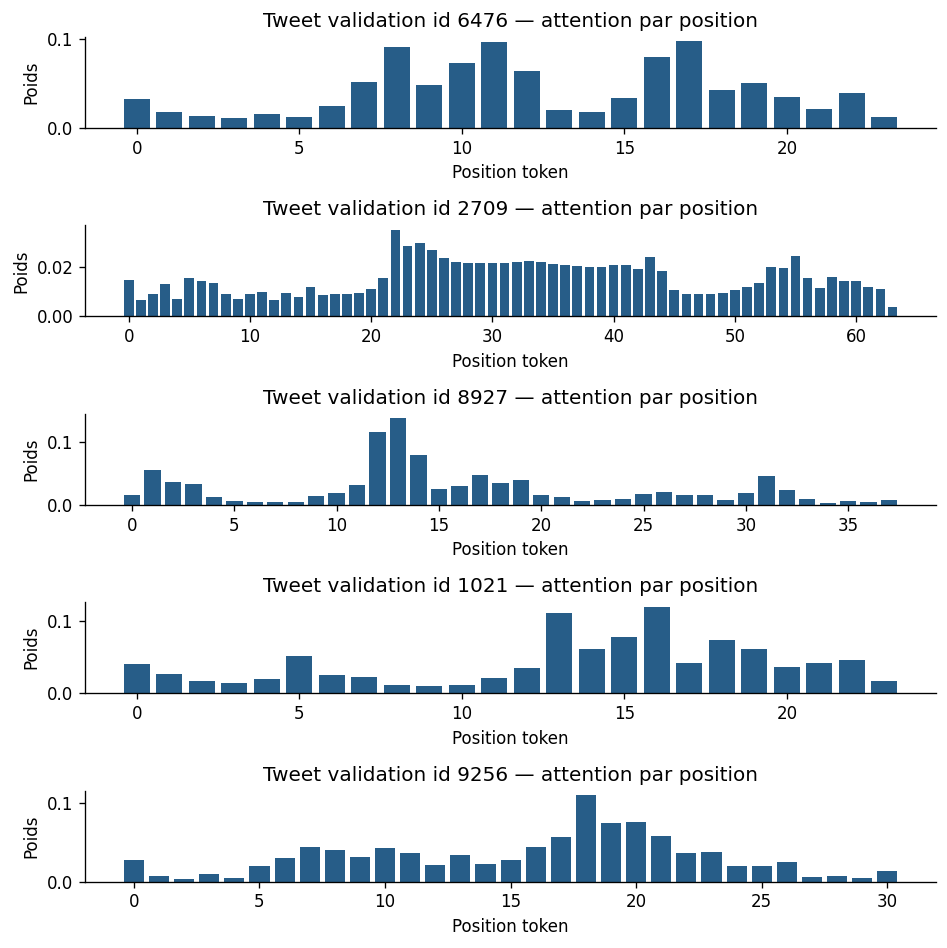

In [67]:
for i in chosen:
    length=int(MV[i].sum()); tokens=tokenizer_ara.convert_ids_to_tokens(val_ids[i,:length])
    weights=att[i,:length]
    cells=' '.join(f'<span title="{w:.4f}" style="background:rgba(35,110,180,{float(w/weights.max()):.3f});padding:4px;display:inline-block">{html.escape(t)}</span>' for t,w in zip(tokens,weights))
    display(HTML(f'<div dir="rtl" style="line-height:2.5">{cells}</div>'))
    attention_rows.extend({'val_id':int(val.iloc[i].id),'token':t,'attention':float(w)} for t,w in zip(tokens,weights))

pd.DataFrame(attention_rows).to_csv(ROOT/'results/attention_five_tweets.csv',index=False,encoding='utf-8-sig')

fig,axes=plt.subplots(5,1,figsize=(8,8))

for ax,i in zip(axes,chosen):
    length=int(MV[i].sum()); ax.bar(np.arange(length),att[i,:length],color='#275D88')
    ax.set(title=f'Tweet validation id {int(val.iloc[i].id)} — attention par position',ylabel='Poids',xlabel='Position token')

savefig(fig,'attention_five_tweets')

del d2_model,DXT,DXV

### Cellule de code 068 — Demander le nettoyage des objets Python inutilisés

**Objectif.** Réduire la coexistence d’objets après l’étape D2 avant les calculs plus lourds.

**Comprendre le code.** `gc.collect()` demande au ramasse-miettes de rechercher des objets devenus inaccessibles, notamment ceux supprimés dans la cellule précédente. C’est une opération de gestion de mémoire ; elle n’entraîne pas de modèle et ne recalcule pas les scores.

**Résultat attendu à l’exécution.** La cellule peut afficher un entier technique lié aux objets récupérés, ou ne donner aucune information utile à l’analyse scientifique.

**À retenir.** Cet entier n’est ni un score ni un volume en octets. Le nettoyage Python ne garantit pas que toute la mémoire soit immédiatement rendue au système : certaines bibliothèques conservent leurs allocations.

**Optimisation CPU ajoutée.** Le cache d’encodeur gelé est également vidé avant E pour garder de la marge sous 16 Go. Les encodeurs entraînables ne sont pas partagés entre les expériences.

In [68]:
FROZEN_MODELS.clear()  # Ne pas conserver l’encodeur gelé pendant E.
gc.collect()

3244

## Partie E Fine tuning mono tâche et multi tâche

Les deux encodeurs complets sont entraînables : AraBERT Twitter et MARBERTv2.
Le checkpoint MLM AraBERT peut déclencher un avertissement de pooler nouvellement initialisé.
Nous utilisons exclusivement last_hidden_state et le CLS brut : ce pooler n'intervient
jamais dans les prédictions et ses paramètres sont exclus de l'apprentissage.

Chaque encodeur
alimente une tête sarcasme de deux classes et, en multi-tâche, une tête sentiment de trois classes.
$L=L_{sarc}+\lambda L_{sent}$ ; $\lambda\in\{0,3;0,5;1\}$. La perte sarcasme est pondérée
selon train. Les labels sentiment ne sont **jamais fournis à l'entrée**, uniquement à la perte.
Une tâche auxiliaire peut guider l'encodeur vers des représentations utiles, mais une tâche
corrélée imparfaitement peut aussi déplacer le gradient au détriment du sarcasme.

Budget : trois époques maximum, AdamW, lr 2e-5, weight decay 0,01, warmup 10 %, clipping 1.
Batch 16 pour les 16 Go de RAM installée ; calcul float32 sur CPU (fp16 CUDA ne s'applique pas ici).
Le sampler natif de Transformers regroupe les longueurs proches dans des méga-batches
mélangés. Le forward retire le padding inutile en fin de batch : tous les exemples restent
présents une fois par époque, et les tokens valides conservent leurs positions et masques.
Le même budget s'applique aux deux PLM. Nous testons les trois lambda à graine 42 ;
le meilleur lambda de chaque encodeur est répété avec 43 et 44, comme le mono-tâche.
La comparaison finale utilise moyenne et écart-type de trois graines ; elle n'affiche pas
artificiellement comme répétitions indépendantes les scores de prompts ou de sous-groupes.

### Cellule de code 069 — Définir le fine-tuning mono et multi-tâche

**Objectif.** Partager un encodeur complet tout en distinguant la tête sarcasme et l’éventuelle tête sentiment.

**Comprendre le code.** `FineTuneNet` charge l’encodeur demandé et ajoute dropout puis une tête à deux logits. En multi-tâche, une deuxième tête fournit trois logits sentiment. Le résumé est exclusivement `last_hidden_state[:, 0]`. Le pooler présent mais inutilisé est explicitement non entraînable. Le forward retire les colonnes terminales entièrement PAD selon la longueur maximale valide du lot, tout en gardant les tokens et leurs positions.

**Résultat attendu à l’exécution.** Le mono-tâche renverra `(B, 2)` ; le multi-tâche une paire `(B, 2)` et `(B, 3)`.

**À retenir.** Les couches utiles de l’encodeur restent entraînables : cette architecture ne remplace pas le fine-tuning par une extraction gelée. Le paramètre `encoder` permet des tests avec un modèle jouet sans charger un PLM complet.

In [69]:
class FineTuneNet(nn.Module):
    def __init__(self,name,multitask=False,encoder=None):
        super().__init__(); self.enc=load_hf(name) if encoder is None else encoder; h=self.enc.config.hidden_size
        # La tête utilise le CLS brut, pas le pooler ; ses poids ne reçoivent aucun gradient.
        if getattr(self.enc,'pooler',None) is not None: self.enc.pooler.requires_grad_(False)
        self.drop=nn.Dropout(.1); self.sarc=nn.Linear(h,2)
        self.sent=nn.Linear(h,3) if multitask else None
    def forward(self,input_ids,attention_mask):
        length=int(attention_mask.sum(1).max())
        input_ids=input_ids[:,:length]; attention_mask=attention_mask[:,:length]
        cls=self.drop(self.enc(input_ids=input_ids,attention_mask=attention_mask).last_hidden_state[:,0])
        logits=self.sarc(cls)
        return (logits,self.sent(cls)) if self.sent is not None else logits

### Cellule de code 070 — Préparer le suivi des expériences E

**Objectif.** Séparer les références des runs E et les lambda sélectionnés pour les répétitions.

**Comprendre le code.** `e_keys` accueillera les clés de chaque entraînement mono ou multi-tâche. `E_BEST_LAMBDA` associera à AraBERT/MARBERT le lambda retenu après la grille à graine 42. Ces structures servent à sélectionner des configurations et à retrouver leurs résultats dans le registre.

**Résultat attendu à l’exécution.** Une liste et un dictionnaire initialement vides sont définis.

**À retenir.** Relancer cette cellule isolément effacerait ce suivi en mémoire. Ce n’est pas une commande de suppression des checkpoints, mais cela casserait les dépendances des cellules E suivantes ; respecter l’ordre du notebook.

In [70]:
e_keys=[]

E_BEST_LAMBDA={}

### Cellule de code 071 — Définir la grille mono/multi pour un encodeur

**Objectif.** Comparer l’absence de tâche auxiliaire et trois poids de sentiment selon le protocole.

**Comprendre le code.** La fonction tokenise train et val pour un encodeur, mesure combien de textes dépassent la longueur choisie puis boucle sur `lam = 0, 0.3, 0.5, 1`. Zéro correspond au mono-tâche ; les autres valeurs activent la tête sentiment. Chaque modèle part du checkpoint préentraîné avec la même graine 42, les mêmes budgets et un taux initial de 2e-5. La boucle commune choisit le checkpoint et le seuil sur val.

**Résultat attendu à l’exécution.** La fonction est seulement définie ici ; son appel lancera quatre configurations pour le PLM indiqué.

**À retenir.** La troncature est mesurée avec le tokenizer de chaque encodeur. Le meilleur lambda est un hyperparamètre sélectionné sur val ; aucun lambda ne doit être retiré simplement parce qu’un autre semble déjà prometteur.

**Optimisation CPU ajoutée.** Le tokenizer déjà chargé et les encodages déjà disponibles sont réutilisés. Les quatre lambda, tous les exemples et la mesure de troncature restent dans la grille.

In [71]:
def run_plm_grid(name,short):
    xt=plm_encode(train.tweet.tolist(),name); xv=plm_encode(val.tweet.tolist(),name)
    tok=tokenizer_for(name)
    lengths=[len(ids) for ids in tok(plm_texts(train.tweet.tolist(),name),add_special_tokens=True)['input_ids']]
    print(short,'train tronqué à 64 :',sum(n>MAX_LEN for n in lengths),'/',len(lengths),flush=True)
    for lam in [0,.3,.5,1.]:
        seed_all(42); label=f'E1_{short}_mono' if lam==0 else f'E2_{short}_lambda{str(lam).replace(".","p")}'
        cfg={'model_name':name,'multitask':lam>0,'preprocessing':'arabert_official' if name==ARA_NAME else 'plm_minimal'}
        key,model=train_neural(FineTuneNet(name,lam>0),xt,xv,label,seed=42,config=cfg,
            epochs=PLM_EPOCHS,lr=2e-5,lam=lam,plm=True)
        e_keys.append(key); del model; gc.collect()
    del xt,xv; gc.collect()

### Cellule de code 072 — Définir les répétitions finales d’un encodeur

**Objectif.** Observer la variabilité du mono-tâche et du meilleur multi-tâche sur trois graines.

**Comprendre le code.** Parmi les variantes multi-tâches de cet encodeur à graine 42, la fonction choisit celle au meilleur F1 val. Elle mémorise son lambda puis relance le mono et ce multi-tâche avec 43 et 44. Ces répétitions complètent la graine 42 déjà calculée. Les hyperparamètres sont conservés ; les initialisations/tirages changent de manière contrôlée.

**Résultat attendu à l’exécution.** Un appel ajoute quatre runs : deux graines pour deux configurations finales de cet encodeur.

**À retenir.** La moyenne sur trois graines ne consiste pas à choisir la meilleure graine. Les deux autres lambda restent des essais de sélection à graine unique et ne doivent pas être présentés comme trois répétitions du modèle final.

In [72]:
def repeat_plm_finals(name,short):
    xt=plm_encode(train.tweet.tolist(),name); xv=plm_encode(val.tweet.tolist(),name)
    multi=[k for k in e_keys if REGISTRY[k]['name'].startswith(f'E2_{short}')]
    chosen_key=max(multi,key=lambda k:next(r['val_f1_sarcastique'] for r in RESULTS if r['model']==REGISTRY[k]['name'] and r['seed']==42))
    chosen_lam=REGISTRY[chosen_key]['config']['lam']; E_BEST_LAMBDA[short]=chosen_lam
    for lam in [0,chosen_lam]:
        label=f'E1_{short}_mono' if lam==0 else REGISTRY[chosen_key]['name']
        for seed in [43,44]:
            seed_all(seed); cfg={'model_name':name,'multitask':lam>0,'preprocessing':'arabert_official' if name==ARA_NAME else 'plm_minimal'}
            key,model=train_neural(FineTuneNet(name,lam>0),xt,xv,label,seed=seed,config=cfg,
                epochs=PLM_EPOCHS,lr=2e-5,lam=lam,plm=True)
            e_keys.append(key); del model; gc.collect()
    del xt,xv; gc.collect()

### AraBERT : grille mono/multi puis répétitions finales
Les quatre configurations à graine 42 sont choisies sur validation. Les répétitions
conservent exactement les paramètres de la configuration retenue.

### Cellule de code 073 — Exécuter la grille AraBERT Twitter

**Objectif.** Réaliser les quatre comparaisons E requises pour AraBERT à graine 42.

**Comprendre le code.** Cette ligne appelle la grille définie précédemment avec `ARA_NAME`. Elle peut charger les quatre checkpoints historiques compatibles ; sinon, elle lance leurs entraînements complets. Même avec des poids déjà disponibles, la validation et les contrôles de reprise peuvent prendre du temps.

**Résultat attendu à l’exécution.** Des messages de troncature, progression/validation et enregistrement des quatre variantes apparaîtront lors de votre exécution.

**À retenir.** C’est une cellule de calcul réel, pas une simple définition. Une attente longue sur CPU n’autorise pas à inventer la sortie ; les logs et les fichiers terminés doivent faire foi.

In [73]:
run_plm_grid(ARA_NAME,"AraBERT")

AraBERT train tronqué à 64 : 76 / 10842


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


E1_AraBERT_mono 42 époque 1 batch 50 / 339 perte 0.6804
E1_AraBERT_mono 42 époque 1 batch 100 / 339 perte 0.6119
E1_AraBERT_mono 42 époque 1 batch 150 / 339 perte 0.5591
E1_AraBERT_mono 42 époque 1 batch 200 / 339 perte 0.5257
E1_AraBERT_mono 42 époque 1 batch 250 / 339 perte 0.4998
E1_AraBERT_mono 42 époque 1 batch 300 / 339 perte 0.4942
E1_AraBERT_mono 42 époque 1 perte 0.4842 F1 val 0.6653
E1_AraBERT_mono 42 époque 2 batch 50 / 339 perte 0.3111
E1_AraBERT_mono 42 époque 2 batch 100 / 339 perte 0.318
E1_AraBERT_mono 42 époque 2 batch 150 / 339 perte 0.315
E1_AraBERT_mono 42 époque 2 batch 200 / 339 perte 0.3195
E1_AraBERT_mono 42 époque 2 batch 250 / 339 perte 0.315
E1_AraBERT_mono 42 époque 2 batch 300 / 339 perte 0.3131
E1_AraBERT_mono 42 époque 2 perte 0.3115 F1 val 0.6582
E1_AraBERT_mono 42 époque 3 batch 50 / 339 perte 0.2096
E1_AraBERT_mono 42 époque 3 batch 100 / 339 perte 0.2171
E1_AraBERT_mono 42 époque 3 batch 150 / 339 perte 0.2119
E1_AraBERT_mono 42 époque 3 batch 200 / 3

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3 42 époque 1 batch 50 / 339 perte 1.0028
E2_AraBERT_lambda0p3 42 époque 1 batch 100 / 339 perte 0.9117
E2_AraBERT_lambda0p3 42 époque 1 batch 150 / 339 perte 0.8319
E2_AraBERT_lambda0p3 42 époque 1 batch 200 / 339 perte 0.7828
E2_AraBERT_lambda0p3 42 époque 1 batch 250 / 339 perte 0.7451
E2_AraBERT_lambda0p3 42 époque 1 batch 300 / 339 perte 0.7286
E2_AraBERT_lambda0p3 42 époque 1 perte 0.7128 F1 val 0.6638
E2_AraBERT_lambda0p3 42 époque 2 batch 50 / 339 perte 0.4882
E2_AraBERT_lambda0p3 42 époque 2 batch 100 / 339 perte 0.4905
E2_AraBERT_lambda0p3 42 époque 2 batch 150 / 339 perte 0.4898
E2_AraBERT_lambda0p3 42 époque 2 batch 200 / 339 perte 0.4915
E2_AraBERT_lambda0p3 42 époque 2 batch 250 / 339 perte 0.4863
E2_AraBERT_lambda0p3 42 époque 2 batch 300 / 339 perte 0.4849
E2_AraBERT_lambda0p3 42 époque 2 perte 0.4834 F1 val 0.668
E2_AraBERT_lambda0p3 42 époque 3 batch 50 / 339 perte 0.367
E2_AraBERT_lambda0p3 42 époque 3 batch 100 / 339 perte 0.3726
E2_AraBERT_lambda

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p5 42 époque 1 batch 50 / 339 perte 1.2138
E2_AraBERT_lambda0p5 42 époque 1 batch 100 / 339 perte 1.1053
E2_AraBERT_lambda0p5 42 époque 1 batch 150 / 339 perte 1.0057
E2_AraBERT_lambda0p5 42 époque 1 batch 200 / 339 perte 0.9449
E2_AraBERT_lambda0p5 42 époque 1 batch 250 / 339 perte 0.8987
E2_AraBERT_lambda0p5 42 époque 1 batch 300 / 339 perte 0.8747
E2_AraBERT_lambda0p5 42 époque 1 perte 0.8554 F1 val 0.6641
E2_AraBERT_lambda0p5 42 époque 2 batch 50 / 339 perte 0.5911
E2_AraBERT_lambda0p5 42 époque 2 batch 100 / 339 perte 0.5904
E2_AraBERT_lambda0p5 42 époque 2 batch 150 / 339 perte 0.5921
E2_AraBERT_lambda0p5 42 époque 2 batch 200 / 339 perte 0.5934
E2_AraBERT_lambda0p5 42 époque 2 batch 250 / 339 perte 0.5882
E2_AraBERT_lambda0p5 42 époque 2 batch 300 / 339 perte 0.5885
E2_AraBERT_lambda0p5 42 époque 2 perte 0.5876 F1 val 0.6692
E2_AraBERT_lambda0p5 42 époque 3 batch 50 / 339 perte 0.4589
E2_AraBERT_lambda0p5 42 époque 3 batch 100 / 339 perte 0.4624
E2_AraBERT_lamb

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda1p0 42 époque 1 batch 50 / 339 perte 1.7371
E2_AraBERT_lambda1p0 42 époque 1 batch 100 / 339 perte 1.5833
E2_AraBERT_lambda1p0 42 époque 1 batch 150 / 339 perte 1.4354
E2_AraBERT_lambda1p0 42 époque 1 batch 200 / 339 perte 1.3457
E2_AraBERT_lambda1p0 42 époque 1 batch 250 / 339 perte 1.2801
E2_AraBERT_lambda1p0 42 époque 1 batch 300 / 339 perte 1.2377
E2_AraBERT_lambda1p0 42 époque 1 perte 1.2102 F1 val 0.6596
E2_AraBERT_lambda1p0 42 époque 2 batch 50 / 339 perte 0.8357
E2_AraBERT_lambda1p0 42 époque 2 batch 100 / 339 perte 0.8289
E2_AraBERT_lambda1p0 42 époque 2 batch 150 / 339 perte 0.8388
E2_AraBERT_lambda1p0 42 époque 2 batch 200 / 339 perte 0.8411
E2_AraBERT_lambda1p0 42 époque 2 batch 250 / 339 perte 0.8354
E2_AraBERT_lambda1p0 42 époque 2 batch 300 / 339 perte 0.8383
E2_AraBERT_lambda1p0 42 époque 2 perte 0.8371 F1 val 0.6706
E2_AraBERT_lambda1p0 42 époque 3 batch 50 / 339 perte 0.6715
E2_AraBERT_lambda1p0 42 époque 3 batch 100 / 339 perte 0.6697
E2_AraBERT_lamb

### Cellule de code 074 — Répéter les deux configurations finales AraBERT

**Objectif.** Compléter les graines 43/44 après la grille AraBERT.

**Comprendre le code.** `repeat_plm_finals` choisit le meilleur lambda AraBERT sur val à graine 42, puis ajuste le mono-tâche et ce multi-tâche pour les deux autres graines. Les poids de départ proviennent du préentraînement pour chaque nouveau run ; il ne s’agit pas de continuer le modèle entraîné avec la graine 42.

**Résultat attendu à l’exécution.** Deux groupes AraBERT complets à trois graines seront disponibles si les quatre runs se terminent.

**À retenir.** Cette étape peut durer plusieurs heures sur CPU. Un checkpoint partiel sans métadonnées finales ne remplace pas un run terminé ; le journal doit distinguer strictement ces deux situations.

In [74]:
repeat_plm_finals(ARA_NAME,"AraBERT")

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E1_AraBERT_mono 43 époque 1 batch 50 / 339 perte 0.7133
E1_AraBERT_mono 43 époque 1 batch 100 / 339 perte 0.625
E1_AraBERT_mono 43 époque 1 batch 150 / 339 perte 0.5614
E1_AraBERT_mono 43 époque 1 batch 200 / 339 perte 0.534
E1_AraBERT_mono 43 époque 1 batch 250 / 339 perte 0.5121
E1_AraBERT_mono 43 époque 1 batch 300 / 339 perte 0.5001
E1_AraBERT_mono 43 époque 1 perte 0.4925 F1 val 0.6692
E1_AraBERT_mono 43 époque 2 batch 50 / 339 perte 0.3136
E1_AraBERT_mono 43 époque 2 batch 100 / 339 perte 0.3207
E1_AraBERT_mono 43 époque 2 batch 150 / 339 perte 0.3144
E1_AraBERT_mono 43 époque 2 batch 200 / 339 perte 0.3153
E1_AraBERT_mono 43 époque 2 batch 250 / 339 perte 0.3127
E1_AraBERT_mono 43 époque 2 batch 300 / 339 perte 0.3078
E1_AraBERT_mono 43 époque 2 perte 0.3159 F1 val 0.6681
E1_AraBERT_mono 43 époque 3 batch 50 / 339 perte 0.2259
E1_AraBERT_mono 43 époque 3 batch 100 / 339 perte 0.223
E1_AraBERT_mono 43 époque 3 batch 150 / 339 perte 0.2227
E1_AraBERT_mono 43 époque 3 batch 200 / 3

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E1_AraBERT_mono 44 époque 1 batch 50 / 339 perte 0.6573
E1_AraBERT_mono 44 époque 1 batch 100 / 339 perte 0.5861
E1_AraBERT_mono 44 époque 1 batch 150 / 339 perte 0.541
E1_AraBERT_mono 44 époque 1 batch 200 / 339 perte 0.5185
E1_AraBERT_mono 44 époque 1 batch 250 / 339 perte 0.5034
E1_AraBERT_mono 44 époque 1 batch 300 / 339 perte 0.4896
E1_AraBERT_mono 44 époque 1 perte 0.476 F1 val 0.6829
E1_AraBERT_mono 44 époque 2 batch 50 / 339 perte 0.299
E1_AraBERT_mono 44 époque 2 batch 100 / 339 perte 0.3115
E1_AraBERT_mono 44 époque 2 batch 150 / 339 perte 0.3179
E1_AraBERT_mono 44 époque 2 batch 200 / 339 perte 0.3101
E1_AraBERT_mono 44 époque 2 batch 250 / 339 perte 0.3164
E1_AraBERT_mono 44 époque 2 batch 300 / 339 perte 0.3161
E1_AraBERT_mono 44 époque 2 perte 0.3153 F1 val 0.6785
E1_AraBERT_mono 44 époque 3 batch 50 / 339 perte 0.2357
E1_AraBERT_mono 44 époque 3 batch 100 / 339 perte 0.2355
E1_AraBERT_mono 44 époque 3 batch 150 / 339 perte 0.232
E1_AraBERT_mono 44 époque 3 batch 200 / 33

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3 43 époque 1 batch 50 / 339 perte 1.0595
E2_AraBERT_lambda0p3 43 époque 1 batch 100 / 339 perte 0.927
E2_AraBERT_lambda0p3 43 époque 1 batch 150 / 339 perte 0.8377
E2_AraBERT_lambda0p3 43 époque 1 batch 200 / 339 perte 0.7904
E2_AraBERT_lambda0p3 43 époque 1 batch 250 / 339 perte 0.7575
E2_AraBERT_lambda0p3 43 époque 1 batch 300 / 339 perte 0.7359
E2_AraBERT_lambda0p3 43 époque 1 perte 0.7216 F1 val 0.6808
E2_AraBERT_lambda0p3 43 époque 2 batch 50 / 339 perte 0.4939
E2_AraBERT_lambda0p3 43 époque 2 batch 100 / 339 perte 0.4884
E2_AraBERT_lambda0p3 43 époque 2 batch 150 / 339 perte 0.4829
E2_AraBERT_lambda0p3 43 époque 2 batch 200 / 339 perte 0.483
E2_AraBERT_lambda0p3 43 époque 2 batch 250 / 339 perte 0.4814
E2_AraBERT_lambda0p3 43 époque 2 batch 300 / 339 perte 0.4749
E2_AraBERT_lambda0p3 43 époque 2 perte 0.4825 F1 val 0.6776
E2_AraBERT_lambda0p3 43 époque 3 batch 50 / 339 perte 0.3792
E2_AraBERT_lambda0p3 43 époque 3 batch 100 / 339 perte 0.3781
E2_AraBERT_lambda

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3 44 époque 1 batch 50 / 339 perte 1.0202
E2_AraBERT_lambda0p3 44 époque 1 batch 100 / 339 perte 0.9033
E2_AraBERT_lambda0p3 44 époque 1 batch 150 / 339 perte 0.8299
E2_AraBERT_lambda0p3 44 époque 1 batch 200 / 339 perte 0.7851
E2_AraBERT_lambda0p3 44 époque 1 batch 250 / 339 perte 0.7542
E2_AraBERT_lambda0p3 44 époque 1 batch 300 / 339 perte 0.7291
E2_AraBERT_lambda0p3 44 époque 1 perte 0.709 F1 val 0.6905
E2_AraBERT_lambda0p3 44 époque 2 batch 50 / 339 perte 0.4802
E2_AraBERT_lambda0p3 44 époque 2 batch 100 / 339 perte 0.487
E2_AraBERT_lambda0p3 44 époque 2 batch 150 / 339 perte 0.4915
E2_AraBERT_lambda0p3 44 époque 2 batch 200 / 339 perte 0.4823
E2_AraBERT_lambda0p3 44 époque 2 batch 250 / 339 perte 0.4897
E2_AraBERT_lambda0p3 44 époque 2 batch 300 / 339 perte 0.4897
E2_AraBERT_lambda0p3 44 époque 2 perte 0.4863 F1 val 0.6742
E2_AraBERT_lambda0p3 44 époque 3 batch 50 / 339 perte 0.3902
E2_AraBERT_lambda0p3 44 époque 3 batch 100 / 339 perte 0.389
E2_AraBERT_lambda0

### MARBERT : grille mono/multi puis répétitions finales
Les quatre configurations à graine 42 sont choisies sur validation. Les répétitions
conservent exactement les paramètres de la configuration retenue.

### Cellule de code 075 — Exécuter la grille MARBERTv2

**Objectif.** Soumettre le deuxième encodeur imposé au même protocole mono/multi-tâche.

**Comprendre le code.** La grille utilise le tokenizer et le prétraitement minimal de MARBERT, puis évalue les quatre lambda, dont zéro pour le mono. Les durées ne sont pas déduites de celles d’AraBERT : elles sont mesurées. Les réglages de budget, sélection val et seuil restent communs pour rendre la comparaison lisible.

**Résultat attendu à l’exécution.** Quatre expériences MARBERT à graine 42 et leur taux de troncature seront produits ou repris si compatibles.

**À retenir.** Le vocabulaire et la tokenisation des deux PLM diffèrent. Une même longueur maximale n’implique pas exactement le même nombre de mots conservés ; lire les statistiques de troncature avant d’interpréter un écart de qualité.

In [75]:
run_plm_grid(MAR_NAME,"MARBERT")

MARBERT train tronqué à 64 : 35 / 10842
E1_MARBERT_mono 42 époque 1 batch 50 / 339 perte 0.6728
E1_MARBERT_mono 42 époque 1 batch 100 / 339 perte 0.6216
E1_MARBERT_mono 42 époque 1 batch 150 / 339 perte 0.5602
E1_MARBERT_mono 42 époque 1 batch 200 / 339 perte 0.5249
E1_MARBERT_mono 42 époque 1 batch 250 / 339 perte 0.4984
E1_MARBERT_mono 42 époque 1 batch 300 / 339 perte 0.4884
E1_MARBERT_mono 42 époque 1 perte 0.4789 F1 val 0.671
E1_MARBERT_mono 42 époque 2 batch 50 / 339 perte 0.2889
E1_MARBERT_mono 42 époque 2 batch 100 / 339 perte 0.2952
E1_MARBERT_mono 42 époque 2 batch 150 / 339 perte 0.2982
E1_MARBERT_mono 42 époque 2 batch 200 / 339 perte 0.3021
E1_MARBERT_mono 42 époque 2 batch 250 / 339 perte 0.2979
E1_MARBERT_mono 42 époque 2 batch 300 / 339 perte 0.2968
E1_MARBERT_mono 42 époque 2 perte 0.293 F1 val 0.649
E1_MARBERT_mono 42 époque 3 batch 50 / 339 perte 0.1765
E1_MARBERT_mono 42 époque 3 batch 100 / 339 perte 0.1871
E1_MARBERT_mono 42 époque 3 batch 150 / 339 perte 0.1866
E

### Cellule de code 076 — Répéter MARBERT et récapituler E

**Objectif.** Achever les groupes MARBERT puis afficher l’ensemble des expériences de fine-tuning.

**Comprendre le code.** La première instruction ajoute les graines 43/44 du mono MARBERT et de son meilleur lambda multi-tâche. Le tableau suivant filtre les lignes E et expose modèle, graine, F1 val, durée, paramètres entraînables et nombre d’époques effectivement parcourues. On peut ainsi vérifier que les configurations finales sont complètes avant le test.

**Résultat attendu à l’exécution.** Les deux encodeurs auront au total 16 runs E prévus par cette stratégie de grille puis répétitions, si tout s’est terminé.

**À retenir.** La comparaison des encodeurs doit utiliser les groupes finaux à trois graines, pas le score maximal d’un essai isolé. Ce tableau reste une évaluation de validation, même s’il résume beaucoup de calculs.

In [76]:
repeat_plm_finals(MAR_NAME,"MARBERT")

display(pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('E')][['model','seed','val_f1_sarcastique','train_seconds','trainable_parameters','epochs_completed']])

E1_MARBERT_mono 43 époque 1 batch 50 / 339 perte 0.6592
E1_MARBERT_mono 43 époque 1 batch 100 / 339 perte 0.6006
E1_MARBERT_mono 43 époque 1 batch 150 / 339 perte 0.5504
E1_MARBERT_mono 43 époque 1 batch 200 / 339 perte 0.5175
E1_MARBERT_mono 43 époque 1 batch 250 / 339 perte 0.4971
E1_MARBERT_mono 43 époque 1 batch 300 / 339 perte 0.484
E1_MARBERT_mono 43 époque 1 perte 0.4758 F1 val 0.6558
E1_MARBERT_mono 43 époque 2 batch 50 / 339 perte 0.2888
E1_MARBERT_mono 43 époque 2 batch 100 / 339 perte 0.2813
E1_MARBERT_mono 43 époque 2 batch 150 / 339 perte 0.2853
E1_MARBERT_mono 43 époque 2 batch 200 / 339 perte 0.2841
E1_MARBERT_mono 43 époque 2 batch 250 / 339 perte 0.2893
E1_MARBERT_mono 43 époque 2 batch 300 / 339 perte 0.2864
E1_MARBERT_mono 43 époque 2 perte 0.2918 F1 val 0.6609
E1_MARBERT_mono 43 époque 3 batch 50 / 339 perte 0.2038
E1_MARBERT_mono 43 époque 3 batch 100 / 339 perte 0.187
E1_MARBERT_mono 43 époque 3 batch 150 / 339 perte 0.1848
E1_MARBERT_mono 43 époque 3 batch 200 / 

,model,seed,val_f1_sarcastique,train_seconds,trainable_parameters,epochs_completed
20,E1_AraBERT_mono,42,0.665331,147.761798,134604290,3.0
21,E2_AraBERT_lambda0p3,42,0.673114,158.065143,134606597,3.0
22,E2_AraBERT_lambda0p5,42,0.671785,232.698576,134606597,3.0
23,E2_AraBERT_lambda1p0,42,0.671845,231.360485,134606597,3.0
24,E1_AraBERT_mono,43,0.674584,149.197238,134604290,3.0
25,E1_AraBERT_mono,44,0.682927,132.673082,134604290,3.0
26,E2_AraBERT_lambda0p3,43,0.683486,136.541604,134606597,3.0
27,E2_AraBERT_lambda0p3,44,0.690526,133.996012,134606597,3.0
28,E1_MARBERT_mono,42,0.670968,158.330648,162252290,3.0
29,E2_MARBERT_lambda0p3,42,0.660754,154.621989,162254597,3.0


## 4 Répétitions finales et verrouillage avant test

Le modèle final de chaque famille A, C, D, E1, E2 est choisi uniquement sur val.
Pour E, les moyennes de validation des trois graines départagent les encodeurs.
Les gagnants A, C et D sont également répétés avec les graines 43 et 44. Une méthode
déterministe peut donner un écart-type nul ; cela ne signifie pas une incertitude nulle.
Les graines mesurent une variabilité d'optimisation ; le bootstrap mesurera l'incertitude
conditionnelle au test observé. Le manifeste inclut les seuils fixés et l'horodatage UTC.

### Cellule de code 077 — Retrouver une ligne de résultat à partir de sa clé

**Objectif.** Passer du registre d’un modèle à sa mesure enregistrée sans multiplier les recherches manuelles.

**Comprendre le code.** `REGISTRY` fournit le nom et la graine associés à une clé. La fonction cherche ensuite dans `RESULTS` la ligne portant ces deux valeurs. Elle est utilisée pour comparer les F1 val, compléter les métriques test et agréger les répétitions.

**Résultat attendu à l’exécution.** `row_for_key` renverra la ligne correspondante sous forme de dictionnaire lors de ses appels.

**À retenir.** Le nom seul ne suffit pas à identifier un run : plusieurs graines partagent une architecture. Garder cette association explicite évite de mélanger seuils, probabilités et mesures de deux expériences.

In [77]:
def row_for_key(key):
    rec=REGISTRY[key]; return next(r for r in RESULTS if r['model']==rec['name'] and r['seed']==rec['seed'])

### Cellule de code 078 — Choisir les configurations finales sans consulter le test

**Objectif.** Fixer les représentants des familles A, C, D, E1 et E2 à partir de val.

**Comprendre le code.** Pour A/C/D, le code retient le meilleur F1 val parmi leurs candidats enregistrés. Pour E1, les encodeurs sont comparés par moyenne val des graines. Pour E2, seules les configurations disposant de trois lignes sont admissibles à la comparaison des moyennes : les lambda rejetés à graine unique ne peuvent donc pas battre artificiellement un groupe complet. `FINAL_GROUPS` rassemble les clés finales.

**Résultat attendu à l’exécution.** Un dictionnaire de cinq familles est préparé. A/C/D contiennent encore leur graine 42 ; E1/E2 référencent déjà les trois graines.

**À retenir.** La baseline balanced obligatoire reste documentée même si une autre variante A est retenue. Le choix d’un modèle final ne doit jamais être refait après lecture de son F1 test.

In [78]:
best_a_key=max(baseline_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

best_c_key=max(static_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

best_d_key=max(d_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

edf=pd.DataFrame(RESULTS).loc[lambda d:d.model.str.startswith('E')]

best_e1_name=edf.loc[edf.model.str.startswith('E1')].groupby('model').val_f1_sarcastique.mean().idxmax()

e2_averages=edf.loc[edf.model.str.startswith('E2')].groupby('model').val_f1_sarcastique.agg(['mean','count'])

best_e2_name=e2_averages.loc[e2_averages['count'].eq(3),'mean'].idxmax()

FINAL_GROUPS={'A':[best_a_key],'C':[best_c_key],'D':[best_d_key],
    'E1':[f'{best_e1_name}_seed{s}' for s in SEEDS], 'E2':[f'{best_e2_name}_seed{s}' for s in SEEDS]}

### Cellule de code 079 — Compléter les trois graines de A, C et D

**Objectif.** Donner aux cinq familles entraînées des répétitions finales comparables.

**Comprendre le code.** La configuration choisie à graine 42 est reconstruite avec 43 puis 44. Selon sa famille, le code utilise le pipeline TF-IDF, le réseau statique, la tête linéaire gelée ou BiLSTM attention gelé. Pour D, les représentations AraBERT déjà extraites sont réutilisées. Le meilleur prompt NLI est ensuite choisi à partir de son F1 val.

**Résultat attendu à l’exécution.** A/C/D obtiennent chacun trois clés. Le prompt NLI final est déterminé avant toute ouverture des labels test.

**À retenir.** Une méthode quasi déterministe peut avoir un écart-type nul entre graines ; cela ne supprime pas l’incertitude liée à l’échantillon test. Les graines évaluent surtout une variabilité d’apprentissage, pas toute l’incertitude scientifique.

In [79]:
for family,key in [('A',best_a_key),('C',best_c_key),('D',best_d_key)]:
    rec=REGISTRY[key]; cfg=rec['config'].copy()
    for seed in [43,44]:
        seed_all(seed)
        if family=='A':
            repeated=run_tfidf(rec['name'],cfg['mode'],cfg['imbalance'],seed,cfg['drop_links'])
        elif family=='C':
            emb=ARAVEC if cfg['embedding']=='aravec' else None
            repeated,model=train_neural(StaticNet(cfg['arch'],emb,position=cfg.get('position',True),freeze=emb is not None),
                [XW_TRAIN],[XW_VAL],rec['name'],seed=seed,config=cfg,
                imbalance=cfg.get('imbalance','weighted'),freeze_epochs=cfg.get('freeze_epochs',0))
            del model; gc.collect()
        elif rec['kind']=='frozen_lr':
            pooling=cfg['pooling']; clf=LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=seed)
            start=time.perf_counter(); clf.fit(pooled_features(FT,MT,pooling),train.y); seconds=time.perf_counter()-start
            path=ROOT/f'models/{rec["name"]}_seed{seed}.joblib'; joblib.dump(clf,path)
            repeated=register(rec['name'],seed,clf.predict_proba(pooled_features(FV,MV,pooling))[:,1],seconds,clf.coef_.size+1,
                'arabert_official','frozen_lr',path,cfg)
        else:
            repeated,model=train_neural(FrozenHead(),[torch.from_numpy(np.array(FT)),torch.tensor(MT)],
                [torch.from_numpy(np.array(FV)),torch.tensor(MV)],rec['name'],seed=seed,config=cfg)
            del model; gc.collect()
        FINAL_GROUPS[family].append(repeated)

best_nli_key=max(nli_keys,key=lambda k:row_for_key(k)['val_f1_sarcastique'])

A_tfidf_conservateur_seed43 F1 val = 0.5206 seuil = 0.5161 temps = 5.8 s
A_tfidf_conservateur_seed44 F1 val = 0.5206 seuil = 0.5161 temps = 5.8 s
C3_AraVec 43 époque 1 perte 0.5786 F1 val 0.5273
C3_AraVec 43 époque 2 perte 0.5253 F1 val 0.5059
C3_AraVec 43 époque 3 perte 0.5246 F1 val 0.5176
C3_AraVec_seed43 F1 val = 0.5273 seuil = 0.6816 temps = 6.9 s
C3_AraVec 44 époque 1 perte 0.5852 F1 val 0.5212
C3_AraVec 44 époque 2 perte 0.5275 F1 val 0.5304
C3_AraVec 44 époque 3 perte 0.5102 F1 val 0.5131
C3_AraVec 44 époque 4 perte 0.4936 F1 val 0.5147
C3_AraVec_seed44 F1 val = 0.5304 seuil = 0.6768 temps = 9.2 s
D2_BiLSTM_attention 43 époque 1 perte 0.4467 F1 val 0.6828
D2_BiLSTM_attention 43 époque 2 perte 0.339 F1 val 0.6795
D2_BiLSTM_attention 43 époque 3 perte 0.2583 F1 val 0.6547
D2_BiLSTM_attention_seed43 F1 val = 0.6828 seuil = 0.7339 temps = 12.3 s
D2_BiLSTM_attention 44 époque 1 perte 0.4478 F1 val 0.6682
D2_BiLSTM_attention 44 époque 2 perte 0.3434 F1 val 0.6826
D2_BiLSTM_attention 

### Cellule de code 080 — Verrouiller modèles et seuils avant le test

**Objectif.** Créer une trace explicite de ce qui a été choisi avant de connaître les réponses du test officiel.

**Comprendre le code.** `FINAL_KEYS` réunit les 15 runs des cinq familles entraînées et les deux méthodes directes B1/B2. Le manifeste sauvegarde horodatage, groupes, configurations, seuils, signatures des données et budgets. Un tableau récapitule les métriques val utilisées pour cette sélection.

**Résultat attendu à l’exécution.** `results/final_manifest.json` est écrit et doit lister 17 références finales avec leurs décisions fixées.

**À retenir.** Un horodatage documente la procédure, sans constituer une preuve cryptographique de non-consultation du test. La discipline expérimentale est de conserver ces choix lors des cellules F/G suivantes.

In [80]:
FINAL_KEYS=[k for keys in FINAL_GROUPS.values() for k in keys]+[best_nli_key,b2_key]

manifest={'locked_at_utc':datetime.now(timezone.utc).isoformat(),'groups':FINAL_GROUPS,
    'models':[REGISTRY[k] for k in FINAL_KEYS],'data_sha256':DATA_SIG,'seeds':SEEDS,
    'hyperparameters':{'max_len':MAX_LEN,'plm_epochs':PLM_EPOCHS,'static_epochs':STATIC_EPOCHS,'batch_plm':BATCH}}

(ROOT/'results/final_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

display(pd.DataFrame([row_for_key(k) for k in FINAL_KEYS])[['model','seed','val_f1_sarcastique','threshold','train_seconds']])

print('Manifestes et seuils verrouillés AVANT ouverture des labels test.')

,model,seed,val_f1_sarcastique,threshold,train_seconds
0,A_tfidf_conservateur,42,0.520607,0.516072,5.743542
1,A_tfidf_conservateur,43,0.520607,0.516072,5.799399
2,A_tfidf_conservateur,44,0.520607,0.516072,5.772753
3,C3_AraVec,42,0.542694,0.615209,6.953632
4,C3_AraVec,43,0.527344,0.681563,6.901972
5,C3_AraVec,44,0.530435,0.676775,9.156917
6,D2_BiLSTM_attention,42,0.662500,0.698322,12.684689
7,D2_BiLSTM_attention,43,0.682819,0.733876,12.286691
8,D2_BiLSTM_attention,44,0.682578,0.810747,16.544699
9,E1_AraBERT_mono,42,0.665331,0.520801,147.761798


Manifestes et seuils verrouillés AVANT ouverture des labels test.


## Partie F Test officiel et généralisation

À partir d'ici, les labels test sont ouverts. Aucun modèle final ni seuil n'est changé à la
lumière de ses scores. On termine l'audit des corrélations du test demandé au début du sujet.
La distribution test peut différer de val ; même avec un classement identique, précision et F1
changent quand la prévalence change. Le seuil a posteriori du test est un **diagnostic interdit
pour la sélection**, tracé séparément du seuil utilisable fixé sur val.

### Cellule de code 081 — Ouvrir le test officiel en partie F

**Objectif.** Évaluer la généralisation après le verrouillage, sans réutiliser le test comme validation.

**Comprendre le code.** Le CSV test est enfin lu avec ses annotations et reçoit ses identifiants officiels. L’absence de collision avec train est revérifiée. Les distributions globales, par dialecte et par sentiment sont comparées entre partitions. Les corrélations URL/mention/artefact sont complétées pour test. Le train officiel et le test sont réunis pour rechercher des clés contradictoires a posteriori.

**Résultat attendu à l’exécution.** Les tableaux décrivent le prior et les sous-groupes test réellement observés. Aucun modèle n’est entraîné dans cette cellule.

**À retenir.** Ces informations sont descriptives. Leur découverte ne permet pas de modifier ensuite seuils, prompts ou hyperparamètres pour améliorer le score test annoncé ; cela invaliderait son rôle d’évaluation indépendante.

In [81]:
test=pd.read_csv(DATA_DIR/'testing_data.csv')

test['id']=np.arange(len(test))

test['y']=test.sarcasm.astype(int)

test['key']=test.tweet.map(duplicate_key)

assert len(test)==3000 and set(train.key).isdisjoint(test.key)

display(pd.DataFrame({n:{'n':len(f),'sarcastiques':int(f.y.sum()),'taux':f.y.mean()} for n,f in [('train',train),('val',val),('test',test)]}).T)

for column in ['dialect','sentiment']:
    display(pd.concat({n:f.groupby(column).y.agg(['size','sum','mean']) for n,f in [('train',train),('val',val),('test',test)]}))

for name,frame in [('train',train),('test',test)]:
    flags=text_features(frame.tweet)
    display(pd.DataFrame([{'split':name,'indice':c,'presence':present,'n':int(flags[c].eq(present).sum()),
        'taux_sarcasme':frame.y[flags[c].eq(present)].mean()} for c in ['url','mention','artefact_guillemets'] for present in [False,True]]))

combined=pd.concat([full.assign(split='train_officiel'),test.assign(split='test')],ignore_index=True)

combined['key']=combined.tweet.map(duplicate_key)

,n,sarcastiques,taux
train,10842.0,1864.0,0.171924
val,1255.0,217.0,0.172908
test,3000.0,821.0,0.273667


size  sum      mean
      dialect                     
train egypt    2320  814  0.350862
      gulf      511  117  0.228963
      levant    549  119  0.216758
      magreb     35   13  0.371429
      msa      7427  801  0.107850
val   egypt     260   94  0.361538
      gulf       68   14  0.205882
      levant     55   16  0.290909
      magreb      5    0  0.000000
      msa       867   93  0.107266
test  egypt     306  155  0.506536
      gulf      322   57  0.177019
      levant     47   14  0.297872
      magreb      2    0  0.000000
      msa      2323  595  0.256134

size   sum      mean
      sentiment                      
train NEG        4025  1686  0.418882
      NEU        4910   132  0.026884
      POS        1907    46  0.024122
val   NEG         465   195  0.419355
      NEU         584    17  0.029110
      POS         206     5  0.024272
test  NEG        1677   709  0.422779
      NEU         748   106  0.141711
      POS         575     6  0.010435

,split,indice,presence,n,taux_sarcasme
0,train,url,False,6711,0.239011
1,train,url,True,4131,0.062939
2,train,mention,False,8456,0.174669
3,train,mention,True,2386,0.162196
4,train,artefact_guillemets,False,4260,0.253286
5,train,artefact_guillemets,True,6582,0.119265


,split,indice,presence,n,taux_sarcasme
0,test,url,False,2560,0.314453
1,test,url,True,440,0.036364
2,test,mention,False,2977,0.275781
3,test,mention,True,23,0.000000
4,test,artefact_guillemets,False,2994,0.273881
5,test,artefact_guillemets,True,6,0.166667


### Cellule de code 082 — Compléter l’audit post-test et extraire ses états gelés

**Objectif.** Relier les contradictions, la couverture linguistique et les représentations nécessaires aux prédictions D.

**Comprendre le code.** Les groupes portant plusieurs labels sont exportés à partir du corpus combiné. Les effectifs `magreb` de train et test rendent visible la faiblesse éventuelle de couverture pour un usage marocain. Les OOV et troncatures sont calculés avec le vocabulaire train déjà fixé. `frozen_features` fournit ensuite les états et masques du test, sans mettre à jour l’encodeur.

**Résultat attendu à l’exécution.** Un CSV de contradictions et des statistiques post-test sont produits ; `FX` et `MX` pourront être partagés entre les modèles D.

**À retenir.** Observer des inconnus dans test n’autorise pas à agrandir rétroactivement le vocabulaire C. Le groupe `magreb` ne garantit pas une représentation suffisante de la darija marocaine ni de l’Arabizi.

In [82]:
all_contradictions=set(combined.groupby('key').y.nunique().loc[lambda s:s>1].index)

combined.loc[combined.key.isin(all_contradictions)].to_csv(ROOT/'results/contradictions_all_post_test.csv',index=False,encoding='utf-8-sig')

display(pd.DataFrame({'split':['train','test'],'magreb':[int(train.dialect.eq('magreb').sum()),int(test.dialect.eq('magreb').sum())]}))

display(pd.DataFrame({n:token_stats(f.tweet) for n,f in [('train',train),('val',val),('test',test)]}).T)

FX,MX=frozen_features(test.tweet.tolist(),'test')

,split,magreb
0,train,35
1,test,2


,tokens,oov,truncated
train,197164.0,0.151899,0.000369
val,22892.0,0.211646,0.000000
test,59352.0,0.277109,0.002333


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction AraBERT test 1600 / 3000


### Cellule de code 083 — Recharger un modèle enregistré

**Objectif.** Reconstruire la bonne architecture avant d’y replacer les poids de son checkpoint.

**Comprendre le code.** TF-IDF et les têtes linéaires sont relus avec `joblib`. Pour les réseaux, le champ `kind` détermine si l’on construit `StaticNet`, `FrozenHead` ou `FineTuneNet`. La configuration restitue les variantes nécessaires, puis `load_state_dict` charge les tenseurs sauvegardés. Le modèle est envoyé sur le périphérique courant et mis en évaluation.

**Résultat attendu à l’exécution.** La fonction renverra un modèle prêt pour l’inférence. Les méthodes B1/B2 ont leur propre procédure de chargement et peuvent renvoyer ici `None`.

**À retenir.** Un fichier de poids ne suffit pas sans la structure et les conventions d’entrée correspondantes. Un état incompatible doit provoquer une erreur plutôt qu’être chargé partiellement pour fabriquer un résultat.

In [83]:
def load_registered(rec):
    cfg=rec['config']; kind=rec['kind']
    if kind in ['tfidf','frozen_lr']: return joblib.load(ROOT/rec['path'])
    if kind=='static': model=StaticNet(cfg['arch'],position=cfg.get('position',True))
    elif kind=='frozen_head': model=FrozenHead()
    elif kind=='plm': model=FineTuneNet(cfg['model_name'],cfg['multitask'])
    else: return None
    model.load_state_dict(torch.load(ROOT/rec['path'],map_location=DEVICE,weights_only=True)); return model.to(DEVICE).eval()

### Cellule de code 084 — Uniformiser la prédiction entre les familles

**Objectif.** Appliquer à chaque texte le pipeline compatible avec la configuration enregistrée.

**Comprendre le code.** Le registre choisit nettoyage, encodage et modèle : TF-IDF reçoit des chaînes, C des identifiants de mots, D des états gelés et E les tenseurs du tokenizer PLM. Les variantes sans liens retirent ceux-ci avant traitement. Les états test déjà extraits sont réutilisés pour D. Si un modèle est fourni, il est conservé pour éviter son rechargement ; sinon, l’objet local est libéré en fin d’appel.

**Résultat attendu à l’exécution.** Un vecteur de scores aligné sur les textes est renvoyé. Pour B2, ce vecteur représente exceptionnellement la règle binaire, tandis que P(négatif) est conservée séparément pour l’AP.

**À retenir.** Cette fonction ne sélectionne pas un nouveau seuil. Modifier l’entrée au moment d’une ablation doit être explicite et cohérent, pas un changement silencieux du pipeline final.

In [84]:
def predict_registered(rec,texts,split_tag=None,model=None):
    kind=rec['kind']; cfg=rec['config']; own=model is None
    if model is None: model=load_registered(rec)
    if cfg.get('drop_links') and kind in ['static','frozen_lr','frozen_head']:
        texts=[MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in texts]
        split_tag=None
    if kind=='tfidf':
        p=model.predict_proba([prepare_text(s,cfg['mode'],cfg['drop_links']) for s in texts])[:,1]
    elif kind=='static': p=neural_predict(model,[word_encode(texts)])
    elif kind in ['frozen_lr','frozen_head']:
        if split_tag=='test': h,m=FX,MX
        else: h,m=frozen_features(texts,split_tag or hashlib.sha256('\n'.join(texts).encode()).hexdigest()[:12])
        if kind=='frozen_lr': p=model.predict_proba(pooled_features(h,m,cfg['pooling']))[:,1]
        else: p=neural_predict(model,[torch.tensor(np.asarray(h)),torch.tensor(m)])
    elif kind=='plm': p=neural_predict(model,plm_encode(texts,cfg['model_name'],cfg.get('drop_links',False)),batch=BATCH)
    elif kind=='nli': p=cached_nli(texts,cfg['language'],split_tag or 'custom')[0]
    elif kind=='sentiment': p=sentiment_predict(texts,split_tag or 'custom')[1].astype(float)
    else: raise ValueError(kind)
    if own: del model; gc.collect()
    return p

### Cellule de code 085 — Évaluer les modèles finaux et exporter leurs prédictions

**Objectif.** Produire des scores test vérifiables ligne par ligne par l’enseignant.

**Comprendre le code.** Chaque clé finale est évaluée avec son seuil fixé sur val. Le CSV exporte `id`, `y_true`, `y_pred` et `probability`. Pour B2, la décision reste la règle argmax négatif, mais la probabilité exportée est P(négatif) et l’AP utilise ce score continu. Le temps global de pipeline et la taille de l’artefact sont enregistrés ; les champs test sont ajoutés aux lignes de résultats.

**Résultat attendu à l’exécution.** Dix-sept CSV finaux et un tableau F1/macro-F1/AP test sont attendus après calcul. Une figure à deux panneaux est préparée pour les courbes suivantes.

**À retenir.** Le temps global peut inclure chargement et lecture de caches ; il ne remplace pas la latence CPU batch 1 mesurée en G. Les scores exportés servent à recalculer les métriques, pas à retoucher les décisions après coup.

A_tfidf_conservateur_seed42 F1 test 0.5369
A_tfidf_conservateur_seed43 F1 test 0.5369
A_tfidf_conservateur_seed44 F1 test 0.5369
C3_AraVec_seed42 F1 test 0.5448
C3_AraVec_seed43 F1 test 0.5446
C3_AraVec_seed44 F1 test 0.5312
D2_BiLSTM_attention_seed42 F1 test 0.5962
D2_BiLSTM_attention_seed43 F1 test 0.6037
D2_BiLSTM_attention_seed44 F1 test 0.5799


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E1_AraBERT_mono_seed42 F1 test 0.6248


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E1_AraBERT_mono_seed43 F1 test 0.5839


...

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3_seed43 F1 test 0.5984


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


E2_AraBERT_lambda0p3_seed44 F1 test 0.6065
NLI labels : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
B1 en test 640 / 3000
B1 en test 1280 / 3000
B1 en test 1920 / 3000
B1 en test 2560 / 3000
B1_NLI_en_seed42 F1 test 0.4625
CAMeLBERT labels : {0: 'positive', 1: 'negative', 2: 'neutral'}
B2_negatif_sarcastique_seed42 F1 test 0.532


,model,seed,threshold,test_f1_sarcastique,test_macro_f1,test_pr_auc_ap
0,A_tfidf_conservateur,42,0.516072,0.536913,0.670166,0.534885
1,A_tfidf_conservateur,43,0.516072,0.536913,0.670166,0.534885
2,A_tfidf_conservateur,44,0.516072,0.536913,0.670166,0.534885
3,C3_AraVec,42,0.615209,0.544760,0.672332,0.542786
4,C3_AraVec,43,0.681563,0.544638,0.676206,0.541817
5,C3_AraVec,44,0.676775,0.531210,0.682535,0.554771
6,D2_BiLSTM_attention,42,0.698322,0.596187,0.716224,0.629332
7,D2_BiLSTM_attention,43,0.733876,0.603708,0.721835,0.625056
8,D2_BiLSTM_attention,44,0.810747,0.579949,0.715155,0.621716
9,E1_AraBERT_mono,42,0.520801,0.624795,0.730004,0.631473


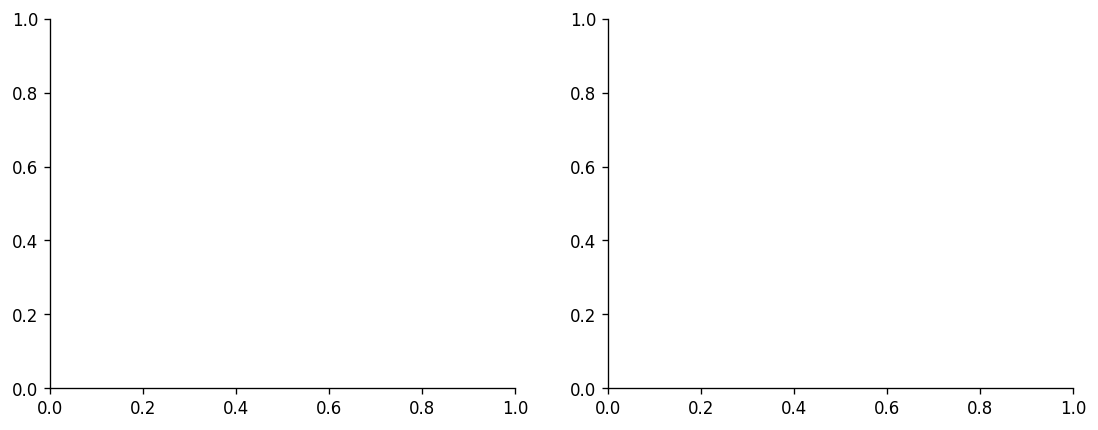

In [85]:
TEST_P={}

TEST_ROWS=[]

for key in FINAL_KEYS:
    rec=REGISTRY[key]; path=ROOT/f'predictions/{key}.csv'
    start=time.perf_counter(); p=predict_registered(rec,test.tweet.tolist(),'test'); elapsed=time.perf_counter()-start
    TEST_P[key]=p; pred=(p>=rec['threshold']).astype(int)
    export_p=sentiment_predict(test.tweet.tolist(),'test')[0] if rec['kind']=='sentiment' else p
    pd.DataFrame({'id':test.id,'y_true':test.y,'y_pred':pred,'probability':np.asarray(export_p,dtype=np.float64)}).to_csv(path,index=False)
    row=row_for_key(key); row.update({'test_'+k:v for k,v in scores(test.y,p,rec['threshold']).items()})
    # AP B2 doit utiliser la probabilité de sentiment, pas seulement la décision binaire.
    if rec['kind']=='sentiment': row['test_pr_auc_ap']=float(average_precision_score(test.y,sentiment_predict(test.tweet.tolist(),'test')[0]))
    row['test_inference_total_seconds']=elapsed; row['test_pipeline_ms_per_tweet']=1000*elapsed/len(test)
    row['artifact_size_mb']=(ROOT/rec['path']).stat().st_size/1e6 if (ROOT/rec['path']).is_file() else sum(f.stat().st_size for f in (ROOT/rec['path']).glob('*') if f.is_file())/1e6
    TEST_ROWS.append(row.copy()); pd.DataFrame(RESULTS).to_csv(ROOT/'results/results.csv',index=False)
    print(key,'F1 test',round(row['test_f1_sarcastique'],4),flush=True)

summary=pd.DataFrame(TEST_ROWS)

display(summary[['model','seed','threshold','test_f1_sarcastique','test_macro_f1','test_pr_auc_ap']])

fig,axes=plt.subplots(1,2,figsize=(11,4))

### Cellule de code 086 — Tracer l’effet du seuil sur le test à titre diagnostique

**Objectif.** Étudier comment un changement de distribution peut déplacer le compromis précision/rappel.

**Comprendre le code.** Pour la graine 42 de chaque famille, une grille de 201 seuils entre 0 et 1 fournit F1=f(seuil). Un point marque le seuil utilisable, déjà choisi sur val. La courbe PR est également construite. Le meilleur seuil calculé directement sur les labels test est stocké séparément avec son F1, sous l’étiquette posthoc.

**Résultat attendu à l’exécution.** Les courbes sont alimentées et `threshold_rows` compare seuil val et seuil test a posteriori.

**À retenir.** Le maximum test est une description optimiste obtenue en connaissant les réponses. Il n’est jamais autorisé à remplacer le seuil val pour annoncer la performance finale ou choisir le modèle de production.

In [86]:
threshold_rows=[]

for family,keys in FINAL_GROUPS.items():
    key=keys[0]; p=TEST_P[key]; t=REGISTRY[key]['threshold']; grid=np.linspace(0,1,201)
    f=[f1_score(test.y,p>=g,zero_division=0) for g in grid]
    axes[0].plot(grid,f,label=family); axes[0].scatter([t],[f1_score(test.y,p>=t)],s=20)
    prec,rec,_=precision_recall_curve(test.y,p); axes[1].plot(rec,prec,label=family)
    post=best_threshold(test.y,p)
    threshold_rows.append({'famille':family,'seuil_val':t,'seuil_test_posthoc':post,
        'f1_test_seuil_val':scores(test.y,p,t)['f1_sarcastique'],'f1_test_posthoc':scores(test.y,p,post)['f1_sarcastique']})

### Cellule de code 087 — Présenter et sauvegarder le diagnostic de seuil

**Objectif.** Rendre explicite la différence entre réglage utilisable et observation a posteriori.

**Comprendre le code.** La cellule ajoute titres, axes et légendes aux courbes précédentes. L’image `threshold_and_pr_test.png` et le tableau `threshold_shift.csv` sont sauvegardés, puis les valeurs sont affichées. La courbe précision-rappel expose plusieurs compromis sans en choisir un nouveau pour le modèle final.

**Résultat attendu à l’exécution.** Une figure à deux panneaux et un tableau lisible documentent le décalage de seuil.

**À retenir.** Un grand écart entre seuils peut signaler prior, calibration ou distribution différents. Il ne suffit pas à attribuer tout l’écart au seul prior, car vocabulaire, dialectes et autres caractéristiques peuvent aussi changer.

In [87]:
axes[0].set(title='Test diagnostic a posteriori uniquement',xlabel='Seuil',ylabel='F1 sarcastique')

axes[0].legend()

axes[1].set(title='Courbes précision rappel test',xlabel='Rappel',ylabel='Précision')

axes[1].legend()

savefig(fig,'threshold_and_pr_test')

pd.DataFrame(threshold_rows).to_csv(ROOT/'results/threshold_shift.csv',index=False)

display(pd.DataFrame(threshold_rows))

,famille,seuil_val,seuil_test_posthoc,f1_test_seuil_val,f1_test_posthoc
0,A,0.516072,0.458968,0.536913,0.551142
1,C,0.615209,0.570243,0.544760,0.552323
2,D,0.698322,0.572322,0.596187,0.633741
3,E1,0.520801,0.224268,0.624795,0.638743
4,E2,0.490785,0.298287,0.623932,0.638007


### F3 Sous groupes et F4 suppression des indices

Les sous-groupes avec/sans URL sont évalués à seuil inchangé. Le faible nombre de positifs
d'un groupe rend son F1 instable ; on affiche donc toujours n et le nombre de sarcastiques.
Pour F4 on conserve, pour chaque modèle, les tweets réellement sarcastiques correctement
détectés avant modification. On retire emojis, rires et suites de ponctuation ; la chute
est $1-\mathrm{rappel}_{après}$ sur ce **même ensemble conditionnel**, pas une chute de F1 globale.
Ce test artificiel ne sépare pas parfaitement information sémantique et changement de distribution.

### Cellule de code 088 — Évaluer les sous-groupes et retirer les indices des vrais positifs

**Objectif.** Compléter le score global par des mesures de robustesse ciblées, sans changer le seuil.

**Comprendre le code.** Pour chaque famille à graine 42, les scores sont calculés avec/sans URL et par dialecte, en affichant effectifs et positifs. F4 sélectionne ensuite les vrais positifs du modèle original : les textes sont modifiés par `erase_cues`, puis repassés dans le même modèle. La proportion encore détectée est comparée au taux initial de 1 sur ce même ensemble conditionnel.

**Résultat attendu à l’exécution.** `subgroups.csv` et `cues_ablation.csv` rapportent les sous-groupes et la chute de détection.

**À retenir.** Cette chute n’est ni une baisse de F1 sur tout le test ni un rappel global. Le sous-ensemble varie selon le modèle ; les différences entre familles doivent donc être lues avec leurs effectifs de vrais positifs initiaux.

In [88]:
subgroups=[]

cue_rows=[]

url_flags=text_features(test.tweet).url.to_numpy()

for family,keys in FINAL_GROUPS.items():
    key=keys[0]; rec=REGISTRY[key]; p=TEST_P[key]; t=rec['threshold']
    for group in [False,True]:
        mask=url_flags==group
        subgroups.append({'famille':family,'URL':group,'n':int(mask.sum()),'positifs':int(test.y[mask].sum()),**scores(test.y[mask],p[mask],t)})
    for dialect in sorted(test.dialect.unique()):
        mask=test.dialect.eq(dialect).to_numpy()
        subgroups.append({'famille':family,'dialecte':dialect,'n':int(mask.sum()),'positifs':int(test.y[mask].sum()),**scores(test.y[mask],p[mask],t)})
    mask=(test.y.to_numpy()==1)&(p>=t); texts=[erase_cues(s) for s in test.tweet[mask]]
    if texts:
        modified=predict_registered(rec,texts,f'cues_{family}')
        after=float(np.mean(modified>=t))
        cue_rows.append({'famille':family,'n_initialement_detectes':int(mask.sum()),'taux_detection_avant':1.,'taux_detection_apres':after,'chute':1-after})

pd.DataFrame(subgroups).to_csv(ROOT/'results/subgroups.csv',index=False)

pd.DataFrame(cue_rows).to_csv(ROOT/'results/cues_ablation.csv',index=False)

display(pd.DataFrame(subgroups))

display(pd.DataFrame(cue_rows))

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it

,famille,URL,n,positifs,f1_sarcastique,precision,recall,macro_f1,pr_auc_ap,dialecte
0,A,False,2560,805,0.543700,0.500522,0.595031,0.652136,0.542740,NaN
1,A,True,440,16,0.076923,0.100000,0.062500,0.524410,0.089224,NaN
2,A,NaN,306,155,0.683473,0.603960,0.787097,0.620168,0.727252,egypt
3,A,NaN,322,57,0.393939,0.346667,0.456140,0.618845,0.397931,gulf
4,A,NaN,47,14,0.588235,0.500000,0.714286,0.677451,0.465987,levant
5,A,NaN,2,0,0.000000,0.000000,0.000000,1.000000,NaN,magreb
6,A,NaN,2323,595,0.509091,0.480597,0.541176,0.662709,0.489608,msa
7,C,False,2560,805,0.559140,0.513514,0.613665,0.663405,0.560018,NaN
8,C,True,440,16,0.153846,0.102041,0.312500,0.543181,0.167797,NaN
9,C,NaN,306,155,0.698163,0.588496,0.858065,0.600164,0.708153,egypt


,famille,n_initialement_detectes,taux_detection_avant,taux_detection_apres,chute
0,A,480,1.0,0.906250,0.093750
1,C,499,1.0,0.947896,0.052104
2,D,516,1.0,0.934109,0.065891
3,E1,572,1.0,0.942308,0.057692
4,E2,584,1.0,0.953767,0.046233


### F2 Dialecte égyptien non vu et F3 réentraînement sans liens

Le meilleur **modèle E selon validation** est réentraîné depuis son checkpoint préentraîné
sans aucun tweet egypt dans train. Sa validation utilise seulement les tweets non egypt,
pour que le choix du checkpoint et du seuil ne consulte pas ce dialecte. L'architecture
et lambda restent ceux du protocole principal : cette ablation n'est pas une sélection
entièrement aveugle au dialecte, et le préentraînement externe peut aussi contenir de l'égyptien.
La validation générale
est conservée dans le journal pour les comparaisons, mais le checkpoint, l'arrêt précoce et
le seuil employé sur egypt utilisent uniquement ce sous-ensemble non egypt.
Le second réentraînement retire URL et mentions à train, val et test ; les hyperparamètres
viennent du modèle E verrouillé. Ces deux expériences de diagnostic ne remplacent pas le modèle final.

### Cellule de code 089 — Fixer le meilleur modèle E pour l’ablation dialectale

**Objectif.** Choisir la référence de réentraînement sans dialecte égyptien à partir de validation.

**Comprendre le code.** La moyenne F1 val des groupes E1 et E2 est comparée. La graine 42 de la famille gagnante fournit encodeur, architecture mono/multi et lambda de référence. Sa configuration est copiée afin de construire des variantes sans modifier les paramètres enregistrés du modèle original. Une liste vide accueillera les diagnostics de réentraînement.

**Résultat attendu à l’exécution.** `erec`, `ecfg`, `ename` et `robust_rows` préparent les cellules F2/F3 suivantes.

**À retenir.** Le modèle de référence est choisi sur val, pas selon son résultat sur les tweets egypt test. La sélection principale a cependant vu des exemples egypt : ce point limitera la revendication de dialecte entièrement non vu.

In [89]:
best_e_family=max(['E1','E2'],key=lambda f:np.mean([row_for_key(k)['val_f1_sarcastique'] for k in FINAL_GROUPS[f]]))

best_e_key=FINAL_GROUPS[best_e_family][0]

erec=REGISTRY[best_e_key]

ecfg=erec['config'].copy()

ename=ecfg['model_name']

robust_rows=[]

### Cellule de code 090 — Réentraîner A, C et D sans URL ni mention

**Objectif.** Mesurer l’effet des raccourcis après adaptation du modèle, au lieu de seulement supprimer des éléments à l’inférence.

**Comprendre le code.** Les configurations A/C/D retenues sont reconstruites à graine 42. Les liens et mentions sont retirés des textes de train, val et test. A apprend un nouveau TF-IDF ; C garde son architecture et son vocabulaire de référence pour cette ablation ; D utilise de nouvelles extractions gelées sur les textes modifiés puis apprend une nouvelle tête. Chaque variante choisit son seuil sur val et est comparée à son original sur le même test.

**Résultat attendu à l’exécution.** Trois lignes de robustesse et leurs fichiers de prédictions sont ajoutés, sans remplacer les résultats des modèles finaux.

**À retenir.** Cette cellule lance des entraînements et éventuellement des extractions, même si les encodeurs D sont gelés. Une différence combine l’effet du retrait des indices et celui du réapprentissage ; ce n’est pas la même question que F4.

In [90]:
for family in ['A','C','D']:
    reference_key=FINAL_GROUPS[family][0]; reference=REGISTRY[reference_key]; cfg=reference['config'].copy()
    seed_all(42); name=f'F_{family}_sans_url_mention'
    if family=='A':
        key=run_tfidf(name,cfg['mode'],cfg['imbalance'],42,True)
        p=predict_registered(REGISTRY[key],test.tweet.tolist(),'test')
    elif family=='C':
        xt=[word_encode([prepare_text(s,drop_links=True) for s in train.tweet])]
        xv=[word_encode([prepare_text(s,drop_links=True) for s in val.tweet])]
        emb=ARAVEC if cfg['embedding']=='aravec' else None
        cfg['drop_links']=True
        key,model=train_neural(StaticNet(cfg['arch'],emb,position=cfg.get('position',True),freeze=emb is not None),xt,xv,name,
            config=cfg,imbalance=cfg.get('imbalance','weighted'),freeze_epochs=cfg.get('freeze_epochs',0))
        p=neural_predict(model,[word_encode([prepare_text(s,drop_links=True) for s in test.tweet])]); del model; gc.collect()
    else:
        # Extraction sans URL/mention ; mêmes poids gelés, nouvelle tête entraînée sur train seulement.
        ht,mt=frozen_features([MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in train.tweet],'train_without_links')
        hv,mv=frozen_features([MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in val.tweet],'val_without_links')
        hx,mx=frozen_features([MENTION_RE.sub(' ',URL_RE.sub(' ',s)) for s in test.tweet],'test_without_links')
        if reference['kind']=='frozen_lr':
            pooling=cfg['pooling']; model=LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=42)
            start=time.perf_counter(); model.fit(pooled_features(ht,mt,pooling),train.y); seconds=time.perf_counter()-start
            path=ROOT/f'models/{name}_seed42.joblib'; joblib.dump(model,path)
            key=register(name,42,model.predict_proba(pooled_features(hv,mv,pooling))[:,1],seconds,model.coef_.size+1,
                'arabert_official_without_links','frozen_lr',path,dict(cfg,drop_links=True))
            p=model.predict_proba(pooled_features(hx,mx,pooling))[:,1]
        else:
            key,model=train_neural(FrozenHead(),[torch.tensor(np.asarray(ht)),torch.tensor(mt)],
                [torch.tensor(np.asarray(hv)),torch.tensor(mv)],name,config=dict(cfg,drop_links=True))
            p=neural_predict(model,[torch.tensor(np.asarray(hx)),torch.tensor(mx)]); del model; gc.collect()
    threshold=REGISTRY[key]['threshold']; rr={'diagnostic':f'{family}_sans_url_mention','n_train':len(train),'n_test':len(test),
        'threshold':threshold,**scores(test.y,p,threshold),'f1_reference':scores(test.y,TEST_P[reference_key],reference['threshold'])['f1_sarcastique']}
    robust_rows.append(rr); row_for_key(key).update({'test_'+k:v for k,v in scores(test.y,p,threshold).items()})
    pd.DataFrame({'id':test.id,'y_true':test.y,'y_pred':(p>=threshold).astype(int),'probability':np.asarray(p,dtype=np.float64)}).to_csv(ROOT/f'predictions/{key}.csv',index=False)

F_A_sans_url_mention_seed42 F1 val = 0.5045 seuil = 0.5117 temps = 5.4 s
F_C_sans_url_mention 42 époque 1 perte 0.5777 F1 val 0.5291
F_C_sans_url_mention 42 époque 2 perte 0.5258 F1 val 0.5125
F_C_sans_url_mention 42 époque 3 perte 0.5198 F1 val 0.5265
F_C_sans_url_mention_seed42 F1 val = 0.5291 seuil = 0.6468 temps = 6.9 s


Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction AraBERT train_without_links 1600 / 10842
Extraction AraBERT train_without_links 3200 / 10842
Extraction AraBERT train_without_links 4800 / 10842
Extraction AraBERT train_without_links 6400 / 10842
Extraction AraBERT train_without_links 8000 / 10842
Extraction AraBERT train_without_links 9600 / 10842
Extraction AraBERT test_without_links 1600 / 3000
F_D_sans_url_mention 42 époque 1 perte 0.4475 F1 val 0.6544
F_D_sans_url_mention 42 époque 2 perte 0.3458 F1 val 0.6437
F_D_sans_url_mention 42 époque 3 perte 0.2693 F1 val 0.6421
F_D_sans_url_mention_seed42 F1 val = 0.6544 seuil = 0.665 temps = 12.2 s


### Cellule de code 091 — Réentraîner E sans egypt et sans liens

**Objectif.** Tester deux difficultés de généralisation avec des variantes séparées du fine-tuning complet.

**Comprendre le code.** Trois runs sont prévus : meilleur E sans egypt, E1 sans URL/mention et E2 sans URL/mention. Pour sans egypt, train et validation de sélection excluent ce dialecte ; le seuil est donc choisi uniquement sur val non egypt. Son score est comparé sur le sous-ensemble egypt test à la référence entraînée sur tout train. Les variantes sans liens gardent tout train, retirent URL/mention partout et évaluent le test complet. Les CSV conservent toutes les lignes, avec le sous-ensemble évalué précisé dans le journal.

**Résultat attendu à l’exécution.** Trois diagnostics supplémentaires, dont un score ciblé egypt, sont exportés avec leurs probabilités.

**À retenir.** L’architecture et le lambda de sans egypt héritent du protocole principal : ce n’est pas une sélection entièrement aveugle à ce dialecte. Le préentraînement externe peut aussi en contenir. Ces runs ne remplacent pas les modèles finaux verrouillés.

In [91]:
for diagnostic in ['sans_egypt','E1_sans_url_mention','E2_sans_url_mention']:
    reference_e=erec if diagnostic=='sans_egypt' else REGISTRY[FINAL_GROUPS[diagnostic[:2]][0]]
    ecfg=reference_e['config'].copy(); ename=ecfg['model_name']
    subset=train.loc[~train.dialect.eq('egypt')] if diagnostic=='sans_egypt' else train
    drop=diagnostic!='sans_egypt'; cfg=dict(ecfg,train_ids=subset.id.tolist(),drop_links=drop)
    xt=plm_encode(subset.tweet.tolist(),ename,drop); xv=plm_encode(val.tweet.tolist(),ename,drop)
    seed_all(42)
    key,model=train_neural(FineTuneNet(ename,ecfg['multitask']),xt,xv,f'F_{diagnostic}',config=cfg,
        epochs=PLM_EPOCHS,lr=2e-5,lam=ecfg['lam'],plm=True,
        labels=torch.tensor(subset.y.to_numpy(),dtype=torch.long),sentiments=torch.tensor(subset.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long),
        val_mask=(~val.dialect.eq('egypt').to_numpy()) if diagnostic=='sans_egypt' else None)
    pv=neural_predict(model,xv,batch=BATCH)
    vm=~val.dialect.eq('egypt').to_numpy() if diagnostic=='sans_egypt' else np.ones(len(val),dtype=bool)
    threshold=best_threshold(val.y[vm],pv[vm])
    REGISTRY[key]['threshold']=threshold
    row_for_key(key).update({'val_'+k:v for k,v in scores(val.y,pv,threshold).items()})
    pp=neural_predict(model,plm_encode(test.tweet.tolist(),ename,drop),batch=BATCH)
    tm=test.dialect.eq('egypt').to_numpy() if diagnostic=='sans_egypt' else np.ones(len(test),dtype=bool)
    rr={'diagnostic':diagnostic,'n_train':len(subset),'n_test':int(tm.sum()),'threshold':threshold,
        **scores(test.y[tm],pp[tm],threshold),
        'f1_reference':scores(test.y[tm],TEST_P[reference_e['key']][tm],reference_e['threshold'])['f1_sarcastique']}
    robust_rows.append(rr)
    row_for_key(key).update({'test_'+k:v for k,v in scores(test.y[tm],pp[tm],threshold).items()})
    row_for_key(key).update({'threshold':threshold,'test_subset':'egypt' if diagnostic=='sans_egypt' else 'all','n_test_evaluated':int(tm.sum())})
    pd.DataFrame({'id':test.id,'y_true':test.y,'y_pred':(pp>=threshold).astype(int),'probability':np.asarray(pp,dtype=np.float64)}).to_csv(ROOT/f'predictions/{key}.csv',index=False)
    del model,xt,xv; gc.collect()

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


F_sans_egypt 42 époque 1 batch 50 / 267 perte 0.9706
F_sans_egypt 42 époque 1 batch 100 / 267 perte 0.9247
F_sans_egypt 42 époque 1 batch 150 / 267 perte 0.8311
F_sans_egypt 42 époque 1 batch 200 / 267 perte 0.7916
F_sans_egypt 42 époque 1 batch 250 / 267 perte 0.7493
F_sans_egypt 42 époque 1 perte 0.7419 F1 val 0.6357
F_sans_egypt 42 époque 2 batch 50 / 267 perte 0.5086
F_sans_egypt 42 époque 2 batch 100 / 267 perte 0.4892
F_sans_egypt 42 époque 2 batch 150 / 267 perte 0.4967
F_sans_egypt 42 époque 2 batch 200 / 267 perte 0.4958
F_sans_egypt 42 époque 2 batch 250 / 267 perte 0.4972
F_sans_egypt 42 époque 2 perte 0.4904 F1 val 0.6258
F_sans_egypt 42 époque 3 batch 50 / 267 perte 0.3802
F_sans_egypt 42 époque 3 batch 100 / 267 perte 0.3865
F_sans_egypt 42 époque 3 batch 150 / 267 perte 0.386
F_sans_egypt 42 époque 3 batch 200 / 267 perte 0.3791
F_sans_egypt 42 époque 3 batch 250 / 267 perte 0.375
F_sans_egypt 42 époque 3 perte 0.3721 F1 val 0.6361
F_sans_egypt_seed42 F1 val = 0.6761 seu

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


F_E1_sans_url_mention 42 époque 1 batch 50 / 339 perte 0.6723
F_E1_sans_url_mention 42 époque 1 batch 100 / 339 perte 0.6265
F_E1_sans_url_mention 42 époque 1 batch 150 / 339 perte 0.5713
F_E1_sans_url_mention 42 époque 1 batch 200 / 339 perte 0.535
F_E1_sans_url_mention 42 époque 1 batch 250 / 339 perte 0.5056
F_E1_sans_url_mention 42 époque 1 batch 300 / 339 perte 0.496
F_E1_sans_url_mention 42 époque 1 perte 0.4867 F1 val 0.6782
F_E1_sans_url_mention 42 époque 2 batch 50 / 339 perte 0.2967
F_E1_sans_url_mention 42 époque 2 batch 100 / 339 perte 0.3105
F_E1_sans_url_mention 42 époque 2 batch 150 / 339 perte 0.3131
F_E1_sans_url_mention 42 époque 2 batch 200 / 339 perte 0.3164
F_E1_sans_url_mention 42 époque 2 batch 250 / 339 perte 0.3122
F_E1_sans_url_mention 42 époque 2 batch 300 / 339 perte 0.3092
F_E1_sans_url_mention 42 époque 2 perte 0.3059 F1 val 0.6653
F_E1_sans_url_mention 42 époque 3 batch 50 / 339 perte 0.1918
F_E1_sans_url_mention 42 époque 3 batch 100 / 339 perte 0.2101
F

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


F_E2_sans_url_mention 42 époque 1 batch 50 / 339 perte 0.9946
F_E2_sans_url_mention 42 époque 1 batch 100 / 339 perte 0.9286
F_E2_sans_url_mention 42 époque 1 batch 150 / 339 perte 0.8481
F_E2_sans_url_mention 42 époque 1 batch 200 / 339 perte 0.7941
F_E2_sans_url_mention 42 époque 1 batch 250 / 339 perte 0.7523
F_E2_sans_url_mention 42 époque 1 batch 300 / 339 perte 0.7317
F_E2_sans_url_mention 42 époque 1 perte 0.7155 F1 val 0.675
F_E2_sans_url_mention 42 époque 2 batch 50 / 339 perte 0.4649
F_E2_sans_url_mention 42 époque 2 batch 100 / 339 perte 0.4794
F_E2_sans_url_mention 42 époque 2 batch 150 / 339 perte 0.4872
F_E2_sans_url_mention 42 époque 2 batch 200 / 339 perte 0.4892
F_E2_sans_url_mention 42 époque 2 batch 250 / 339 perte 0.4827
F_E2_sans_url_mention 42 époque 2 batch 300 / 339 perte 0.4803
F_E2_sans_url_mention 42 époque 2 perte 0.4771 F1 val 0.6612
F_E2_sans_url_mention 42 époque 3 batch 50 / 339 perte 0.3538
F_E2_sans_url_mention 42 époque 3 batch 100 / 339 perte 0.364
F

### Cellule de code 092 — Rassembler les résultats des réentraînements de robustesse

**Objectif.** Lire les effets des ablations avec les mêmes colonnes de comparaison.

**Comprendre le code.** `robust_rows` contient les six diagnostics des cellules précédentes : cinq variantes sans liens et le meilleur E sans egypt. La table précise méthode, effectifs, seuil, métriques et F1 de référence sur le sous-ensemble correspondant. Elle est sauvegardée dans `retraining_robustness.csv` puis affichée.

**Résultat attendu à l’exécution.** Un tableau unique permet d’identifier gain, stabilité ou dégradation selon le diagnostic.

**À retenir.** Comparer les scores sur le même périmètre : un F1 egypt ne se compare pas directement à un F1 de tout le test. Les différences sont des résultats d’ablation du corpus observé, pas une garantie de comportement sur de nouvelles sources.

In [92]:
pd.DataFrame(robust_rows).to_csv(ROOT/'results/retraining_robustness.csv',index=False)

display(pd.DataFrame(robust_rows))

,diagnostic,n_train,n_test,threshold,f1_sarcastique,precision,recall,macro_f1,pr_auc_ap,f1_reference
0,A_sans_url_mention,10842,3000,0.511684,0.507514,0.482948,0.534714,0.653991,0.521348,0.536913
1,C_sans_url_mention,10842,3000,0.646785,0.543025,0.483810,0.618758,0.667977,0.538624,0.544760
2,D_sans_url_mention,10842,3000,0.665025,0.590565,0.565848,0.617540,0.713214,0.623948,0.596187
3,sans_egypt,8522,306,0.611266,0.767372,0.721591,0.819355,0.746675,0.810154,0.773639
4,E1_sans_url_mention,10842,3000,0.708490,0.602740,0.589744,0.616322,0.724189,0.641555,0.624795
5,E2_sans_url_mention,10842,3000,0.662346,0.619943,0.582441,0.662607,0.731408,0.643582,0.623932


### F5 Incertitude statistique

Pour chaque modèle final, bootstrap de **1 000** échantillons de la taille du test, avec
remise. Le modèle, ses probabilités et son seuil restent fixes. Les percentiles 2,5 et 97,5
donnent un IC empirique à 95 %. Il porte sur des tweets supposés indépendants ; des groupes
de doublons et de provenance peuvent rendre l'IC trop optimiste.
Le test exact de McNemar porte sur les désaccords de correction de deux modèles choisis
selon validation, avec leur graine 42. Il teste une différence de taux d'erreur, **pas
directement une différence de F1** ; p < 0,05 n'est pas une mesure de taille d'effet.

### Cellule de code 093 — Calculer les intervalles bootstrap à 95 %

**Objectif.** Quantifier l’incertitude due aux tweets du test pour un modèle et un seuil fixés.

**Comprendre le code.** Pour chacun des 15 runs des cinq familles entraînées, 1 000 jeux d’indices sont tirés avec remise, chacun de la taille du test. Le F1 est recalculé sur chaque rééchantillon en gardant les prédictions originales. Les percentiles 2,5 et 97,5 fournissent les bornes empiriques. Aucun réseau n’est réentraîné dans cette étape.

**Exemple ou repère.** Dans un rééchantillon, le même tweet peut apparaître plusieurs fois et un autre ne pas apparaître : c’est le principe du tirage avec remise, pas une modification du jeu test officiel exporté.

**Résultat attendu à l’exécution.** `bootstrap.csv` contient un F1 et un intervalle par modèle/graine, avec `resamples=1000`.

**À retenir.** Cet intervalle est conditionnel au modèle entraîné. Il diffère de l’écart-type entre graines et suppose des tweets suffisamment indépendants ; doublons ou groupes de provenance peuvent rendre l’incertitude trop optimiste.

In [93]:
from scipy.stats import binomtest

rng=np.random.default_rng(42)

ytest=test.y.to_numpy()

bootstrap_rows=[]

for family,keys in FINAL_GROUPS.items():
    for key in keys:
        pred=TEST_P[key]>=REGISTRY[key]['threshold']; vals=[]
        for b in range(1000):
            idx=rng.integers(0,len(test),len(test)); yy=ytest[idx]; pp=pred[idx]
            tp=np.sum((yy==1)&pp); fp=np.sum((yy==0)&pp); fn=np.sum((yy==1)&~pp)
            vals.append(2*tp/max(2*tp+fp+fn,1))
        lo,hi=np.percentile(vals,[2.5,97.5])
        bootstrap_rows.append({'family':family,'model':key,'f1':scores(ytest,TEST_P[key],REGISTRY[key]['threshold'])['f1_sarcastique'],'ci_low':lo,'ci_high':hi,'resamples':1000})

bootstrap=pd.DataFrame(bootstrap_rows)

bootstrap.to_csv(ROOT/'results/bootstrap.csv',index=False)

display(bootstrap)

,family,model,f1,ci_low,ci_high,resamples
0,A,A_tfidf_conservateur_seed42,0.536913,0.509285,0.566041,1000
1,A,A_tfidf_conservateur_seed43,0.536913,0.508319,0.564501,1000
2,A,A_tfidf_conservateur_seed44,0.536913,0.507218,0.566506,1000
3,C,C3_AraVec_seed42,0.544760,0.517157,0.572941,1000
4,C,C3_AraVec_seed43,0.544638,0.518268,0.573123,1000
5,C,C3_AraVec_seed44,0.531210,0.502259,0.559646,1000
6,D,D2_BiLSTM_attention_seed42,0.596187,0.568875,0.622812,1000
7,D,D2_BiLSTM_attention_seed43,0.603708,0.576400,0.630339,1000
8,D,D2_BiLSTM_attention_seed44,0.579949,0.553144,0.611754,1000
9,E1,E1_AraBERT_mono_seed42,0.624795,0.599662,0.648740,1000


### Cellule de code 094 — Comparer deux modèles avec McNemar exact

**Objectif.** Tester si leurs désaccords de correction sont équilibrés sur les mêmes tweets.

**Comprendre le code.** Les deux familles sont retenues selon leur moyenne F1 val, puis comparées à graine 42. Les vecteurs `c1` et `c2` indiquent si chaque décision est correcte. `b` compte les tweets réussis seulement par le premier, `c` ceux réussis seulement par le second. Sous l’hypothèse d’égalité, la répartition des désaccords est testée avec une binomiale de paramètre 0,5. Sans désaccord, la p-valeur est fixée à 1.

**Résultat attendu à l’exécution.** Le dictionnaire `mcnemar` contient les deux modèles, les effectifs discordants et la p-valeur exacte bilatérale.

**À retenir.** McNemar compare des taux d’erreur appariés, pas directement le F1 sarcastique. Une petite p-valeur n’indique ni la taille du gain ni son utilité pratique ; lire aussi les métriques et intervalles.

In [94]:
family_rank=sorted(FINAL_GROUPS,key=lambda f:np.mean([row_for_key(k)['val_f1_sarcastique'] for k in FINAL_GROUPS[f]]),reverse=True)

k1,k2=[FINAL_GROUPS[f][0] for f in family_rank[:2]]

c1=(TEST_P[k1]>=REGISTRY[k1]['threshold'])==ytest

c2=(TEST_P[k2]>=REGISTRY[k2]['threshold'])==ytest

b=int(np.sum(c1&~c2))

c=int(np.sum(~c1&c2))

pvalue=binomtest(b,b+c,.5).pvalue if b+c else 1.

mcnemar={'model_1':k1,'model_2':k2,'b_correct_1_only':b,'c_correct_2_only':c,'pvalue_exact':pvalue}

### Cellule de code 095 — Exporter le test statistique

**Objectif.** Rendre vérifiables les effectifs et le calcul de significativité.

**Comprendre le code.** Le dictionnaire construit auparavant est sauvegardé dans `mcnemar.json` et présenté sous forme de tableau vertical. Les noms des modèles et les comptes `b`/`c` accompagnent la p-valeur afin d’éviter un résultat statistique isolé de sa comparaison réelle.

**Résultat attendu à l’exécution.** Un fichier JSON et une table de McNemar sont disponibles dans les livrables.

**À retenir.** Ne pas résumer la conclusion à significatif/non significatif. La sélection sur val, les hypothèses d’indépendance et la portée d’un test sur les erreurs doivent rester expliquées.

In [95]:
(ROOT/'results/mcnemar.json').write_text(json.dumps(mcnemar,indent=2))

display(pd.Series(mcnemar).to_frame('McNemar'))

,McNemar
model_1,E2_AraBERT_lambda0p3_seed42
model_2,D2_BiLSTM_attention_seed42
b_correct_1_only,151
c_correct_2_only,156
pvalue_exact,0.819465


### F6 Trente erreurs à lire et à qualifier

On prélève 15 faux négatifs et 15 faux positifs du modèle retenu sur validation. Les tweets,
leur dialecte, leur sentiment et leur probabilité sont affichés. Une première catégorie
descriptive repose sur des indices observables ; elle reste une **hypothèse de lecture**.
« contexte requis » ou « bruit d'annotation » ne peut pas être certifié automatiquement.
Le bruit contradictoire n'est déclaré certain que lorsqu'une même clé possède des labels
opposés ; même alors, le contexte original manquant peut expliquer l'écart. Le fichier
permet une relecture humaine et n'invente pas de pourcentage de bruit à partir d'une intuition.

### Cellule de code 096 — Prélever les erreurs du modèle retenu

**Objectif.** Préparer une analyse qualitative de faux négatifs et de fausses alertes.

**Comprendre le code.** La première famille du classement val fournit son run graine 42 et son seuil déjà fixé. Le code prend jusqu’à 15 FN et 15 FP dans l’ordre du test. Chaque ligne conserve texte, annotation, score, dialecte, sentiment et présence dans un groupe de clés contradictoires. Une catégorie provisoire est proposée à partir de marqueurs observables ; un champ rappelle la relecture humaine nécessaire.

**Résultat attendu à l’exécution.** Une table `errors` est construite. On attend 30 lignes si au moins 15 erreurs de chaque type existent ; sinon, le nombre réel doit être rapporté.

**À retenir.** Le prélèvement des premières erreurs n’est pas aléatoire ni représentatif de tous les échecs. Un marqueur, un dialecte ou une contradiction de clé ne suffit pas à certifier la cause d’une erreur ou un bruit d’annotation.

In [96]:
chosen_final_family=family_rank[0]

CHOSEN_KEY=FINAL_GROUPS[chosen_final_family][0]

chosen_rec=REGISTRY[CHOSEN_KEY]

chosen_p=TEST_P[CHOSEN_KEY]

chosen_pred=chosen_p>=chosen_rec['threshold']

errors=[]

for kind,mask in [('FN',(ytest==1)&~chosen_pred),('FP',(ytest==0)&chosen_pred)]:
    ids=np.flatnonzero(mask)[:15]
    for i in ids:
        r=test.iloc[i]; cues=bool(re.search(r'ه{2,}|[!?؟]{2,}',r.tweet) or emoji.get_emoji_regexp().search(r.tweet))
        contradictory=r.key in all_contradictions
        category='labels contradictoires observés' if contradictory else ('marqueur mal interprété possible' if cues else ('dialecte et contexte à examiner' if r.dialect!='msa' else 'ironie sans marqueur ou contexte requis'))
        errors.append({'id':int(r.id),'type':kind,'tweet':r.tweet,'y_true':int(r.y),'probability':float(chosen_p[i]),
            'dialect':r.dialect,'sentiment':r.sentiment,'category_provisional':category,'contradictory_key':contradictory,
            'human_review':'À vérifier sur le texte et son contexte'})

errors=pd.DataFrame(errors)

### Cellule de code 097 — Afficher les erreurs et leurs catégories provisoires

**Objectif.** Fournir les éléments nécessaires à une relecture humaine traçable.

**Comprendre le code.** Le CSV `errors_30.csv` est écrit avec les textes arabes, puis affiché. Un regroupement par type d’erreur et catégorie fournit un premier comptage. Le message final donne l’effectif réel et le nombre de clés contradictoires dans cette sélection, au lieu de supposer automatiquement que 30 erreurs ont été obtenues.

**Résultat attendu à l’exécution.** Les erreurs sont lisibles dans le notebook et exportées pour annoter `human_review` avec des justifications.

**À retenir.** Les comptes automatiques décrivent des hypothèses, pas des catégories validées. Examiner contexte requis, ironie sans marqueur, marqueur mal interprété, dialecte et bruit possible ; ne jamais déduire un pourcentage certain de bruit de ces seules règles.

In [97]:
errors.to_csv(ROOT/'results/errors_30.csv',index=False,encoding='utf-8-sig')

display(errors)

display(errors.groupby(['type','category_provisional']).size().rename('n').to_frame())

print('Nombre réel d’erreurs affichées :',len(errors),'— contradiction certaine dans cette sélection :',int(errors.contradictory_key.sum()))

,id,type,tweet,y_true,probability,dialect,sentiment,category_provisional,contradictory_key,human_review
0,1,FN,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,1,0.101634,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
1,7,FN,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراستنا كل مابتقرب من الواقع كل ماتقل ف المسافه لحد ما السقف يقع ع دماغك,1,0.024493,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
2,12,FN,إدارة #الاتحاد تطلب من الداهية الروماني بيتوركا عرض خطته وتشكيلته قبل كل مباراة ب 48 ساعة على لجنة فنية تضم مروان بصاص وحسن خليفة,1,0.008528,gulf,NEG,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
3,42,FN,يمكن يبغون تزيد خبرتهم في شراء التذاكر للمستقبل فبيتغير مستقبل التذاكر Ye never know ~,1,0.012124,gulf,NEU,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
4,57,FN,مصحبش فارافير 💪 https://t.co/DQFB5QIi8q,1,0.010408,msa,NEG,marqueur mal interprété possible,False,À vérifier sur le texte et son contexte
5,73,FN,مدحت شلبي : وادي حسام غالي و عبدالله السعيد فـ المدرجات .. كويس ان حسني عبدربه معترضش عليهم #الدوري_يا_اهلي #احسمها_يا_اهلي,1,0.012858,egypt,NEG,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
6,77,FN,مراسلي القنوات الرياضية مفترض أن يكون لديهم أكثر من لغة بالإضافة للعربية وليس يس ونو وهيلو وهواريو وولكم ;-),1,0.200382,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
7,97,FN,منا كتبت و الا انت مش شايف قاتك نيله يا متنيّل بس برضو دايماً انتا بتعمل اضافة كويسة بمداخلاتك يبو نورة,1,0.301516,egypt,NEU,dialecte et contexte à examiner,False,À vérifier sur le texte et son contexte
8,109,FN,في خطبة صلاة الجمعة المعممة على المساجد غدا، الأوقاف تدعو الناخبين إلى اختيار من يسهم في الأمر بالمعروف ووصف بالعلم والقوة والأمانة! !,1,0.035544,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte
9,146,FN,#بشار الأسد: نحن آخر معاقل العلمانية في المنطقة وشعارنا:الدين لله والكيماوي للجميع #سوريا,1,0.017160,msa,NEG,ironie sans marqueur ou contexte requis,False,À vérifier sur le texte et son contexte


n
type category_provisional                       
FN   dialecte et contexte à examiner           4
     ironie sans marqueur ou contexte requis   9
     marqueur mal interprété possible          2
FP   dialecte et contexte à examiner           2
     ironie sans marqueur ou contexte requis  10
     marqueur mal interprété possible          3

Nombre réel d’erreurs affichées : 30 — contradiction certaine dans cette sélection : 0


## Partie G Comparaison et décision de déploiement

Les performances sont agrégées sur trois graines pour les cinq familles finales entraînées.
Les deux méthodes sans apprentissage du sarcasme ont une seule exécution déterministe,
explicitement indiquée dans le tableau ; aucun écart-type d'optimisation n'est inventé.
`train_seconds` comprend entraînement et validations des époques ; l'extraction gelée D est
documentée séparément. La taille est celle du fichier de poids sauvegardé, pas la mémoire RAM.
Pour D1/D2 il faut ajouter la taille de l'encodeur AraBERT gelé ; une petite tête n'est pas
un système complet de quelques kilo-octets. La latence ci-dessous utilise un modèle déjà chargé,
un échauffement, trois passages batch 1 sur vingt tweets CPU ; tokenisation comprise.
Le modèle recommandé est choisi selon val ; on expose ensuite ses performances test sans
changer ce choix. Une décision réelle pour des tweets marocains exigerait un corpus marocain
indépendant, une annotation contrôlée et une évaluation temporelle ; le seul groupe magreb
ne garantit pas une couverture du darija marocain ni de l'Arabizi.

### Cellule de code 098 — Imposer le CPU pour la comparaison de latence

**Objectif.** Mesurer le coût d’inférence sur le matériel demandé, même si l’apprentissage avait utilisé CUDA ailleurs.

**Comprendre le code.** `DEVICE` est explicitement replacé sur CPU. Les fonctions de chargement et de prédiction qui consultent cette variable utiliseront ce périphérique pour G. La liste `comparison` accueillera ensuite les lignes agrégées des familles.

**Résultat attendu à l’exécution.** La configuration de benchmark CPU est active et la table de comparaison est initialisée.

**À retenir.** Cette affectation n’accélère pas les entraînements précédents et ne modifie pas leurs résultats. Elle évite simplement d’étiqueter par erreur une mesure GPU comme une latence CPU.

**Après CUDA.** Ce retour explicite au CPU est intentionnel : G compare les latences CPU, et non les latences T4. Les poids entraînés sont chargés avec `map_location=DEVICE`.

In [98]:
DEVICE=torch.device('cpu')  # G mesure toujours la latence CPU, même après entraînement CUDA.
comparison=[]

### Cellule de code 099 — Mesurer qualité, coût et latence des familles entraînées

**Objectif.** Comparer les cinq familles finales en tenant compte du système complet utilisé pour prédire.

**Comprendre le code.** Les F1 et AP test sont regroupés sur trois graines ; l’écart-type utilise `ddof=1`. Pour la latence, la graine 42 traite 20 tweets un par un, après échauffement et sur trois répétitions ; la médiane des durées moyennes par tweet est retenue. Les poids sont déjà chargés, mais préparation/tokenisation font partie du traitement. Pour D, l’encodeur AraBERT est exécuté et sa taille est ajoutée à celle de la tête.

**Résultat attendu à l’exécution.** Une ligne par famille rassemble moyenne/dispersion, durée train, millisecondes par tweet, taille en Mo décimaux et paramètres de la partie entraînable.

**À retenir.** La taille sur disque n’est pas la RAM maximale. La latence dépend des textes, de leur longueur et de la charge du CPU ; 20 tweets ne constituent pas un benchmark universel. La moyenne des durées train par run n’est pas le coût total de toutes les recherches de configurations.

In [99]:
for family,keys in FINAL_GROUPS.items():
    rows=[row_for_key(k) for k in keys]
    f=[r['test_f1_sarcastique'] for r in rows]
    key=keys[0]; rec=REGISTRY[key]
    latency=float('nan')
    if rec['kind'] in ['tfidf','static','plm']:
        model=load_registered(rec); sample=test.tweet.head(20).tolist()
        predict_registered(rec,sample[:1],model=model)
        durations=[]
        for repeat in range(3):
            start=time.perf_counter()
            for text in sample: predict_registered(rec,[text],model=model)
            durations.append((time.perf_counter()-start)*1000/len(sample))
        latency=float(np.median(durations)); del model; gc.collect()
    elif rec['kind'] in ['frozen_lr','frozen_head']:
        encoder=load_hf(ARA_NAME).eval(); head=load_registered(rec); tokenizer=tokenizer_ara
        sample=test.tweet.head(20).tolist(); durations=[]
        with torch.inference_mode():
            for repeat in range(4):
                start=time.perf_counter()
                for text in sample:
                    inp=plm_encode([text],ARA_NAME); ids,mask=[x.to(DEVICE) for x in inp]
                    length=int(mask.sum()); ids=ids[:,:length]; mask=mask[:,:length]
                    h=encoder(input_ids=ids,attention_mask=mask).last_hidden_state
                    if rec['kind']=='frozen_lr': head.predict_proba(pooled_features(h.cpu().numpy(),mask.cpu().numpy(),rec['config']['pooling']))
                    else: head(h,mask)
                if repeat: durations.append((time.perf_counter()-start)*1000/len(sample))
        latency=float(np.median(durations)); del encoder,head; gc.collect()
    size=rows[0]['artifact_size_mb']
    if rec['kind'] in ['frozen_lr','frozen_head']:
        encoder_files=list(Path(REVISIONS[ARA_NAME]['path']).glob('*.safetensors')) or list(Path(REVISIONS[ARA_NAME]['path']).glob('pytorch_model.bin'))
        size+=sum(f.stat().st_size for f in encoder_files)/1e6
    comparison.append({'family':family,'model':rec['name'],'n_seeds':len(keys),
        'val_f1_mean':np.mean([r['val_f1_sarcastique'] for r in rows]),'test_f1_mean':np.mean(f),'test_f1_std':np.std(f,ddof=1),
        'test_ap_mean':np.mean([r['test_pr_auc_ap'] for r in rows]),'train_seconds_mean':np.mean([r['train_seconds'] for r in rows]),
        'cpu_batch1_latency_ms':latency,'complete_weights_mb':size,'threshold_seed42':rec['threshold'],
        'trainable_parameters':rows[0]['trainable_parameters']})

Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertModel were not initialized from the model checkpoint at /content/TP2_ArSarcasme/models/hf/aubmindlab--bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it

### Cellule de code 100 — Mesurer le coût des deux méthodes directes

**Objectif.** Ne pas confondre absence d’entraînement sur ArSarcasm et inférence gratuite.

**Comprendre le code.** NLI et sentiment sont chargés sur CPU puis testés sur les mêmes 20 tweets, avec un passage d’échauffement et trois passages mesurés. Pour NLI, un tweet implique deux paires avec les hypothèses sarcastique/sérieuse ; sentiment calcule une classification. Les lignes indiquent une seule exécution et aucune durée d’apprentissage sur le corpus du TP.

**Résultat attendu à l’exécution.** Les lignes B1 et B2 sont ajoutées à la comparaison avec leur latence et taille d’artefact.

**À retenir.** Leur écart-type entre graines est laissé non défini : une seule exécution n’est pas trois répétitions. Pour un artefact stocké en dossier, la taille peut inclure les fichiers annexes ; garder cette convention en lisant les Mo annoncés.

In [100]:
for family,key in [('B1',best_nli_key),('B2',b2_key)]:
    rec=REGISTRY[key]; row=row_for_key(key); name=NLI_NAME if family=='B1' else SA_NAME
    model=load_hf(name,True).eval(); tok=AutoTokenizer.from_pretrained(REVISIONS[name]['path'],local_files_only=True)
    sample=test.tweet.head(20).tolist(); durations=[]
    with torch.inference_mode():
        for repeat in range(4):
            start=time.perf_counter()
            for text in sample:
                if family=='B1':
                    ids=tok(export_clean(text),truncation=True,max_length=MAX_LEN,add_special_tokens=False)['input_ids']
                    premise=tok.decode(ids,skip_special_tokens=True)
                    enc=tok([premise,premise],list(PROMPTS[rec['config']['language']]),padding=True,truncation='only_first',max_length=MAX_LEN+24,return_tensors='pt').to(DEVICE)
                    logits=model(**enc).logits
                    entail=next(i for i,label in model.config.id2label.items() if 'entail' in label.lower())
                    logits[:,entail].softmax(0)
                else:
                    enc=tok(export_clean(text),padding=True,truncation=True,max_length=MAX_LEN,return_tensors='pt').to(DEVICE)
                    model(**enc).logits.argmax(-1)
            if repeat: durations.append((time.perf_counter()-start)*1000/len(sample))
    comparison.append({'family':family,'model':rec['name'],'n_seeds':1,'val_f1_mean':row['val_f1_sarcastique'],
        'test_f1_mean':row['test_f1_sarcastique'],'test_f1_std':float('nan'),'test_ap_mean':row['test_pr_auc_ap'],
        'train_seconds_mean':0.,'cpu_batch1_latency_ms':float(np.median(durations)),
        'complete_weights_mb':row['artifact_size_mb'],'threshold_seed42':rec['threshold'],'trainable_parameters':0})
    del model; gc.collect()

### Cellule de code 101 — Exporter la comparaison et visualiser l’apprentissage

**Objectif.** Associer les résultats finaux aux trajectoires de validation des modèles retenus.

**Comprendre le code.** La liste des lignes est convertie en table, exportée dans `final_comparison.csv` et affichée. L’historique rassemble ensuite les F1 val par époque pour C/D/E1/E2 et leurs graines. Une tête linéaire sans époques est identifiée explicitement. Le graphique des courbes est sauvegardé. La matrice de confusion du modèle déjà choisi est calculée sur ses prédictions test.

**Résultat attendu à l’exécution.** Un tableau de synthèse, quatre panneaux d’apprentissage et une matrice de confusion préparée pour affichage sont produits.

**À retenir.** Une courbe train/val n’est pas une preuve de robustesse externe. Le meilleur checkpoint peut être antérieur à la dernière époque ; lire les courbes avec les règles d’arrêt plutôt que supposer que plus d’époques améliorent toujours la qualité.

,family,model,n_seeds,val_f1_mean,test_f1_mean,test_f1_std,test_ap_mean,train_seconds_mean,cpu_batch1_latency_ms,complete_weights_mb,threshold_seed42,trainable_parameters
0,A,A_tfidf_conservateur,3,0.5206,0.5369,0.0000,0.5349,5.7719,2.1534,5.8409,0.5161,124439
1,C,C3_AraVec,3,0.5335,0.5402,0.0078,0.5465,7.6708,2.4929,7.1405,0.6152,1773946
2,D,D2_BiLSTM_attention,3,0.6760,0.5933,0.0121,0.6254,13.8387,128.2663,542.8100,0.6983,435586
3,E1,E1_AraBERT_mono,3,0.6743,0.6093,0.0221,0.6437,143.2107,117.8176,540.8659,0.5208,134604290
4,E2,E2_AraBERT_lambda0p3,3,0.6824,0.6096,0.0131,0.6452,142.8676,116.6297,540.8769,0.4908,134606597
5,B1,B1_NLI_en,1,0.4224,0.4625,NaN,0.4077,0.0000,407.5777,578.2752,0.8249,0
6,B2,B2_negatif_sarcastique,1,0.4695,0.5320,NaN,0.4928,0.0000,123.4833,436.6950,0.5000,0


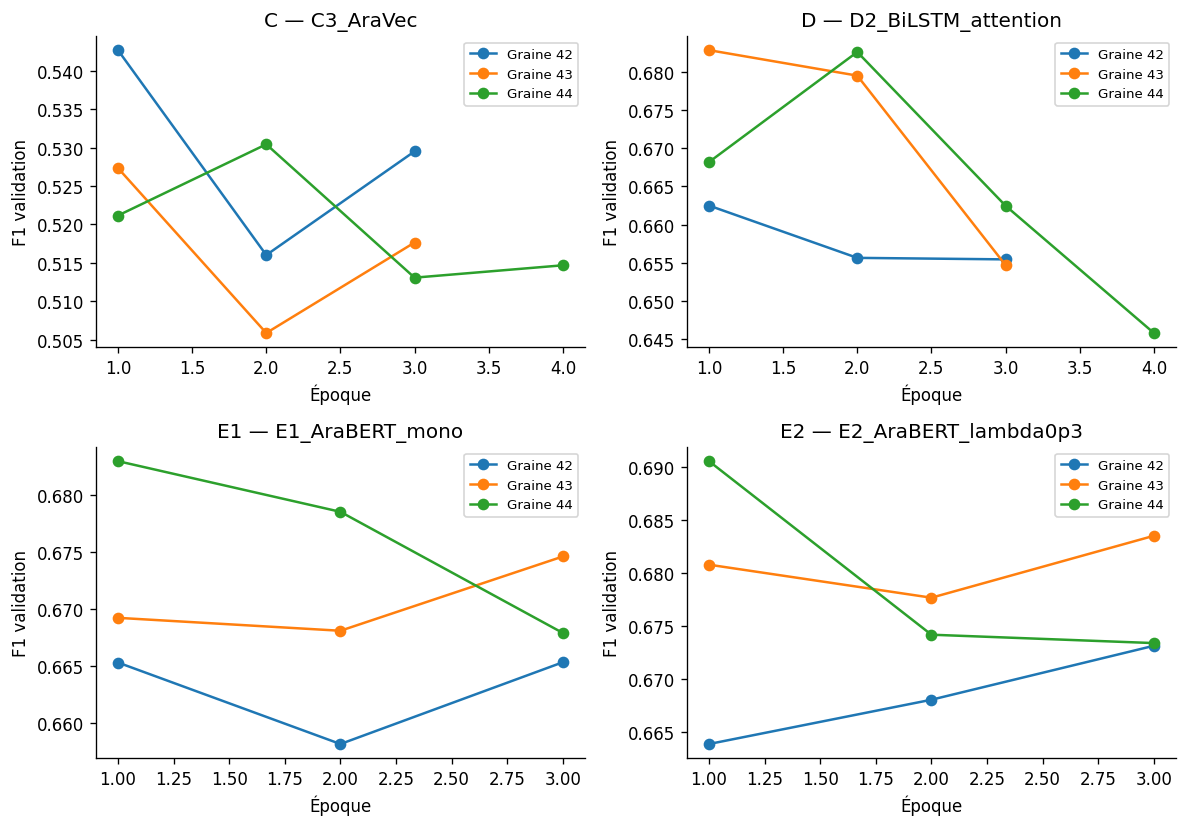

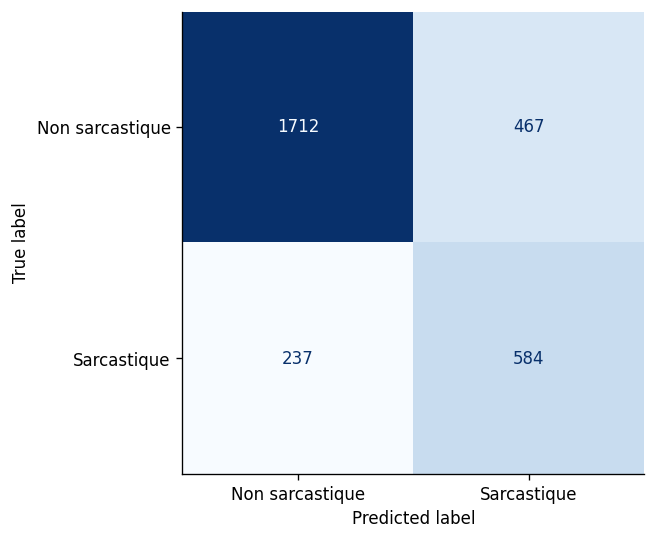

In [101]:
comparison=pd.DataFrame(comparison)

comparison.to_csv(ROOT/'results/final_comparison.csv',index=False)

display(comparison.round(4))

history_frame=pd.DataFrame(HISTORY)

fig,axes=plt.subplots(2,2,figsize=(10,7))

for ax,family in zip(axes.flat,['C','D','E1','E2']):
    model_name=REGISTRY[FINAL_GROUPS[family][0]]['name']
    curves=history_frame.loc[history_frame.model.eq(model_name)]
    for seed,curve in curves.groupby('seed'):
        ax.plot(curve.epoch,curve.val_f1,marker='o',label=f'Graine {seed}')
    if len(curves): ax.legend(fontsize=8)
    else: ax.text(.5,.5,'Classifieur linéaire sans époques',ha='center',transform=ax.transAxes)
    ax.set(title=f'{family} — {model_name}',xlabel='Époque',ylabel='F1 validation')

savefig(fig,'learning_curves_final')

fig,ax=plt.subplots(figsize=(6,5))

ConfusionMatrixDisplay.from_predictions(ytest,chosen_pred,display_labels=['Non sarcastique','Sarcastique'],cmap='Blues',ax=ax,colorbar=False)

### Cellule de code 102 — Présenter les erreurs globales et préparer la décision

**Objectif.** Rendre visibles les compromis des modèles au seuil déjà retenu.

**Comprendre le code.** La matrice reçoit son titre avec famille et seuil val, puis est sauvegardée. Le diagramme en barres montre la moyenne F1 test ; les barres d’erreur des familles entraînées représentent l’écart-type sur trois graines. Pour B1/B2, la valeur manquante est tracée sans barre, pas interprétée comme une variance connue nulle. Le dictionnaire `decision` réunit le choix fait sur val et ses métriques test.

**Résultat attendu à l’exécution.** Deux figures sont enregistrées et une décision traçable est préparée avec un horodatage de fin.

**À retenir.** La figure test expose le choix de validation ; elle ne doit pas conduire à déplacer après coup ce choix vers la barre la plus haute. Une recommandation réelle doit aussi considérer latence, taille et résultats F, notamment pour des tweets marocains.

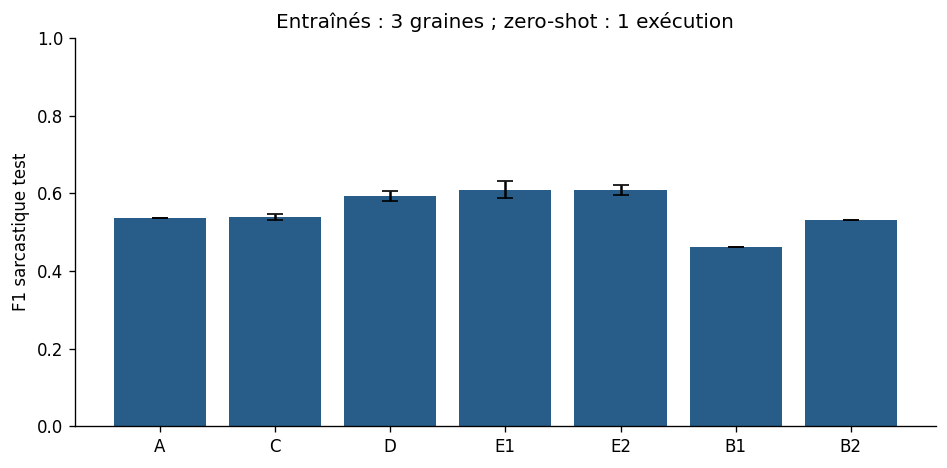

In [102]:
ax.set_title(f'Modèle retenu sur val : {chosen_final_family} — seuil {chosen_rec["threshold"]:.3f}')

savefig(fig,'chosen_confusion')

fig,ax=plt.subplots(figsize=(8,4))

ax.bar(comparison.family,comparison.test_f1_mean,yerr=comparison.test_f1_std.fillna(0),capsize=5,color='#275D88')

ax.set(ylabel='F1 sarcastique test',title='Entraînés : 3 graines ; zero-shot : 1 exécution',ylim=(0,1))

savefig(fig,'final_comparison')

decision={'chosen_key':CHOSEN_KEY,'family':chosen_final_family,'criterion':'moyenne F1 validation sur trois graines',
          'threshold':chosen_rec['threshold'],'test_metrics':scores(ytest,chosen_p,chosen_rec['threshold']),
          'completed_at_utc':datetime.now(timezone.utc).isoformat()}

### Cellule de code 103 — Sauvegarder la décision et le journal final

**Objectif.** Conserver une synthèse lisible sans dépendre de l’état du noyau Python.

**Comprendre le code.** `decision.json` contient le modèle, le seuil, le critère de choix et les mesures test. `results.csv` est réécrit avec les résultats et diagnostics réellement ajoutés pendant l’exécution. Les messages indiquent la référence retenue et où trouver les prédictions.

**Résultat attendu à l’exécution.** La décision et le journal final sont présents sous `ROOT/results/` ; le notebook affiche les métriques du modèle choisi.

**À retenir.** Ces messages n’ont de valeur que si les cellules précédentes se sont terminées sans erreur. Ils ne remplacent ni le contrôle des 17 fichiers de prédictions ni la relecture qualitative des erreurs et du compte rendu.

In [103]:
(ROOT/'results/decision.json').write_text(json.dumps(decision,indent=2),encoding='utf-8')

pd.DataFrame(RESULTS).to_csv(ROOT/'results/results.csv',index=False)

print('Modèle retenu :',CHOSEN_KEY,'seuil',chosen_rec['threshold'])

print('Scores test :',decision['test_metrics'])

print('Toutes les prédictions finales exportées dans predictions/.')

Modèle retenu : E2_AraBERT_lambda0p3_seed42 seuil 0.49078473448753357
Scores test : {'f1_sarcastique': 0.6239316239316239, 'precision': 0.5556612749762131, 'recall': 0.7113276492082826, 'macro_f1': 0.7266944941363547, 'pr_auc_ap': 0.6355033706345491}
Toutes les prédictions finales exportées dans predictions/.


## 5 Réponses pédagogiques aux questions Q1 à Q12

Le compte rendu séparé reprend les chiffres de cette exécution. Les principes suivants
permettent de lire les résultats sans confondre apprentissage, sélection et évaluation.

**Q1** Le tableau des taux montre le déséquilibre et le prior de chaque partition. « Jamais
sarcastique » obtient accuracy = 1 − prior mais F1 sarcastique = 0. On retient F1 sarcastique,
AP et macro F1 ; l'accuracy seule cache l'échec de la détection minoritaire.

**Q2** Les guillemets d'export, URL et mentions peuvent refléter la source ou la collecte.
La règle d'un seul indice mesure leur pouvoir prédictif. Une corrélation forte n'établit pas
la compréhension de l'ironie ; il faut comparer les sous-groupes et les ablations sans liens.

**Q3** Le TF IDF et les réseaux statiques reçoivent la normalisation conservatrice ; les PLM
conservent davantage la graphie et AraBERT reçoit son préprocesseur officiel. La comparaison
avec la version agressive et F4 quantifient le coût du retrait des indices. Une suppression
systématique des emojis, rires, négations et ponctuations serait injustifiée.

**Q4** Le NLI reformule la classification comme une relation entre prémisse et hypothèse.
Le score d'entailment mesure leur compatibilité, et l'auto attention relie les deux segments.
La sensibilité arabe/français/anglais est mesurée sur val ; c'est une forme d'adaptation
au domaine par sélection du prompt, même sans gradient sur ArSarcasm.

**Q5** Négativité et sarcasme ne sont pas équivalents : une plainte sincère est négative,
une louange ironique peut être sarcastique. Précision et rappel de B2 quantifient la confusion.
Le chevauchement potentiel ASTD/SemEval interdit de présenter B2 comme test vierge garanti.

**Q6** Pondérer modifie le coût des erreurs ; rééchantillonner modifie la fréquence des exemples ;
déplacer le seuil modifie la décision après apprentissage. Avant la séparation, le suréchantillonnage
pourrait dupliquer un tweet dans train et val et fausser le score. Le tableau commun isole ces effets.

**Q7** BiLSTM traite l'ordre de manière récurrente, l'attention pondère ses états, le Transformer
relie toutes les positions. Sans encodage positionnel, le pooling ne connaît plus l'ordre.
Les visualisations D2 décrivent les tokens pondérés, sans établir une explication causale.
C4 est explicitement optionnel dans le sujet et n'est pas nécessaire à la comparaison C1–C3.

**Q8** Gelé : l'encodeur ne s'adapte pas, la tête coûte peu à entraîner mais l'encodeur reste
nécessaire à l'inférence. Fine tuning : toutes ses représentations peuvent changer, avec
plus de coût et de variance. AraBERT contre MARBERT se juge sur les mesures, pas leur réputation.

**Q9** La tâche sentiment peut régulariser un encodeur partagé et apporter du signal. Elle peut
aussi nuire si son gradient domine ou si les annotations sont imparfaites. Les lambda sont
comparés sur val et le meilleur est répété ; le test n'intervient pas dans leur choix.

**Q10** Le seuil a posteriori test donne une borne descriptive optimiste, pas un réglage déployable.
En production : surveiller prior, dérive de vocabulaire, dialecte et calibration ; annoter un
lot récent indépendant pour recalibrer, puis l'évaluer sur un autre lot temporel.

**Q11** Le tableau donne les effectifs magreb exacts. Magreb regroupe plusieurs pays, sans garantir
le Maroc. Un test marocain nécessite darija, Arabizi, mélange français/arabe, sources nouvelles,
dates nouvelles et annotation multi juge. L'ablation egypt mesure une généralisation dialectale
mais ne prouve pas celle au Maroc ; train et validation égyptiens sont exclus des décisions F2.

**Q12** Trente erreurs sont montrées avec hypothèses explicites. Les catégories sémantiques
exigent une relecture humaine ; un marqueur seul ne prouve pas le sarcasme et une absence de
marqueur n'est pas une preuve de non sarcasme. La recommandation finale compare qualité,
incertitude, latence CPU et taille complète des poids, puis expose les limites de domaine.

## 6 Reproductibilité et limites

Les CSV sources et leurs SHA256 sont dans `data/raw/manifest.json`, les révisions des PLM
dans `models/revisions.json`, les identifiants des partitions dans `data/processed/`, les
expériences dans `results/results.csv`, les seuils verrouillés dans `results/final_manifest.json`.
La graine ne garantit pas une identité bit à bit entre matériels et versions différentes.
Les IC par tweet ne corrigent pas tous les effets de provenance ; plusieurs essais sur val
peuvent la surajuster ; il faut une évaluation externe avant toute revendication de production.
Les résultats ne sont pas des scores universels de compréhension de l'arabe.

### Cellule de code 104 — Consigner les versions et vérifier les livrables calculés

**Objectif.** Terminer par des assertions qui bloquent une déclaration de fin incohérente.

**Comprendre le code.** Les versions des bibliothèques principales sont enregistrées sans réécrire les dépendances figées. Le dictionnaire `checks` vérifie les clés disjointes entre partitions, les 3 000 lignes test, trois clés par famille finale et la présence des fichiers de prédictions. Si un contrôle est faux, l’assertion interrompt la cellule. Un JSON conserve les contrôles et le chemin Python.

**Résultat attendu à l’exécution.** Un tableau de booléens et `validation_checks.json` documentent la cohérence de l’exécution scientifique.

**À retenir.** La présence d’un fichier ne garantit pas son contenu : le contrôle final externe recalcule aussi les métriques et vérifie les compteurs du notebook. Après sauvegarde, utiliser les commandes de synchronisation et de rapport indiquées dans la dernière section ; ne pas annoncer une exécution complète avant ces vérifications.

In [104]:
import importlib.metadata as metadata

packages=['torch','transformers','huggingface-hub','safetensors','tokenizers','scikit-learn','numpy','pandas','scipy','gensim','arabert','pyarabic','emoji','sentencepiece','nbformat','ipykernel','matplotlib','joblib','reportlab','pymupdf']

versions={p:metadata.version(p) for p in packages}

(ROOT/'results/runtime_versions.json').write_text(json.dumps(versions,indent=2))

checks={'train_val_disjoint':set(train.key).isdisjoint(val.key),'train_test_disjoint':set(train.key).isdisjoint(test.key),
    'val_test_disjoint':set(val.key).isdisjoint(test.key),
    'test_official_count':len(test)==3000,'three_seeds_per_final_family':all(len(keys)==3 for keys in FINAL_GROUPS.values()),
    'final_prediction_files':all((ROOT/f'predictions/{key}.csv').exists() for key in FINAL_KEYS)}

assert all(checks.values()),checks

(ROOT/'results/validation_checks.json').write_text(json.dumps({'checks':checks,'versions':versions,'python':sys.executable},indent=2))

display(pd.Series(checks).to_frame('Vérifié'))

print('Calcul scientifique terminé. Régénérer le PDF : python -m src.report ; puis python -m tests.verify_final')

,Vérifié
train_val_disjoint,True
train_test_disjoint,True
val_test_disjoint,True
test_official_count,True
three_seeds_per_final_family,True
final_prediction_files,True


Calcul scientifique terminé. Régénérer le PDF : python -m src.report ; puis python -m tests.verify_final


### Contrôler et rendre le dépôt

Après votre exécution, sauvegarder `notebooks/TP2_Sarcasme_Arabe_T4.ipynb`, puis depuis la racine du dépôt :

```powershell
python -m src.report
python -m tests.verify_final
```

Le rapport lit `results/` et `figures/` et actualise le compte rendu PDF à la racine. Le contrôle final vérifie les sorties sauvegardées et les prédictions sans entraîner ni relancer les modèles. Il refuse de déclarer le TP terminé tant que les expériences obligatoires manquent. Relire le PDF, annoter humainement les 30 erreurs et renseigner identité, groupe et lien Git avant remise.